Imports

In [1]:
import os
import random
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

Setting reproducibility

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

Device: cuda


Loading the PMSM dataset

In [4]:
candidate_roots = [os.path.abspath(os.getcwd()), os.path.abspath(os.path.join(os.getcwd(), os.pardir))]
DATA_PATH = next((candidate for root in candidate_roots
    for candidate in (os.path.join(root, "dataset", "measures_v2.csv"), os.path.join(root, "measures_v2.csv"))
    if os.path.isfile(candidate)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find dataset/measures_v2.csv from the notebook directory or its parent.")
print("Using dataset:", DATA_PATH)

df = pd.read_csv(DATA_PATH)

print(df.shape)
display(df.head())

Using dataset: d:\Work space\PIML_Motor\measures_v2.csv
(1330816, 13)


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.086670,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17
1,-0.325737,18.818571,19.092390,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17
2,-0.440864,18.828770,19.089380,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17
3,-0.327026,18.835567,19.083031,-0.316199,18.292542,0.006105,0.000026,0.002046,24.554018,18.330833,19.850647,0.238303,17
4,-0.471150,18.857033,19.082525,-0.332272,18.291428,0.003133,-0.064317,0.037184,24.565397,18.326662,19.850639,0.208197,17


In [5]:
print(df.columns.tolist())

['u_q', 'coolant', 'stator_winding', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'pm', 'stator_yoke', 'ambient', 'torque', 'profile_id']


In [6]:
TARGET = "pm"

print(df[TARGET].describe())

count    1.330816e+06
mean     5.850678e+01
std      1.900150e+01
min      2.085696e+01
25%      4.315158e+01
50%      6.026629e+01
75%      7.200837e+01
max      1.136066e+02
Name: pm, dtype: float64


In [7]:
print("PM:")
print(df["pm"].describe())

print("\nStator winding:")
print(df["stator_winding"].describe())

print("\nStator tooth:")
print(df["stator_tooth"].describe())

print("\nStator yoke:")
print(df["stator_yoke"].describe())

PM:
count    1.330816e+06
mean     5.850678e+01
std      1.900150e+01
min      2.085696e+01
25%      4.315158e+01
50%      6.026629e+01
75%      7.200837e+01
max      1.136066e+02
Name: pm, dtype: float64

Stator winding:
count    1.330816e+06
mean     6.634275e+01
std      2.867206e+01
min      1.858582e+01
25%      4.278796e+01
50%      6.511013e+01
75%      8.814114e+01
max      1.413629e+02
Name: stator_winding, dtype: float64

Stator tooth:
count    1.330816e+06
mean     5.687858e+01
std      2.295223e+01
min      1.813398e+01
25%      3.841601e+01
50%      5.603635e+01
75%      7.558668e+01
max      1.119464e+02
Name: stator_tooth, dtype: float64

Stator yoke:
count    1.330816e+06
mean     4.818796e+01
std      1.999100e+01
min      1.807669e+01
25%      3.199033e+01
50%      4.562551e+01
75%      6.146083e+01
max      1.011480e+02
Name: stator_yoke, dtype: float64


In [8]:
temperature_columns = [
    "pm",
    "stator_winding",
    "stator_tooth",
    "stator_yoke"
]

display(
    df[temperature_columns].corr()
)

,pm,stator_winding,stator_tooth,stator_yoke
pm,1.000000,0.795893,0.832084,0.756684
stator_winding,0.795893,1.000000,0.970135,0.860268
stator_tooth,0.832084,0.970135,1.000000,0.953115
stator_yoke,0.756684,0.860268,0.953115,1.000000


In [9]:
display(
    df[
        [
            "pm",
            "stator_winding",
            "stator_tooth",
            "stator_yoke",
            "ambient",
            "coolant",
            "profile_id"
        ]
    ].head(20)
)

,pm,stator_winding,stator_tooth,stator_yoke,ambient,coolant,profile_id
0,24.554214,19.086670,18.293219,18.316547,19.850691,18.805172,17
1,24.538078,19.092390,18.294807,18.314955,19.850672,18.818571,17
2,24.544693,19.089380,18.294094,18.326307,19.850657,18.828770,17
3,24.554018,19.083031,18.292542,18.330833,19.850647,18.835567,17
4,24.565397,19.082525,18.291428,18.326662,19.850639,18.857033,17
5,24.573601,19.077108,18.290628,18.323862,19.850634,18.901548,17
6,24.576578,19.074583,18.292524,18.321936,19.850630,18.941711,17
7,24.574949,19.082499,18.294041,18.314655,19.850628,18.960861,17
8,24.567080,19.085533,18.291964,18.306925,19.850626,18.973545,17
9,24.553242,19.076025,18.287233,18.301733,19.850624,18.987812,17


In [10]:
print("Number of unique profiles:")
print(df["profile_id"].nunique())

print("\nProfile IDs:")
print(sorted(df["profile_id"].unique()))

print("\nSamples per profile:")
display(
    df["profile_id"]
    .value_counts()
    .sort_index()
)

Number of unique profiles:
69

Profile IDs:
[np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(23), np.int64(24), np.int64(26), np.int64(27), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(36), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.int64(71), np.int64(72), np.int64(73), np.int64(74), np.int64(75), np.int64(76), np.int64(78), np.int64(79), np.int64(80), np.int64(81

profile_id
2     19357
3     19248
4     33424
5     14788
6     40388
      ...  
76    22188
78     8445
79    31154
80    23824
81    17672
Name: count, Length: 69, dtype: int64

In [11]:
profile_stats = (
    df.groupby("profile_id")["pm"]
    .agg(
        samples="count",
        min_temp="min",
        max_temp="max",
        mean_temp="mean",
        std_temp="std"
    )
    .sort_index()
)

display(profile_stats)

,samples,min_temp,max_temp,mean_temp,std_temp
profile_id,,,,,
2,19357,22.970417,45.985561,32.759597,7.544091
3,19248,22.751144,29.011612,26.285130,2.045192
4,33424,22.924950,99.396629,49.762076,15.962284
5,14788,25.889381,39.938965,33.213100,4.149520
6,40388,24.349821,93.512962,69.232339,14.013539
...,...,...,...,...,...
76,22188,31.433067,82.554532,67.596298,9.251639
78,8445,21.266710,68.029359,55.021131,9.217807
79,31154,25.551253,97.153271,68.716465,11.726192


In [12]:
print(df.groupby("profile_id")[
    ["i_d", "i_q", "motor_speed", "torque",
    "coolant", "ambient", "pm"]
].mean())

                   i_d        i_q  motor_speed     torque    coolant  \
profile_id                                                             
2           -48.212822  93.315905   100.000216  79.148595  18.542054   
3           -22.684171  66.636316    99.996061  51.692367  18.761891   
4           -52.435694  40.571468  2683.072902  32.835482  18.626801   
5           -19.476087  56.473858   999.990768  43.519544  18.801043   
6          -101.816880  16.833996  3445.307672  15.345794  29.022098   
...                ...        ...          ...        ...        ...   
76          -54.585210   1.923519  1947.545367   1.193692  54.300834   
78          -55.514796   2.274921  1876.569539   2.607439  51.329973   
79          -59.743103 -12.986380  2088.108155 -10.334681  54.419152   
80          -61.718078  -1.037632  2061.940867  -0.771954  54.703200   
81          -27.460926   0.181498   992.836397  -0.580884  58.324510   

              ambient         pm  
profile_id                  

Physics features

In [13]:

# BLOCK 5 â€” PHYSICS FEATURE ENGINEERING


df = df.copy()


# 1. Current magnitude
# I = sqrt(id^2 + iq^2)


df["I_mag"] = np.sqrt(
    df["i_d"]**2 +
    df["i_q"]**2
)



# 2. Voltage magnitude
# V = sqrt(ud^2 + uq^2)


df["V_mag"] = np.sqrt(
    df["u_d"]**2 +
    df["u_q"]**2
)



# 3. Electrical power
# P_elec = ud*id + uq*iq


df["P_elec"] = (
    df["u_d"] * df["i_d"] +
    df["u_q"] * df["i_q"]
)


# 4. Angular velocity
# Assuming motor_speed is RPM
# omega = 2*pi*N/60


df["omega"] = (
    2 * np.pi *
    df["motor_speed"] /
    60
)



# 5. Mechanical power
# P_mech = Torque * omega


df["P_mech"] = (
    df["torque"] *
    df["omega"]
)



# 6. Copper loss
# P_cu = I^2 * Rs

# Imp I have arbitrarily chosen a value for Rs, as it is not provided in the dataset. In a real-world scenario, this value should be determined based on the specific motor's characteristics.
R_S = 0.05

df["P_cu"] = (
    df["I_mag"]**2 *
    R_S
)



# 7. Thermal gradients


df["T_ambient"] = df["ambient"]

df["T_coolant"] = df["coolant"]

df["pm_ambient_delta"] = (
    df["pm"] -
    df["ambient"]
)

df["pm_coolant_delta"] = (
    df["pm"] -
    df["coolant"]
)


# Check


display(
    df[
        [
            "i_d",
            "i_q",
            "I_mag",
            "u_d",
            "u_q",
            "V_mag",
            "motor_speed",
            "omega",
            "torque",
            "P_elec",
            "P_mech",
            "P_cu",
            "ambient",
            "coolant",
            "pm"
        ]
    ].head(10)
)

,i_d,i_q,I_mag,u_d,u_q,V_mag,motor_speed,omega,torque,P_elec,P_mech,P_cu,ambient,coolant,pm
0,0.004419,0.000328,0.004431,-0.350055,-0.450682,0.570659,0.002866,0.000300,0.187101,-0.001695,0.000056,9.818211e-07,19.850691,18.805172,24.554214
1,0.000606,-0.000785,0.000992,-0.305803,-0.325737,0.446789,0.000257,0.000027,0.245417,0.000071,0.000007,4.919301e-08,19.850672,18.818571,24.538078
2,0.001290,0.000386,0.001346,-0.372503,-0.440864,0.577165,0.002355,0.000247,0.176615,-0.000651,0.000044,9.061963e-08,19.850657,18.828770,24.544693
3,0.000026,0.002046,0.002046,-0.316199,-0.327026,0.454893,0.006105,0.000639,0.238303,-0.000677,0.000152,2.092692e-07,19.850647,18.835567,24.554018
4,-0.064317,0.037184,0.074292,-0.332272,-0.471150,0.576530,0.003133,0.000328,0.208197,0.003852,0.000068,2.759641e-04,19.850639,18.857033,24.565397
5,-0.613635,0.336747,0.699962,0.009147,-0.538973,0.539050,0.009636,0.001009,0.476218,-0.187111,0.000481,2.449735e-02,19.850634,18.901548,24.573601
6,-1.005647,0.554211,1.148249,0.238890,-0.653148,0.695465,0.001337,0.000140,0.670015,-0.602221,0.000094,6.592383e-02,19.850630,18.941711,24.576578
7,-1.288384,0.706370,1.469317,0.395099,-0.758392,0.855138,0.001422,0.000149,0.752035,-1.044744,0.000112,1.079446e-01,19.850628,18.960861,24.574949
8,-1.490530,0.817339,1.699919,0.546623,-0.727128,0.909677,0.000577,0.000060,0.910541,-1.409068,0.000055,1.444862e-01,19.850626,18.973545,24.567080
9,-1.634464,0.898013,1.864912,0.578944,-0.874307,1.048613,-0.001248,-0.000131,0.924010,-1.731402,-0.000121,1.738949e-01,19.850624,18.987812,24.553242


In [14]:
physics_cols = [
    "I_mag",
    "V_mag",
    "P_elec",
    "P_mech",
    "P_cu",
    "pm",
    "ambient",
    "coolant"
]

display(
    df[physics_cols].describe().T
)

,count,mean,std,min,25%,50%,75%,max
I_mag,1330816.0,107.544575,85.262537,3.922213e-05,11.828189,110.620016,172.141884,361.515337
V_mag,1330816.0,81.640420,53.335070,1.732221e-06,18.900277,107.709120,130.782849,134.264098
P_elec,1330816.0,5087.225508,12388.694858,-3.101164e+04,-3.129282,971.726985,14150.307913,34981.092999
P_mech,1330816.0,6513.603236,18580.971923,-5.526779e+04,-26.937972,1027.488385,20439.095479,49618.186920
P_cu,1330816.0,941.776518,1081.810063,7.691878e-11,6.995303,611.839394,1481.641415,6534.666938
pm,1330816.0,58.506776,19.001498,2.085696e+01,43.151582,60.266287,72.008371,113.606628
ambient,1330816.0,24.565256,1.929522,8.783478e+00,23.184804,24.797327,26.217019,30.714205
coolant,1330816.0,36.229995,21.786149,1.062375e+01,18.698135,26.900141,49.857487,101.598512


In [15]:
display(
    df[physics_cols]
    .corr()["pm"]
    .sort_values(
        ascending=False
    )
)

pm         1.000000
ambient    0.513728
coolant    0.467117
V_mag      0.394572
I_mag      0.251782
P_cu       0.194399
P_elec     0.184477
P_mech     0.162600
Name: pm, dtype: float64

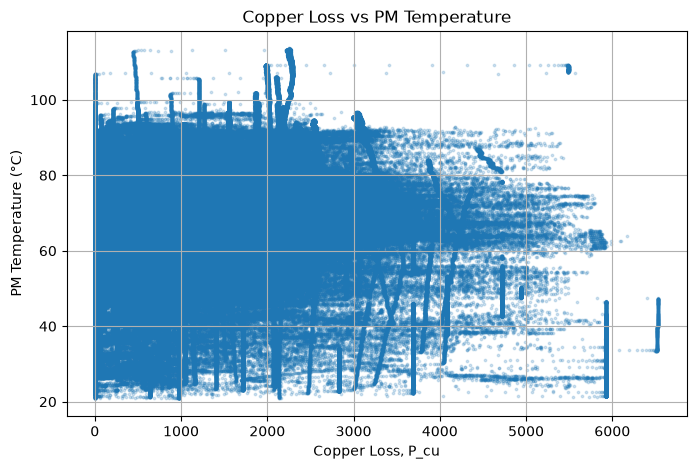

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["P_cu"],
    df["pm"],
    s=3,
    alpha=0.2
)

plt.xlabel("Copper Loss, P_cu")
plt.ylabel("PM Temperature (Â°C)")
plt.title(
    "Copper Loss vs PM Temperature"
)

plt.grid(True)
plt.show()

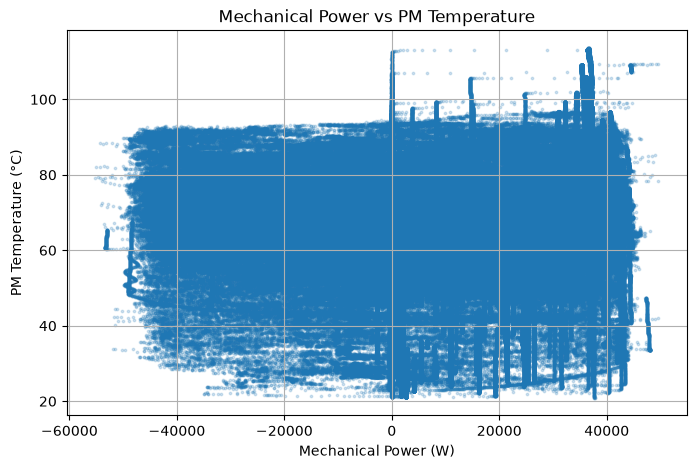

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["P_mech"],
    df["pm"],
    s=3,
    alpha=0.2
)

plt.xlabel("Mechanical Power (W)")
plt.ylabel("PM Temperature (Â°C)")
plt.title(
    "Mechanical Power vs PM Temperature"
)

plt.grid(True)
plt.show()

Copper loss vs PM temperature

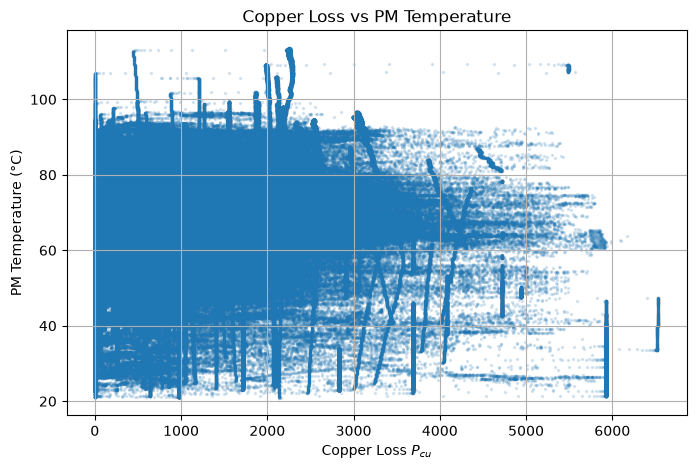

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["P_cu"],
    df["pm"],
    s=2,
    alpha=0.15
)

plt.xlabel("Copper Loss $P_{cu}$")
plt.ylabel("PM Temperature (Â°C)")
plt.title("Copper Loss vs PM Temperature")

plt.grid(True)
plt.show()

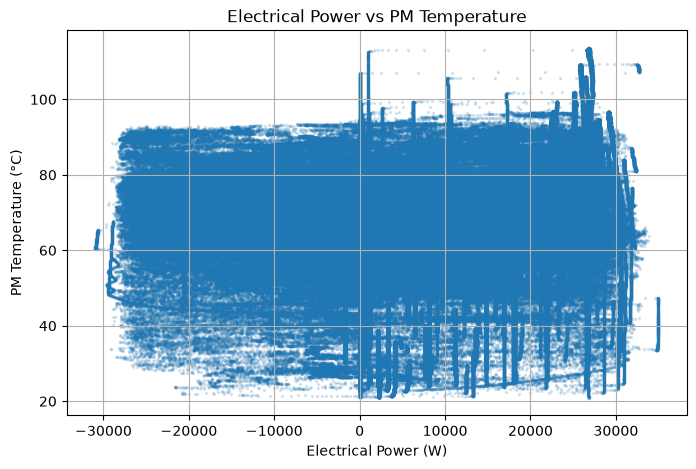

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["P_elec"],
    df["pm"],
    s=2,
    alpha=0.15
)

plt.xlabel("Electrical Power (W)")
plt.ylabel("PM Temperature (Â°C)")
plt.title("Electrical Power vs PM Temperature")

plt.grid(True)
plt.show()

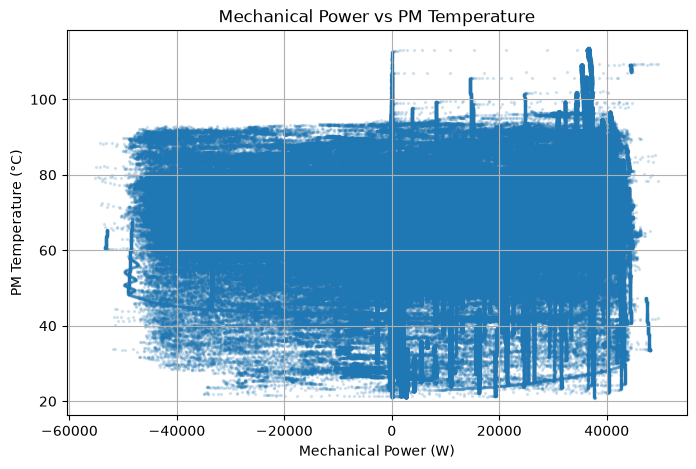

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["P_mech"],
    df["pm"],
    s=2,
    alpha=0.15
)

plt.xlabel("Mechanical Power (W)")
plt.ylabel("PM Temperature (Â°C)")
plt.title("Mechanical Power vs PM Temperature")

plt.grid(True)
plt.show()

In [21]:
profile_id = 4

profile_df = (
    df[df["profile_id"] == profile_id]
    .reset_index(drop=True)
)

print(profile_df.shape)

(33424, 23)


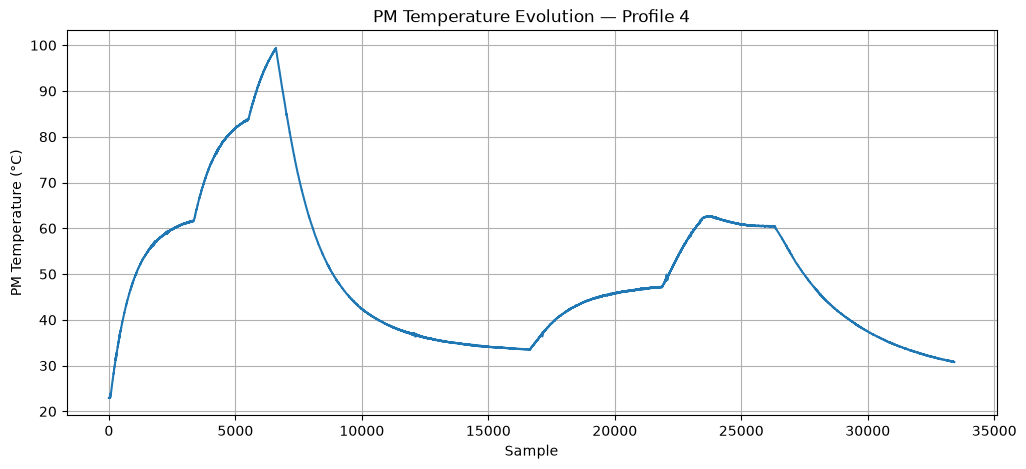

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    profile_df["pm"].values
)

plt.xlabel("Sample")
plt.ylabel("PM Temperature (Â°C)")
plt.title(
    f"PM Temperature Evolution â€” Profile {profile_id}"
)

plt.grid(True)
plt.show()

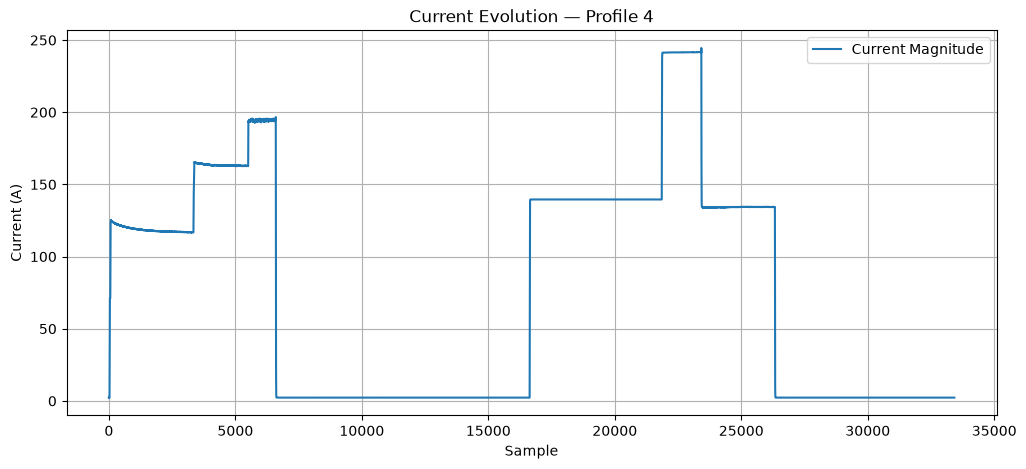

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(
    profile_df["I_mag"].values,
    label="Current Magnitude"
)

plt.xlabel("Sample")
plt.ylabel("Current (A)")
plt.title(
    f"Current Evolution â€” Profile {profile_id}"
)

plt.grid(True)
plt.legend()
plt.show()

Calculate the temperature change

In [24]:
df["pm_delta"] = (
    df.groupby("profile_id")["pm"]
    .diff()
)

In [25]:
print(
    df["pm_delta"].describe()
)

count    1.330747e+06
mean     1.338509e-03
std      8.741568e-02
min     -4.340640e+00
25%     -1.276398e-02
50%     -1.457214e-03
75%      1.223901e-02
max      5.294013e+00
Name: pm_delta, dtype: float64


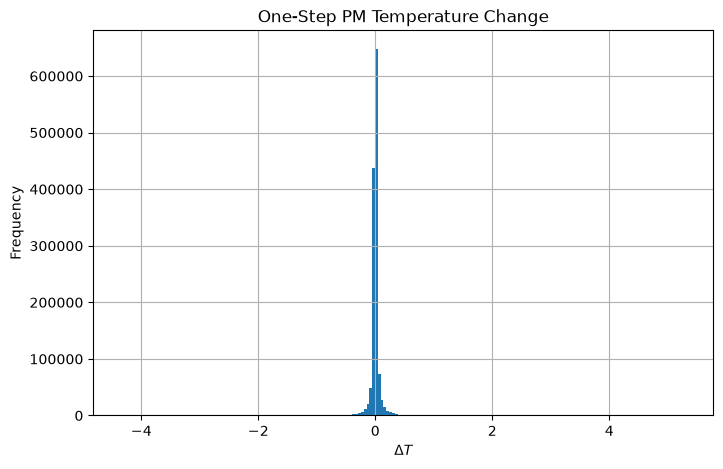

In [26]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["pm_delta"].dropna(),
    bins=200
)

plt.xlabel(r"$\Delta T$")
plt.ylabel("Frequency")
plt.title("One-Step PM Temperature Change")

plt.grid(True)
plt.show()

The sampling interval

In [27]:
print(df.columns.tolist())

['u_q', 'coolant', 'stator_winding', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'pm', 'stator_yoke', 'ambient', 'torque', 'profile_id', 'I_mag', 'V_mag', 'P_elec', 'omega', 'P_mech', 'P_cu', 'T_ambient', 'T_coolant', 'pm_ambient_delta', 'pm_coolant_delta', 'pm_delta']


In [28]:
profile_lengths = (
    df.groupby("profile_id")
    .size()
)

print(profile_lengths.describe())

count       69.000000
mean     19287.188406
std       9606.729772
min       2176.000000
25%      14403.000000
50%      17142.000000
75%      23761.000000
max      43971.000000
dtype: float64


In [29]:
print(
    "Median samples/profile:",
    profile_lengths.median()
)

print(
    "Minimum samples/profile:",
    profile_lengths.min()
)

print(
    "Maximum samples/profile:",
    profile_lengths.max()
)

Median samples/profile: 17142.0
Minimum samples/profile: 2176
Maximum samples/profile: 43971


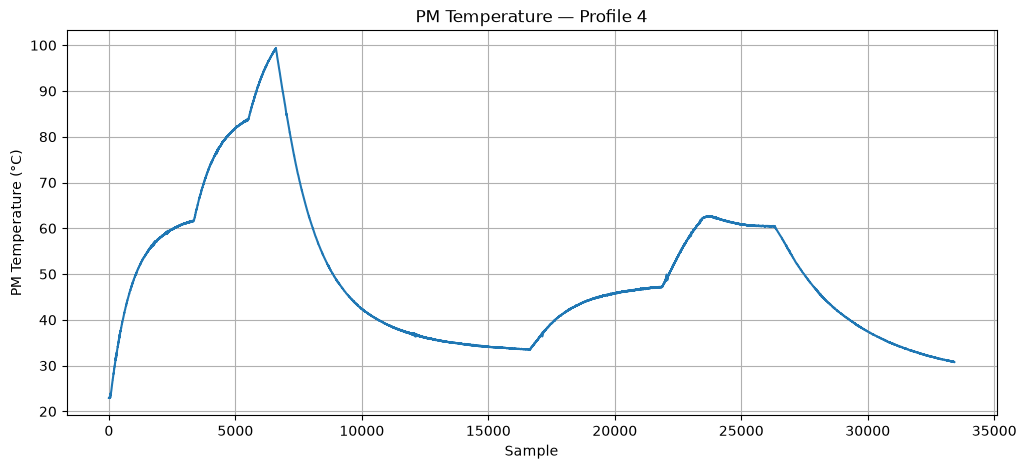

In [30]:
profile_id = 4

p = (
    df[df["profile_id"] == profile_id]
    .reset_index(drop=True)
)

plt.figure(figsize=(12, 5))

plt.plot(
    p["pm"].values
)

plt.xlabel("Sample")
plt.ylabel("PM Temperature (Â°C)")
plt.title(
    f"PM Temperature â€” Profile {profile_id}"
)

plt.grid(True)
plt.show()

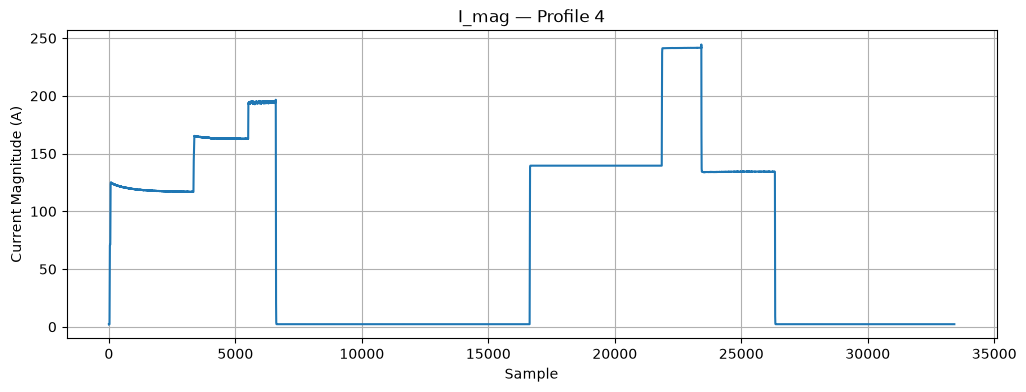

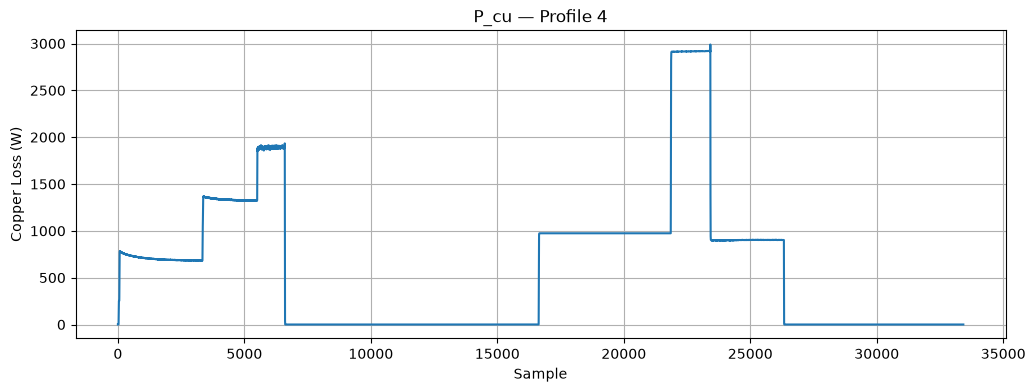

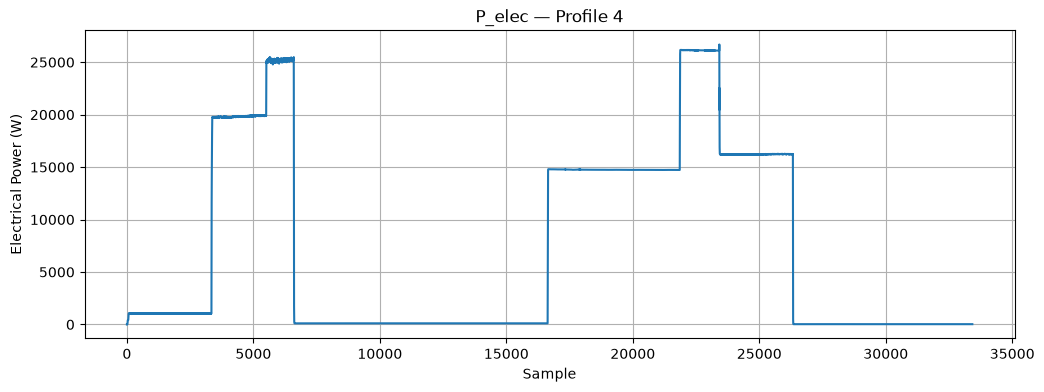

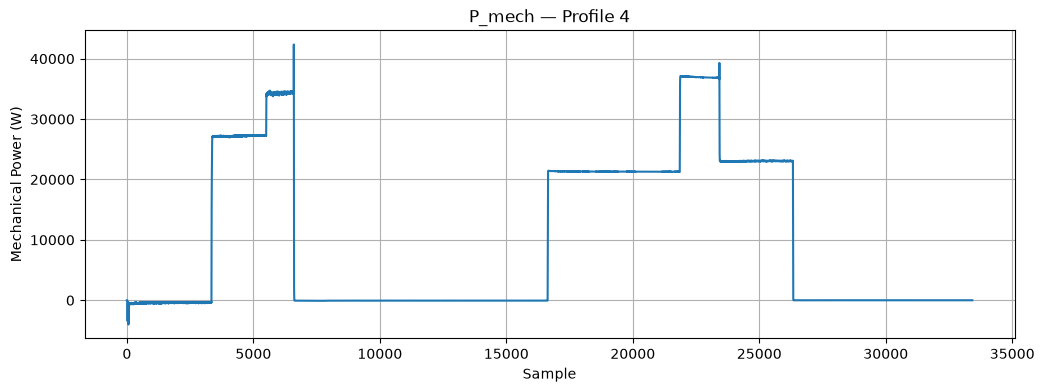

In [31]:
figures = [
    ("I_mag", "Current Magnitude (A)"),
    ("P_cu", "Copper Loss (W)"),
    ("P_elec", "Electrical Power (W)"),
    ("P_mech", "Mechanical Power (W)")
]

for column, ylabel in figures:

    plt.figure(figsize=(12, 4))

    plt.plot(
        p[column].values
    )

    plt.xlabel("Sample")
    plt.ylabel(ylabel)

    plt.title(
        f"{column} â€” Profile {profile_id}"
    )

    plt.grid(True)

    plt.show()

In [32]:
print("All columns:")
print(df.columns.tolist())

print("\nDataFrame index:")
print(df.index[:10])

print("\nIndex type:")
print(type(df.index))

All columns:
['u_q', 'coolant', 'stator_winding', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'pm', 'stator_yoke', 'ambient', 'torque', 'profile_id', 'I_mag', 'V_mag', 'P_elec', 'omega', 'P_mech', 'P_cu', 'T_ambient', 'T_coolant', 'pm_ambient_delta', 'pm_coolant_delta', 'pm_delta']

DataFrame index:
RangeIndex(start=0, stop=10, step=1)

Index type:
<class 'pandas.RangeIndex'>


In [33]:
if isinstance(df.index, pd.DatetimeIndex):
    print("Datetime index detected.")
    print("Sampling interval:")
    print(df.index.to_series().diff().describe())
else:
    print("Index is not a DatetimeIndex.")

Index is not a DatetimeIndex.


In [34]:
profile_id = 4

p = (
    df[df["profile_id"] == profile_id]
    .reset_index(drop=True)
)

print("Profile:", profile_id)
print("Samples:", len(p))

print("\nFirst PM temperatures:")
print(p["pm"].head(10).values)

print("\nLast PM temperatures:")
print(p["pm"].tail(10).values)

print("\nTemperature change:")
print(
    p["pm"].iloc[-1] -
    p["pm"].iloc[0]
)

Profile: 4
Samples: 33424

First PM temperatures:
[22.95905685 22.95355034 22.94949722 22.96591568 22.9617691  22.95696068
 22.9516449  22.94678497 22.94735527 22.94944   ]

Last PM temperatures:
[30.80928993 30.81051445 30.80555534 30.80946922 30.81960487 30.81874466
 30.80321121 30.79500771 30.79237366 30.78956032]

Temperature change:
7.830503463745117


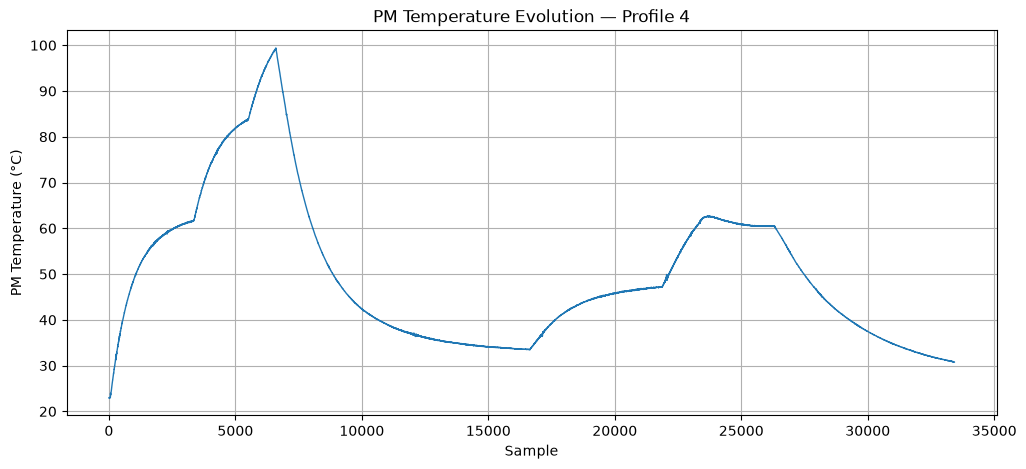

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(
    p["pm"].values,
    linewidth=1
)

plt.xlabel("Sample")
plt.ylabel("PM Temperature (Â°C)")
plt.title(
    f"PM Temperature Evolution â€” Profile {profile_id}"
)

plt.grid(True)
plt.show()

Profile-wise train/validation/test split

In [36]:


from sklearn.model_selection import train_test_split

# All unique profile IDs
profile_ids = df["profile_id"].unique()

print("Total profiles:", len(profile_ids))

# ------------------------------------------
# First split:
# 70% train, 30% temporary
# ------------------------------------------

train_profiles, temp_profiles = train_test_split(
    profile_ids,
    test_size=0.30,
    random_state=42
)

# ------------------------------------------
# Second split:
# temporary -> validation + test
# ------------------------------------------

val_profiles, test_profiles = train_test_split(
    temp_profiles,
    test_size=0.50,
    random_state=42
)

print("\nTrain profiles:", len(train_profiles))
print("Validation profiles:", len(val_profiles))
print("Test profiles:", len(test_profiles))

print("\nTrain:", sorted(train_profiles))
print("\nValidation:", sorted(val_profiles))
print("\nTest:", sorted(test_profiles))

Total profiles: 69

Train profiles: 48
Validation profiles: 10
Test profiles: 11

Train: [np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(18), np.int64(19), np.int64(20), np.int64(23), np.int64(24), np.int64(26), np.int64(29), np.int64(30), np.int64(32), np.int64(36), np.int64(42), np.int64(43), np.int64(44), np.int64(46), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(62), np.int64(63), np.int64(64), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.int64(72), np.int64(73), np.int64(74), np.int64(78), np.int64(79), np.int64(80), np.int64(81)]

Validation: [np.int64(9), np.int64(10), np.int64(27), np.int64(41), np.int64(48), np.int64(50), np.int64(61), np.int64(65), np.int64(71), np.int64(76)]

Test: [np.int64(2), np.int64(3), np.int64(8), np.int64(17), np.int64(21), np.int64(31), 

Creating the actual datasets

In [37]:


train_df = df[
    df["profile_id"].isin(train_profiles)
].copy()

val_df = df[
    df["profile_id"].isin(val_profiles)
].copy()

test_df = df[
    df["profile_id"].isin(test_profiles)
].copy()

print("Train samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

Train samples: 932600
Validation samples: 211900
Test samples: 186316


In [38]:
print(
    "Train profiles:",
    train_df["profile_id"].nunique()
)

print(
    "Validation profiles:",
    val_df["profile_id"].nunique()
)

print(
    "Test profiles:",
    test_df["profile_id"].nunique()
)

Train profiles: 48
Validation profiles: 10
Test profiles: 11


In [39]:

# LEAKAGE CHECK


train_set = set(train_profiles)
val_set = set(val_profiles)
test_set = set(test_profiles)

print(
    "Train âˆ© Validation:",
    train_set.intersection(val_set)
)

print(
    "Train âˆ© Test:",
    train_set.intersection(test_set)
)

print(
    "Validation âˆ© Test:",
    val_set.intersection(test_set)
)

Train âˆ© Validation: set()
Train âˆ© Test: set()
Validation âˆ© Test: set()


In [40]:

# BLOCK 7.3 â€” TEMPERATURE RANGE BY SPLIT


print("TRAIN")
print(
    train_df["pm"].describe()
)

print("\nVALIDATION")
print(
    val_df["pm"].describe()
)

print("\nTEST")
print(
    test_df["pm"].describe()
)

TRAIN
count    932600.000000
mean         58.035337
std          19.140070
min          21.032412
25%          42.131173
50%          59.237020
75%          71.435544
max         113.606628
Name: pm, dtype: float64

VALIDATION
count    211900.000000
mean         62.975706
std          16.476637
min          21.923214
25%          50.730690
50%          64.921631
75%          73.976376
max         109.333847
Name: pm, dtype: float64

TEST
count    186316.000000
mean         55.783969
std          20.130639
min          20.856956
25%          39.027213
50%          56.532228
75%          71.443205
max         102.098228
Name: pm, dtype: float64


In [41]:
print(
    "Train temperature range:",
    train_df["pm"].min(),
    "to",
    train_df["pm"].max()
)

print(
    "Validation temperature range:",
    val_df["pm"].min(),
    "to",
    val_df["pm"].max()
)

print(
    "Test temperature range:",
    test_df["pm"].min(),
    "to",
    test_df["pm"].max()
)

Train temperature range: 21.032411575317383 to 113.60662841796876
Validation temperature range: 21.923213958740234 to 109.33384704589844
Test temperature range: 20.856956481933597 to 102.09822845458984


Searching Variables

In [42]:

# SEARCH FOR TIME-RELATED DATA


time_keywords = [
    "time",
    "timestamp",
    "sample",
    "sampling",
    "dt",
    "seconds",
    "duration",
    "cycle"
]

possible_time_columns = []

for col in df.columns:
    col_lower = col.lower()

    if any(
        keyword in col_lower
        for keyword in time_keywords
    ):
        possible_time_columns.append(col)

print("Possible time-related columns:")
print(possible_time_columns)

Possible time-related columns:
[]


In [43]:
print("Index:")
print(df.index)

print("\nIndex name:")
print(df.index.name)

print("\nIndex dtype:")
print(df.index.dtype)

print("\nData types:")
display(df.dtypes)

Index:
RangeIndex(start=0, stop=1330816, step=1)

Index name:
None

Index dtype:
int64

Data types:


u_q                 float64
coolant             float64
stator_winding      float64
u_d                 float64
stator_tooth        float64
motor_speed         float64
i_d                 float64
i_q                 float64
pm                  float64
stator_yoke         float64
ambient             float64
torque              float64
profile_id            int64
I_mag               float64
V_mag               float64
P_elec              float64
omega               float64
P_mech              float64
P_cu                float64
T_ambient           float64
T_coolant           float64
pm_ambient_delta    float64
pm_coolant_delta    float64
pm_delta            float64
dtype: object

In [44]:

#  PROFILE CONTINUITY CHECK


profile_changes = (
    df["profile_id"]
    .ne(df["profile_id"].shift())
)

change_positions = np.where(
    profile_changes.values
)[0]

print(
    "Number of profile transitions:",
    len(change_positions)
)

print(
    "\nFirst transition positions:"
)

print(
    change_positions[:20]
)

Number of profile transitions: 69

First transition positions:
[     0  15964  30752  52694  73654  90975 110332 143756 158407 168817
 188065 208401 220257 255618 272284 280171 320559 335815 371721 387308]


In [45]:
print("\nFirst profile IDs:")
print(
    df["profile_id"]
    .head(30)
    .values
)

print("\nLast profile IDs:")
print(
    df["profile_id"]
    .tail(30)
    .values
)


First profile IDs:
[17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17 17
 17 17 17 17 17 17]

Last profile IDs:
[71 71 71 71 71 71 71 71 71 71 71 71 71 71 71 71 71 71 71 71 71 71 71 71
 71 71 71 71 71 71]


In [46]:

# PROFILE BOUNDARY CHECK


profile_summary = []

for pid, group in df.groupby(
    "profile_id",
    sort=False
):

    group = group.reset_index(drop=True)

    profile_summary.append({
        "profile_id": pid,
        "samples": len(group),
        "first_pm": group["pm"].iloc[0],
        "last_pm": group["pm"].iloc[-1],
        "temperature_change": (
            group["pm"].iloc[-1]
            -
            group["pm"].iloc[0]
        )
    })

profile_summary_df = pd.DataFrame(
    profile_summary
)

display(
    profile_summary_df
)

,profile_id,samples,first_pm,last_pm,temperature_change
0,17,15964,24.554214,51.861740,27.307526
1,5,14788,25.895393,28.375656,2.480263
2,12,21942,24.097391,32.632240,8.534849
3,32,20960,21.222401,74.484764,53.262363
4,21,17321,20.856956,45.383385,24.526428
...,...,...,...,...,...
64,60,14543,35.525391,85.026017,49.500626
65,46,2180,79.158613,91.558550,12.399937
66,58,33382,39.012188,78.832554,39.820365
67,78,8445,21.411691,65.298146,43.886455


In [47]:

# ENVIRONMENT / FILE CHECK


import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in current directory:")

for file in os.listdir("."):
    print(file)

Current working directory:
d:\Work space\PIML_Motor

Files in current directory:
.git
.gitignore
dataset
electric-motor-temperature.zip
Engineering_Report.csv
Explainability
figures
measures_v2.csv
models
physics_engineered_pmsm.csv
PIML (1).ipynb
PIML PMSM Stator Winding Temperature Prediction.ipynb
PIML_Explainable_AI.ipynb
PIML_PISM_Research_Report.pdf
PIML_PMSM_Research_Report.tex
PIML_training.ipynb
PMSM_EDSS
README.md


In [48]:

# DATA FILE INFORMATION


DATA_PATH = "YOUR_DATASET.csv"

import os

if os.path.exists(DATA_PATH):

    file_size_mb = (
        os.path.getsize(DATA_PATH)
        / (1024 ** 2)
    )

    print(
        f"File size: {file_size_mb:.2f} MB"
    )

    print(
        "Last modified:",
        os.path.getmtime(DATA_PATH)
    )

else:

    print(
        "Dataset file not found at:",
        DATA_PATH
    )

Dataset file not found at: YOUR_DATASET.csv


In [49]:

# THERMAL TIME SCALE IN SAMPLES


profile_id = 4

p = (
    df[df["profile_id"] == profile_id]
    .reset_index(drop=True)
)

T_start = p["pm"].iloc[0]
T_end = p["pm"].iloc[-1]

delta_T = T_end - T_start

print("Initial temperature:", T_start)
print("Final temperature:", T_end)
print("Temperature rise:", delta_T)

for percentage in [0.10, 0.25, 0.50, 0.75, 0.90]:

    target_T = (
        T_start +
        percentage * delta_T
    )

    indices = np.where(
        p["pm"].values >= target_T
    )[0]

    if len(indices) > 0:

        print(
            f"{percentage*100:.0f}% rise reached "
            f"at sample {indices[0]}"
        )

Initial temperature: 22.959056854248047
Final temperature: 30.789560317993164
Temperature rise: 7.830503463745117
10% rise reached at sample 63
25% rise reached at sample 106
50% rise reached at sample 150
75% rise reached at sample 200
90% rise reached at sample 231


In [50]:

#  FEATURE DEFINITION


TARGET = "pm"
PROFILE_COLUMN = "profile_id"

FEATURES = [
    "u_q",
    "coolant",
    "u_d",
    "motor_speed",
    "i_d",
    "i_q",
    "torque",
    "ambient",
    "I_mag",
    "V_mag",
    "P_elec",
    "P_mech",
    "P_cu"
]

print("Number of features:", len(FEATURES))
print("Features:")
print(FEATURES)

Number of features: 13
Features:
['u_q', 'coolant', 'u_d', 'motor_speed', 'i_d', 'i_q', 'torque', 'ambient', 'I_mag', 'V_mag', 'P_elec', 'P_mech', 'P_cu']


In [51]:

# FEATURE SCALING


from sklearn.preprocessing import StandardScaler

x_scaler = StandardScaler()

# Fit ONLY on training profiles
x_scaler.fit(
    train_df[FEATURES]
)

# Transform each split
train_scaled = train_df.copy()
val_scaled = val_df.copy()
test_scaled = test_df.copy()

train_scaled[FEATURES] = x_scaler.transform(
    train_df[FEATURES]
)

val_scaled[FEATURES] = x_scaler.transform(
    val_df[FEATURES]
)

test_scaled[FEATURES] = x_scaler.transform(
    test_df[FEATURES]
)

print("Scaling completed.")

Scaling completed.


In [52]:
print(
    "Training PM range:",
    train_scaled["pm"].min(),
    "to",
    train_scaled["pm"].max()
)

Training PM range: 21.032411575317383 to 113.60662841796876


In [53]:

# PROFILE-SAFE SEQUENCE CREATION


def create_profile_sequences(
    data,
    features,
    target,
    seq_len=128
):

    X_sequences = []
    T_current = []
    T_next = []
    ambient_current = []
    profile_labels = []

    # Process each profile independently
    for profile_id, group in data.groupby(
        "profile_id",
        sort=False
    ):

        group = group.reset_index(
            drop=True
        )

        X_values = group[
            features
        ].values.astype(
            np.float32
        )

        T_values = group[
            target
        ].values.astype(
            np.float32
        )

        ambient_values = group[
            "ambient"
        ].values.astype(
            np.float32
        )

        # Need seq_len previous samples
        # to predict the next temperature
        for i in range(
            seq_len,
            len(group)
        ):

            X_sequences.append(
                X_values[
                    i-seq_len:i
                ]
            )

            # T(t)
            T_current.append(
                T_values[i-1]
            )

            # T(t+1)
            T_next.append(
                T_values[i]
            )

            # Ambient temperature at t
            ambient_current.append(
                ambient_values[i-1]
            )

            profile_labels.append(
                profile_id
            )

    return (
        np.asarray(
            X_sequences,
            dtype=np.float32
        ),
        np.asarray(
            T_current,
            dtype=np.float32
        ),
        np.asarray(
            T_next,
            dtype=np.float32
        ),
        np.asarray(
            ambient_current,
            dtype=np.float32
        ),
        np.asarray(
            profile_labels
        )
    )

In [54]:
SEQ_LEN = 128

In [55]:

# TRAIN SEQUENCES


SEQ_LEN = 128

(
    X_train_seq,
    T_train_current,
    T_train_next,
    T_train_ambient,
    train_seq_profiles
) = create_profile_sequences(
    train_scaled,
    FEATURES,
    TARGET,
    seq_len=SEQ_LEN
)

print(
    "X_train:",
    X_train_seq.shape
)

print(
    "T_current:",
    T_train_current.shape
)

print(
    "T_next:",
    T_train_next.shape
)

print(
    "Ambient:",
    T_train_ambient.shape
)

X_train: (926456, 128, 13)
T_current: (926456,)
T_next: (926456,)
Ambient: (926456,)


In [56]:

# VALIDATION SEQUENCES


(
    X_val_seq,
    T_val_current,
    T_val_next,
    T_val_ambient,
    val_seq_profiles
) = create_profile_sequences(
    val_scaled,
    FEATURES,
    TARGET,
    seq_len=SEQ_LEN
)

print(
    "X_val:",
    X_val_seq.shape
)

X_val: (210620, 128, 13)


In [57]:

# BLOCK 9.7 â€” TEST SEQUENCES


(
    X_test_seq,
    T_test_current,
    T_test_next,
    T_test_ambient,
    test_seq_profiles
) = create_profile_sequences(
    test_scaled,
    FEATURES,
    TARGET,
    seq_len=SEQ_LEN
)

print(
    "X_test:",
    X_test_seq.shape
)

X_test: (184908, 128, 13)


In [58]:

# SEQUENCE PROFILE CHECK


print(
    "Unique train sequence profiles:",
    len(np.unique(train_seq_profiles))
)

print(
    "Unique validation sequence profiles:",
    len(np.unique(val_seq_profiles))
)

print(
    "Unique test sequence profiles:",
    len(np.unique(test_seq_profiles))
)

Unique train sequence profiles: 48
Unique validation sequence profiles: 10
Unique test sequence profiles: 11


In [59]:
print(
    "Train sequence profiles:",
    sorted(
        np.unique(train_seq_profiles)
    )
)

print(
    "Test sequence profiles:",
    sorted(
        np.unique(test_seq_profiles)
    )
)

Train sequence profiles: [np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(18), np.int64(19), np.int64(20), np.int64(23), np.int64(24), np.int64(26), np.int64(29), np.int64(30), np.int64(32), np.int64(36), np.int64(42), np.int64(43), np.int64(44), np.int64(46), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(62), np.int64(63), np.int64(64), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.int64(72), np.int64(73), np.int64(74), np.int64(78), np.int64(79), np.int64(80), np.int64(81)]
Test sequence profiles: [np.int64(2), np.int64(3), np.int64(8), np.int64(17), np.int64(21), np.int64(31), np.int64(45), np.int64(47), np.int64(49), np.int64(66), np.int64(75)]


In [60]:
sample_idx = 0

print(
    "Sequence shape:",
    X_train_seq[sample_idx].shape
)

print(
    "Current temperature:",
    T_train_current[sample_idx]
)

print(
    "Next temperature:",
    T_train_next[sample_idx]
)

print(
    "Ambient temperature:",
    T_train_ambient[sample_idx]
)

print(
    "Profile:",
    train_seq_profiles[sample_idx]
)

Sequence shape: (128, 13)
Current temperature: 26.510826
Next temperature: 26.513977
Ambient temperature: -1.5597796
Profile: 5


In [61]:

# CORRECT AMBIENT TEMPERATURE


def create_profile_sequences_corrected(
    scaled_data,
    raw_data,
    features,
    target,
    seq_len=128
):

    X_sequences = []
    T_current = []
    T_next = []
    ambient_current = []
    profile_labels = []

    # Process each profile independently
    for profile_id in scaled_data["profile_id"].unique():

        # Scaled input data
        scaled_group = (
            scaled_data[
                scaled_data["profile_id"] == profile_id
            ]
            .reset_index(drop=True)
        )

        # Raw temperature data
        raw_group = (
            raw_data[
                raw_data["profile_id"] == profile_id
            ]
            .reset_index(drop=True)
        )

        # Safety check
        assert len(scaled_group) == len(raw_group)

        # Scaled model inputs
        X_values = scaled_group[
            features
        ].values.astype(np.float32)

        # RAW PM temperature
        T_values = raw_group[
            target
        ].values.astype(np.float32)

        # RAW ambient temperature
        ambient_values = raw_group[
            "ambient"
        ].values.astype(np.float32)

        for i in range(
            seq_len,
            len(scaled_group)
        ):

            X_sequences.append(
                X_values[i-seq_len:i]
            )

            # Actual T(t) in Â°C
            T_current.append(
                T_values[i-1]
            )

            # Actual T(t+1) in Â°C
            T_next.append(
                T_values[i]
            )

            # Actual ambient temperature in Â°C
            ambient_current.append(
                ambient_values[i-1]
            )

            profile_labels.append(
                profile_id
            )

    return (
        np.asarray(
            X_sequences,
            dtype=np.float32
        ),
        np.asarray(
            T_current,
            dtype=np.float32
        ),
        np.asarray(
            T_next,
            dtype=np.float32
        ),
        np.asarray(
            ambient_current,
            dtype=np.float32
        ),
        np.asarray(
            profile_labels
        )
    )

In [62]:

# Recreating TRAIN SEQUENCES


(
    X_train_seq,
    T_train_current,
    T_train_next,
    T_train_ambient,
    train_seq_profiles
) = create_profile_sequences_corrected(
    train_scaled,
    train_df,
    FEATURES,
    TARGET,
    seq_len=SEQ_LEN
)

print("X_train:", X_train_seq.shape)
print("T_current:", T_train_current.shape)
print("T_next:", T_train_next.shape)
print("Ambient:", T_train_ambient.shape)

X_train: (926456, 128, 13)
T_current: (926456,)
T_next: (926456,)
Ambient: (926456,)


In [63]:

# Recreating VALIDATION SEQUENCES


(
    X_val_seq,
    T_val_current,
    T_val_next,
    T_val_ambient,
    val_seq_profiles
) = create_profile_sequences_corrected(
    val_scaled,
    val_df,
    FEATURES,
    TARGET,
    seq_len=SEQ_LEN
)

print("X_val:", X_val_seq.shape)

X_val: (210620, 128, 13)


In [64]:

# Recreating TEST SEQUENCES


(
    X_test_seq,
    T_test_current,
    T_test_next,
    T_test_ambient,
    test_seq_profiles
) = create_profile_sequences_corrected(
    test_scaled,
    test_df,
    FEATURES,
    TARGET,
    seq_len=SEQ_LEN
)

print("X_test:", X_test_seq.shape)

X_test: (184908, 128, 13)


In [65]:

# BLOCK 9.14 â€” SANITY CHECK


sample_idx = 0

print(
    "Sequence shape:",
    X_train_seq[sample_idx].shape
)

print(
    "Current PM temperature:",
    T_train_current[sample_idx],
    "Â°C"
)

print(
    "Next PM temperature:",
    T_train_next[sample_idx],
    "Â°C"
)

print(
    "Ambient temperature:",
    T_train_ambient[sample_idx],
    "Â°C"
)

print(
    "Profile:",
    train_seq_profiles[sample_idx]
)

Sequence shape: (128, 13)
Current PM temperature: 26.510826 Â°C
Next PM temperature: 26.513977 Â°C
Ambient temperature: 21.51291 Â°C
Profile: 5


Fixed Thermal State-Space Baseline

In [66]:

# PYTORCH DATASET


import torch
from torch.utils.data import Dataset, DataLoader


class ThermalSequenceDataset(Dataset):

    def __init__(
        self,
        X,
        T_current,
        T_next,
        T_ambient
    ):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.T_current = torch.tensor(
            T_current,
            dtype=torch.float32
        )

        self.T_next = torch.tensor(
            T_next,
            dtype=torch.float32
        )

        self.T_ambient = torch.tensor(
            T_ambient,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        return (
            self.X[idx],
            self.T_current[idx],
            self.T_next[idx],
            self.T_ambient[idx]
        )

In [67]:

#  DATALOADERS


train_dataset = ThermalSequenceDataset(
    X_train_seq,
    T_train_current,
    T_train_next,
    T_train_ambient
)

val_dataset = ThermalSequenceDataset(
    X_val_seq,
    T_val_current,
    T_val_next,
    T_val_ambient
)

test_dataset = ThermalSequenceDataset(
    X_test_seq,
    T_test_current,
    T_test_next,
    T_test_ambient
)


BATCH_SIZE = 512

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 1810
Validation batches: 412
Test batches: 362


In [68]:

# BLOCK 10.3 â€” TEMPORAL ENCODER


class TemporalEncoder(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            dropout=0.1
        )

    def forward(self, x):

        output, _ = self.lstm(x)

        # Last hidden representation
        z = output[:, -1, :]

        return z

In [69]:

# BLOCK 10.4 â€” FIXED THERMAL STATE-SPACE


class FixedThermalModel(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # Learn effective heat generation
        self.loss_head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

        # Global thermal parameters
        self.log_Rth = nn.Parameter(
            torch.tensor(0.0)
        )

        self.log_Cth = nn.Parameter(
            torch.tensor(5.0)
        )

    def forward(
        self,
        x,
        T_current,
        T_ambient
    ):

        z = self.encoder(x)

        # Positive heat generation
        P_loss = F.softplus(
            self.loss_head(z)
        ).squeeze(-1)

        # Positive thermal parameters
        R_th = F.softplus(
            self.log_Rth
        ) + 1e-6

        C_th = F.softplus(
            self.log_Cth
        ) + 1e-6

        # Cooling term
        cooling = (
            T_current - T_ambient
        ) / R_th

        # Thermal dynamics
        dT = (
            P_loss - cooling
        ) / C_th

        # One sample-step prediction
        T_pred = (
            T_current + dT
        )

        return {
            "T_pred": T_pred,
            "P_loss": P_loss,
            "R_th": R_th,
            "C_th": C_th,
            "dT": dT
        }

In [70]:

#  INITIALIZE MODEL


INPUT_DIM = len(FEATURES)

model = FixedThermalModel(
    input_dim=INPUT_DIM,
    hidden_dim=64
).to(DEVICE)

print(model)

FixedThermalModel(
  (encoder): TemporalEncoder(
    (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.1)
  )
  (loss_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [71]:

# BASELINE LOSS


def baseline_loss(
    output,
    target
):

    temperature_loss = F.mse_loss(
        output["T_pred"],
        target
    )

    return temperature_loss

In [72]:

# OPTIMIZER


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

In [73]:

# VALIDATION


def evaluate_loader(
    model,
    loader
):

    model.eval()

    predictions = []
    actuals = []

    total_loss = 0.0

    with torch.no_grad():

        for (
            X_batch,
            T_current,
            T_next,
            T_ambient
        ) in loader:

            X_batch = X_batch.to(DEVICE)
            T_current = T_current.to(DEVICE)
            T_ambient = T_ambient.to(DEVICE)

            output = model(
                X_batch,
                T_current,
                T_ambient
            )

            loss = baseline_loss(
                output,
                T_next.to(DEVICE)
            )

            total_loss += loss.item()

            predictions.append(
                output["T_pred"]
                .cpu()
                .numpy()
            )

            actuals.append(
                T_next.numpy()
            )

    predictions = np.concatenate(
        predictions
    )

    actuals = np.concatenate(
        actuals
    )

    mae = mean_absolute_error(
        actuals,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            actuals,
            predictions
        )
    )

    r2 = r2_score(
        actuals,
        predictions
    )

    return (
        mae,
        rmse,
        r2,
        predictions,
        actuals
    )

In [74]:

# TRAIN BASELINE with 10 epochs


EPOCHS = 10

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0

    for (
        X_batch,
        T_current,
        T_next,
        T_ambient
    ) in train_loader:

        X_batch = X_batch.to(DEVICE)
        T_current = T_current.to(DEVICE)
        T_next = T_next.to(DEVICE)
        T_ambient = T_ambient.to(DEVICE)

        optimizer.zero_grad()

        output = model(
            X_batch,
            T_current,
            T_ambient
        )

        loss = baseline_loss(
            output,
            T_next
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

    train_loss = (
        running_loss /
        len(train_loader)
    )

    (
        val_mae,
        val_rmse,
        val_r2,
        _,
        _
    ) = evaluate_loader(
        model,
        val_loader
    )

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val MAE: {val_mae:.4f} Â°C | "
        f"Val RMSE: {val_rmse:.4f} Â°C | "
        f"Val RÂ²: {val_r2:.5f}"
    )

Epoch 01 | Train Loss: 18.462249 | Val MAE: 0.7780 Â°C | Val RMSE: 0.9965 Â°C | Val RÂ²: 0.99628
Epoch 02 | Train Loss: 0.235099 | Val MAE: 0.6244 Â°C | Val RMSE: 0.8166 Â°C | Val RÂ²: 0.99750
Epoch 03 | Train Loss: 0.075348 | Val MAE: 0.4483 Â°C | Val RMSE: 0.6013 Â°C | Val RÂ²: 0.99864
Epoch 04 | Train Loss: 0.042286 | Val MAE: 0.3551 Â°C | Val RMSE: 0.4823 Â°C | Val RÂ²: 0.99913
Epoch 05 | Train Loss: 0.027405 | Val MAE: 0.2923 Â°C | Val RMSE: 0.3996 Â°C | Val RÂ²: 0.99940
Epoch 06 | Train Loss: 0.018861 | Val MAE: 0.2181 Â°C | Val RMSE: 0.3077 Â°C | Val RÂ²: 0.99965
Epoch 07 | Train Loss: 0.014140 | Val MAE: 0.1774 Â°C | Val RMSE: 0.2480 Â°C | Val RÂ²: 0.99977
Epoch 08 | Train Loss: 0.011459 | Val MAE: 0.1502 Â°C | Val RMSE: 0.2102 Â°C | Val RÂ²: 0.99983
Epoch 09 | Train Loss: 0.009995 | Val MAE: 0.1236 Â°C | Val RMSE: 0.1743 Â°C | Val RÂ²: 0.99989
Epoch 10 | Train Loss: 0.009490 | Val MAE: 0.1030 Â°C | Val RMSE: 0.1506 Â°C | Val RÂ²: 0.99991


In [75]:

# THERMAL PARAMETERS


model.eval()

with torch.no_grad():

    R_th = (
        F.softplus(
            model.log_Rth
        ) + 1e-6
    ).item()

    C_th = (
        F.softplus(
            model.log_Cth
        ) + 1e-6
    ).item()

print("Effective R_th:", R_th)
print("Effective C_th:", C_th)

Effective R_th: 5.913510799407959
Effective C_th: 13.780900955200195


In [76]:

# TEST EVALUATION


(
    test_mae,
    test_rmse,
    test_r2,
    test_pred,
    test_actual
) = evaluate_loader(
    model,
    test_loader
)

print(
    f"Test MAE : {test_mae:.4f} Â°C"
)

print(
    f"Test RMSE: {test_rmse:.4f} Â°C"
)

print(
    f"Test RÂ²  : {test_r2:.5f}"
)

Test MAE : 0.0860 Â°C
Test RMSE: 0.1312 Â°C
Test RÂ²  : 0.99996


In [77]:

# PREDICTION RANGE


print(
    "Actual temperature range:"
)

print(
    test_actual.min(),
    "to",
    test_actual.max()
)

print(
    "\nPredicted temperature range:"
)

print(
    test_pred.min(),
    "to",
    test_pred.max()
)

Actual temperature range:
22.751144 to 102.09823

Predicted temperature range:
22.767973 to 102.03653


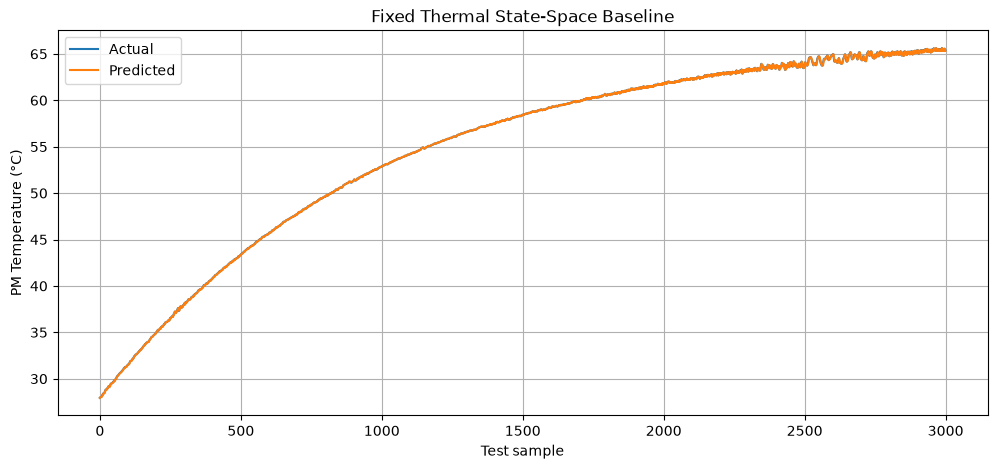

In [78]:

# TEMPERATURE PLOT


plt.figure(figsize=(12, 5))

N = min(
    3000,
    len(test_actual)
)

plt.plot(
    test_actual[:N],
    label="Actual"
)

plt.plot(
    test_pred[:N],
    label="Predicted"
)

plt.xlabel("Test sample")
plt.ylabel("PM Temperature (Â°C)")

plt.title(
    "Fixed Thermal State-Space Baseline"
)

plt.legend()
plt.grid(True)

plt.show()

saving the model and scalers

In [88]:

# SAVE FIXED MODEL


from pathlib import Path
import json

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIXED_MODEL_PATH = (
    MODEL_DIR /
    "fixed_thermal_state_space.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_dim": len(FEATURES),
        "hidden_dim": 64,
        "features": FEATURES,
        "target": TARGET,
        "sequence_length": SEQ_LEN,
        "test_mae": test_mae,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "rollout_mae": 0.5975,
        "rollout_rmse": 0.6489,
        "rollout_r2": 0.95267
    },
    FIXED_MODEL_PATH
)

print(
    f"Fixed model saved to:\n{FIXED_MODEL_PATH}"
)

Fixed model saved to:
models\fixed_thermal_state_space.pth


In [89]:

# SAVE FEATURE SCALER


import joblib

SCALER_PATH = (
    MODEL_DIR /
    "feature_scaler.pkl"
)

joblib.dump(
    x_scaler,
    SCALER_PATH
)

print(
    f"Scaler saved to:\n{SCALER_PATH}"
)

Scaler saved to:
models\feature_scaler.pkl


In [90]:

# SAVE CONFIGURATION


config = {
    "model_name": "Fixed Thermal State-Space Baseline",
    "target": TARGET,
    "features": FEATURES,
    "sequence_length": SEQ_LEN,
    "input_dim": len(FEATURES),
    "hidden_dim": 64,
    "batch_size": BATCH_SIZE,
    "train_profiles": sorted(
        [int(x) for x in train_profiles]
    ),
    "validation_profiles": sorted(
        [int(x) for x in val_profiles]
    ),
    "test_profiles": sorted(
        [int(x) for x in test_profiles]
    ),
    "test_mae": float(test_mae),
    "test_rmse": float(test_rmse),
    "test_r2": float(test_r2),
    "rollout_mae": 0.5975,
    "rollout_rmse": 0.6489,
    "rollout_r2": 0.95267
}

CONFIG_PATH = (
    MODEL_DIR /
    "fixed_thermal_config.json"
)

with open(
    CONFIG_PATH,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=4
    )

print(
    f"Configuration saved to:\n{CONFIG_PATH}"
)

Configuration saved to:
models\fixed_thermal_config.json


In [79]:

# PERSISTENCE BASELINE


persistence_pred = T_test_current

persistence_actual = T_test_next

persistence_mae = mean_absolute_error(
    persistence_actual,
    persistence_pred
)

persistence_rmse = np.sqrt(
    mean_squared_error(
        persistence_actual,
        persistence_pred
    )
)

persistence_r2 = r2_score(
    persistence_actual,
    persistence_pred
)

print(
    f"Persistence MAE : {persistence_mae:.4f} Â°C"
)

print(
    f"Persistence RMSE: {persistence_rmse:.4f} Â°C"
)

print(
    f"Persistence RÂ²  : {persistence_r2:.5f}"
)

Persistence MAE : 0.0401 Â°C
Persistence RMSE: 0.0918 Â°C
Persistence RÂ²  : 0.99998


In [80]:

# MODEL VS PERSISTENCE COMPARISON

print(
    "MAE improvement:",
    persistence_mae - test_mae
)

print(
    "RMSE improvement:",
    persistence_rmse - test_rmse
)

print(
    "Relative MAE improvement:",
    100 * (
        persistence_mae - test_mae
    ) / persistence_mae,
    "%"
)

MAE improvement: -0.04586434364318848
RMSE improvement: -0.039404698073815816
Relative MAE improvement: -114.2878360976653 %


In [81]:

# TEMPERATURE DYNAMICS ERROR


actual_delta = (
    T_test_next -
    T_test_current
)

predicted_delta = (
    test_pred -
    T_test_current
)

delta_mae = mean_absolute_error(
    actual_delta,
    predicted_delta
)

delta_rmse = np.sqrt(
    mean_squared_error(
        actual_delta,
        predicted_delta
    )
)

print(
    f"Delta-T MAE : {delta_mae:.6f} Â°C"
)

print(
    f"Delta-T RMSE: {delta_rmse:.6f} Â°C"
)

Delta-T MAE : 0.085995 Â°C
Delta-T RMSE: 0.131182 Â°C


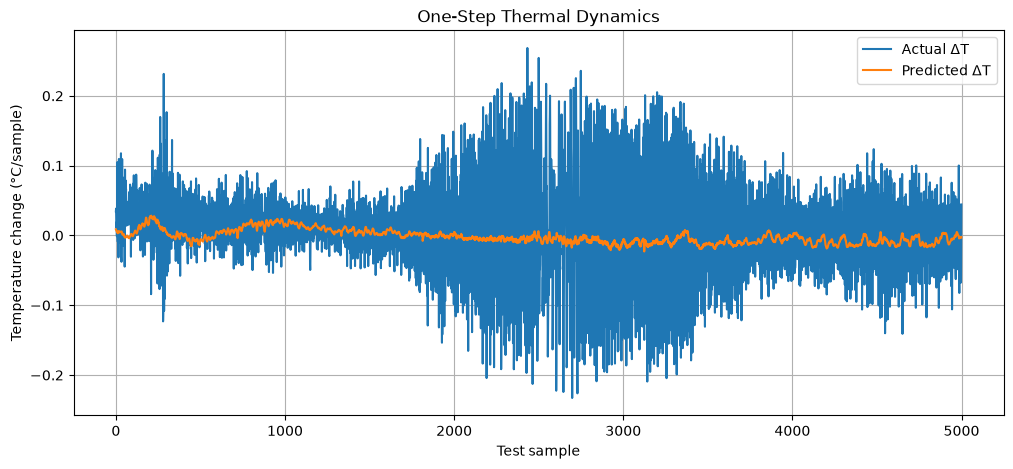

In [82]:

# BLOCK 14 â€” DYNAMIC RESPONSE PLOT

N = min(
    5000,
    len(actual_delta)
)

plt.figure(figsize=(12, 5))

plt.plot(
    actual_delta[:N],
    label="Actual Î”T"
)

plt.plot(
    predicted_delta[:N],
    label="Predicted Î”T"
)

plt.xlabel("Test sample")
plt.ylabel("Temperature change (Â°C/sample)")

plt.title(
    "One-Step Thermal Dynamics"
)

plt.legend()
plt.grid(True)

plt.show()

In [83]:

# MULTI-STEP ROLLOUT


def rollout_model(
    model,
    profile_df,
    features,
    x_scaler,
    seq_len=128,
    horizon=500,
    start_idx=None
):

    model.eval()

    
    # Scale only model input features
    

    X_scaled = x_scaler.transform(
        profile_df[features]
    ).astype(np.float32)

    X_scaled = torch.tensor(
        X_scaled,
        dtype=torch.float32,
        device=DEVICE
    )

    # Raw temperatures
    T_actual = (
        profile_df["pm"]
        .values
        .astype(np.float32)
    )

    T_ambient = (
        profile_df["ambient"]
        .values
        .astype(np.float32)
    )

    
    # Choose starting point
    

    if start_idx is None:
        start_idx = seq_len

    end_idx = min(
        start_idx + horizon,
        len(profile_df)
    )


    # Initial thermal state

    T_current = float(
        T_actual[start_idx - 1]
    )

    predictions = []
    actuals = []

    
    # Roll forward


    with torch.no_grad():

        for i in range(
            start_idx,
            end_idx
        ):

            # Same historical input window
            X_window = X_scaled[
                i-seq_len:i
            ].unsqueeze(0)

            T_current_tensor = torch.tensor(
                [T_current],
                dtype=torch.float32,
                device=DEVICE
            )

            T_ambient_tensor = torch.tensor(
                [T_ambient[i-1]],
                dtype=torch.float32,
                device=DEVICE
            )

            output = model(
                X_window,
                T_current_tensor,
                T_ambient_tensor
            )

            T_pred = float(
                output["T_pred"].item()
            )

            predictions.append(
                T_pred
            )

            actuals.append(
                T_actual[i]
            )

            
            # CRITICAL:
            # Feed prediction back as state
            

            T_current = T_pred

    return (
        np.asarray(predictions),
        np.asarray(actuals)
    )

In [84]:

# PROFILE 4 ROLLOUT


profile_id = 4

profile_test = (
    df[
        df["profile_id"] == profile_id
    ]
    .reset_index(drop=True)
)

print(
    "Profile length:",
    len(profile_test)
)

print(
    "Temperature range:",
    profile_test["pm"].min(),
    "to",
    profile_test["pm"].max()
)

Profile length: 33424
Temperature range: 22.924949645996094 to 99.3966293334961


In [85]:
pred_rollout, actual_rollout = rollout_model(
    model=model,
    profile_df=profile_test,
    features=FEATURES,
    x_scaler=x_scaler,
    seq_len=SEQ_LEN,
    horizon=500,
    start_idx=500
)

print(
    "Rollout length:",
    len(pred_rollout)
)

print(
    "Actual range:",
    actual_rollout.min(),
    "to",
    actual_rollout.max()
)

print(
    "Predicted range:",
    pred_rollout.min(),
    "to",
    pred_rollout.max()
)

Rollout length: 500
Actual range: 38.669643 to 48.99829
Predicted range: 38.671775817871094 to 49.93840789794922


In [86]:
rollout_mae = mean_absolute_error(
    actual_rollout,
    pred_rollout
)

rollout_rmse = np.sqrt(
    mean_squared_error(
        actual_rollout,
        pred_rollout
    )
)

rollout_r2 = r2_score(
    actual_rollout,
    pred_rollout
)

print(
    f"500-step Rollout MAE : {rollout_mae:.4f} Â°C"
)

print(
    f"500-step Rollout RMSE: {rollout_rmse:.4f} Â°C"
)

print(
    f"500-step Rollout RÂ²  : {rollout_r2:.5f}"
)

500-step Rollout MAE : 0.5975 Â°C
500-step Rollout RMSE: 0.6489 Â°C
500-step Rollout RÂ²  : 0.95267


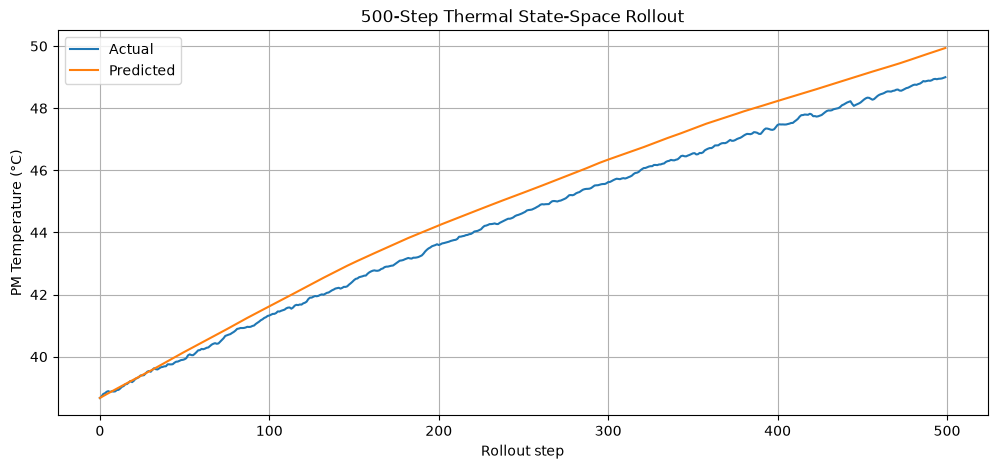

In [87]:
plt.figure(figsize=(12, 5))

plt.plot(
    actual_rollout,
    label="Actual"
)

plt.plot(
    pred_rollout,
    label="Predicted"
)

plt.xlabel("Rollout step")
plt.ylabel("PM Temperature (Â°C)")

plt.title(
    "500-Step Thermal State-Space Rollout"
)

plt.legend()
plt.grid(True)

plt.show()

Adaptive Thermal Parameters

In [92]:
# ADAPTIVE THERMAL PARAMETERS


class AdaptiveThermalParameters(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.Tanh(),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.Tanh(),

            nn.Linear(
                hidden_dim,
                2
            )
        )

    def forward(self, x):

        params = self.network(x)

        # Separate outputs
        raw_R = params[:, 0]
        raw_C = params[:, 1]

        # Ensure positivity
        R_th = (
            F.softplus(raw_R)
            + 1e-4
        )

        C_th = (
            F.softplus(raw_C)
            + 1e-4
        )

        return R_th, C_th

In [93]:

# ADAPTIVE THERMAL MODEL


class AdaptiveThermalModel(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        # Temporal encoder
        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # Learn effective heat generation
        self.loss_head = nn.Sequential(

            nn.Linear(
                hidden_dim,
                32
            ),

            nn.Tanh(),

            nn.Linear(
                32,
                1
            )
        )

        # Adaptive Rth and Cth
        self.parameter_net = (
            AdaptiveThermalParameters(
                input_dim=hidden_dim,
                hidden_dim=32
            )
        )

    def forward(
        self,
        x,
        T_current,
        T_ambient
    ):

        
        # Temporal representation

        z = self.encoder(x)

        
        # Learned heat generation
        

        P_loss = F.softplus(
            self.loss_head(z)
        ).squeeze(-1)

        
        # Adaptive thermal parameters
        

        R_th, C_th = (
            self.parameter_net(z)
        )

        
        # Heat rejection
        

        cooling = (
            T_current -
            T_ambient
        ) / R_th

        
        # Thermal dynamics
        

        dT = (
            P_loss -
            cooling
        ) / C_th

        
        # State transition
        

        T_pred = (
            T_current +
            dT
        )

        return {
            "T_pred": T_pred,
            "P_loss": P_loss,
            "R_th": R_th,
            "C_th": C_th,
            "dT": dT
        }

In [94]:

# INITIALIZE ADAPTIVE MODEL


adaptive_model = AdaptiveThermalModel(
    input_dim=len(FEATURES),
    hidden_dim=64
).to(DEVICE)

print(adaptive_model)

AdaptiveThermalModel(
  (encoder): TemporalEncoder(
    (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.1)
  )
  (loss_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
  (parameter_net): AdaptiveThermalParameters(
    (network): Sequential(
      (0): Linear(in_features=64, out_features=32, bias=True)
      (1): Tanh()
      (2): Linear(in_features=32, out_features=32, bias=True)
      (3): Tanh()
      (4): Linear(in_features=32, out_features=2, bias=True)
    )
  )
)


In [95]:

# OPTIMIZER


adaptive_optimizer = torch.optim.AdamW(
    adaptive_model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

In [96]:

# TRAIN ADAPTIVE MODEL


EPOCHS = 10

for epoch in range(EPOCHS):

    adaptive_model.train()

    running_loss = 0.0

    for (
        X_batch,
        T_current,
        T_next,
        T_ambient
    ) in train_loader:

        X_batch = X_batch.to(DEVICE)
        T_current = T_current.to(DEVICE)
        T_next = T_next.to(DEVICE)
        T_ambient = T_ambient.to(DEVICE)

        adaptive_optimizer.zero_grad()

        output = adaptive_model(
            X_batch,
            T_current,
            T_ambient
        )

        loss = F.mse_loss(
            output["T_pred"],
            T_next
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            adaptive_model.parameters(),
            max_norm=1.0
        )

        adaptive_optimizer.step()

        running_loss += loss.item()

    train_loss = (
        running_loss /
        len(train_loader)
    )

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.6f}"
    )

Epoch 01 | Train Loss: 36.630197
Epoch 02 | Train Loss: 0.009286
Epoch 03 | Train Loss: 0.007936
Epoch 04 | Train Loss: 0.007519
Epoch 05 | Train Loss: 0.007322
Epoch 06 | Train Loss: 0.007214
Epoch 07 | Train Loss: 0.007150
Epoch 08 | Train Loss: 0.007115
Epoch 09 | Train Loss: 0.007102
Epoch 10 | Train Loss: 0.007094


In [97]:
(
    adaptive_mae,
    adaptive_rmse,
    adaptive_r2,
    adaptive_pred,
    adaptive_actual
) = evaluate_loader(
    adaptive_model,
    test_loader
)

print(
    f"Adaptive Test MAE : "
    f"{adaptive_mae:.4f} Â°C"
)

print(
    f"Adaptive Test RMSE: "
    f"{adaptive_rmse:.4f} Â°C"
)

print(
    f"Adaptive Test RÂ²  : "
    f"{adaptive_r2:.5f}"
)

Adaptive Test MAE : 0.0396 Â°C
Adaptive Test RMSE: 0.0914 Â°C
Adaptive Test RÂ²  : 0.99998


In [98]:

# INSPECT LEARNED PARAMETERS


adaptive_model.eval()

with torch.no_grad():

    (
        X_batch,
        T_current,
        T_next,
        T_ambient
    ) = next(iter(test_loader))

    X_batch = X_batch.to(DEVICE)
    T_current = T_current.to(DEVICE)
    T_ambient = T_ambient.to(DEVICE)

    output = adaptive_model(
        X_batch,
        T_current,
        T_ambient
    )

print(
    "R_th statistics:"
)

print(
    output["R_th"]
    .cpu()
    .numpy()
    .min(),
    output["R_th"]
    .cpu()
    .numpy()
    .mean(),
    output["R_th"]
    .cpu()
    .numpy()
    .max()
)

print(
    "\nC_th statistics:"
)

print(
    output["C_th"]
    .cpu()
    .numpy()
    .min(),
    output["C_th"]
    .cpu()
    .numpy()
    .mean(),
    output["C_th"]
    .cpu()
    .numpy()
    .max()
)

R_th statistics:
34.009415 34.009495 34.009537

C_th statistics:
39.293446 39.293545 39.293594


In [99]:
print(
    "R_th standard deviation:",
    output["R_th"]
    .std()
    .item()
)

print(
    "C_th standard deviation:",
    output["C_th"]
    .std()
    .item()
)

R_th standard deviation: 4.326414637034759e-05
C_th standard deviation: 5.0288035708945245e-05


In [100]:
adaptive_rollout_pred, adaptive_rollout_actual = rollout_model(
    model=adaptive_model,
    profile_df=profile_test,
    features=FEATURES,
    x_scaler=x_scaler,
    seq_len=SEQ_LEN,
    horizon=500,
    start_idx=500
)

In [101]:
adaptive_rollout_mae = mean_absolute_error(
    adaptive_rollout_actual,
    adaptive_rollout_pred
)

adaptive_rollout_rmse = np.sqrt(
    mean_squared_error(
        adaptive_rollout_actual,
        adaptive_rollout_pred
    )
)

adaptive_rollout_r2 = r2_score(
    adaptive_rollout_actual,
    adaptive_rollout_pred
)

print(
    f"Adaptive 500-step MAE : "
    f"{adaptive_rollout_mae:.4f} Â°C"
)

print(
    f"Adaptive 500-step RMSE: "
    f"{adaptive_rollout_rmse:.4f} Â°C"
)

print(
    f"Adaptive 500-step RÂ²  : "
    f"{adaptive_rollout_r2:.5f}"
)

Adaptive 500-step MAE : 1.5136 Â°C
Adaptive 500-step RMSE: 1.6776 Â°C
Adaptive 500-step RÂ²  : 0.68366


In [102]:

# SAVE ADAPTIVE CHECKPOINT


ADAPTIVE_MODEL_PATH = (
    MODEL_DIR /
    "adaptive_thermal_state_space_v1.pth"
)

torch.save(
    {
        "model_state_dict":
            adaptive_model.state_dict(),

        "input_dim":
            len(FEATURES),

        "hidden_dim":
            64,

        "features":
            FEATURES,

        "target":
            TARGET,

        "sequence_length":
            SEQ_LEN,

        "test_mae":
            adaptive_mae,

        "test_rmse":
            adaptive_rmse,

        "test_r2":
            adaptive_r2,

        "rollout_mae":
            adaptive_rollout_mae,

        "rollout_rmse":
            adaptive_rollout_rmse,

        "rollout_r2":
            adaptive_rollout_r2
    },
    ADAPTIVE_MODEL_PATH
)

print(
    f"Adaptive model saved to:\n"
    f"{ADAPTIVE_MODEL_PATH}"
)

Adaptive model saved to:
models\adaptive_thermal_state_space_v1.pth


In [103]:

# MULTI-STEP SEQUENCES


def create_multistep_sequences(
    scaled_data,
    raw_data,
    features,
    target,
    seq_len=128,
    horizon=20
):

    X_sequences = []
    T_current = []
    T_future = []
    ambient_future = []
    profile_labels = []

    for profile_id in scaled_data["profile_id"].unique():

        scaled_group = (
            scaled_data[
                scaled_data["profile_id"] == profile_id
            ]
            .reset_index(drop=True)
        )

        raw_group = (
            raw_data[
                raw_data["profile_id"] == profile_id
            ]
            .reset_index(drop=True)
        )

        X_values = scaled_group[
            features
        ].values.astype(np.float32)

        T_values = raw_group[
            target
        ].values.astype(np.float32)

        ambient_values = raw_group[
            "ambient"
        ].values.astype(np.float32)

        # Need enough samples for:
        # history + future horizon
        for i in range(
            seq_len,
            len(scaled_group) - horizon + 1
        ):

            X_sequences.append(
                X_values[
                    i-seq_len:i
                ]
            )

            # T(t)
            T_current.append(
                T_values[i-1]
            )

            # T(t+1 ... t+H)
            T_future.append(
                T_values[
                    i:i+horizon
                ]
            )

            # Ambient(t ... t+H-1)
            ambient_future.append(
                ambient_values[
                    i-1:i+horizon-1
                ]
            )

            profile_labels.append(
                profile_id
            )

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(T_current, dtype=np.float32),
        np.asarray(T_future, dtype=np.float32),
        np.asarray(ambient_future, dtype=np.float32),
        np.asarray(profile_labels)
    )

In [104]:
# BLOCK 17.2 â€” TRAIN MULTI-STEP DATA


HORIZON = 20

(
    X_train_ms,
    T_train_current_ms,
    T_train_future_ms,
    T_train_ambient_ms,
    train_ms_profiles
) = create_multistep_sequences(
    train_scaled,
    train_df,
    FEATURES,
    TARGET,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

print(
    "X_train:",
    X_train_ms.shape
)

print(
    "Current temperature:",
    T_train_current_ms.shape
)

print(
    "Future temperatures:",
    T_train_future_ms.shape
)

print(
    "Future ambient:",
    T_train_ambient_ms.shape
)

X_train: (925544, 128, 13)
Current temperature: (925544,)
Future temperatures: (925544, 20)
Future ambient: (925544, 20)


In [105]:

# VALIDATION MULTI-STEP DATA


(
    X_val_ms,
    T_val_current_ms,
    T_val_future_ms,
    T_val_ambient_ms,
    val_ms_profiles
) = create_multistep_sequences(
    val_scaled,
    val_df,
    FEATURES,
    TARGET,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

print(
    "X_val:",
    X_val_ms.shape
)

X_val: (210430, 128, 13)


In [106]:

# BLOCK 17.4 â€” TEST MULTI-STEP DATA


(
    X_test_ms,
    T_test_current_ms,
    T_test_future_ms,
    T_test_ambient_ms,
    test_ms_profiles
) = create_multistep_sequences(
    test_scaled,
    test_df,
    FEATURES,
    TARGET,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

print(
    "X_test:",
    X_test_ms.shape
)

X_test: (184699, 128, 13)


In [107]:

# MULTI-STEP DATASET


class MultiStepThermalDataset(Dataset):

    def __init__(
        self,
        X,
        T_current,
        T_future,
        T_ambient
    ):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.T_current = torch.tensor(
            T_current,
            dtype=torch.float32
        )

        self.T_future = torch.tensor(
            T_future,
            dtype=torch.float32
        )

        self.T_ambient = torch.tensor(
            T_ambient,
            dtype=torch.float32
        )

    def __len__(self):

        return len(self.X)

    def __getitem__(self, idx):

        return (
            self.X[idx],
            self.T_current[idx],
            self.T_future[idx],
            self.T_ambient[idx]
        )

In [109]:

#  FREE LARGE MULTI-STEP ARRAYS


import gc

# Delete only the failed multi-step arrays
variables_to_delete = [
    "X_train_ms",
    "T_train_current_ms",
    "T_train_future_ms",
    "T_train_ambient_ms",
    "train_ms_profiles",
    "X_val_ms",
    "T_val_current_ms",
    "T_val_future_ms",
    "T_val_ambient_ms",
    "val_ms_profiles",
    "X_test_ms",
    "T_test_current_ms",
    "T_test_future_ms",
    "T_test_ambient_ms",
    "test_ms_profiles"
]

for var in variables_to_delete:

    if var in globals():
        del globals()[var]

gc.collect()

print("Large multi-step arrays cleared.")

Large multi-step arrays cleared.


In [131]:
# ==========================================
# BLOCK 17.1 â€” LAZY MULTI-STEP DATASET
# ==========================================

class LazyMultiStepThermalDataset(Dataset):

    def __init__(
        self,
        scaled_df,
        raw_df,
        features,
        seq_len=128,
        horizon=20
    ):

        self.features = features
        self.seq_len = seq_len
        self.horizon = horizon

        self.X = []
        self.T = []
        self.ambient = []
        self.profile_ids = []

        # ----------------------------------
        # Build only index locations
        # ----------------------------------

        for profile_id in scaled_df["profile_id"].unique():

            scaled_group = (
                scaled_df[
                    scaled_df["profile_id"] == profile_id
                ]
                .reset_index(drop=True)
            )

            raw_group = (
                raw_df[
                    raw_df["profile_id"] == profile_id
                ]
                .reset_index(drop=True)
            )

            n = len(scaled_group)

            # Valid starting positions
            for i in range(
                seq_len,
                n - horizon + 1
            ):

                self.X.append(
                    (
                        int(profile_id),
                        i
                    )
                )

        # Store profile data separately
        self.scaled_profiles = {}
        self.raw_profiles = {}

        for profile_id in scaled_df["profile_id"].unique():

            self.scaled_profiles[
                int(profile_id)
            ] = (
                scaled_df[
                    scaled_df["profile_id"] == profile_id
                ]
                .reset_index(drop=True)
            )

            self.raw_profiles[
                int(profile_id)
            ] = (
                raw_df[
                    raw_df["profile_id"] == profile_id
                ]
                .reset_index(drop=True)
            )

    def __len__(self):

        return len(self.X)

    def __getitem__(self, idx):

        profile_id, i = self.X[idx]

        scaled_group = (
            self.scaled_profiles[
                profile_id
            ]
        )

        raw_group = (
            self.raw_profiles[
                profile_id
            ]
        )

        # ----------------------------------
        # Input history
        # ----------------------------------

        X = (
            scaled_group[
                self.features
            ]
            .iloc[
                i-self.seq_len:i
            ]
            .values
            .astype(np.float32)
        )

        # ----------------------------------
        # Current temperature
        # ----------------------------------

        T_current = np.float32(
            raw_group[
                "pm"
            ].iloc[i-1]
        )

        # ----------------------------------
        # Future temperatures
        # ----------------------------------

        T_future = (
            raw_group[
                "pm"
            ]
            .iloc[
                i:i+self.horizon
            ]
            .values
            .astype(np.float32)
        )

        # ----------------------------------
        # Future ambient temperatures
        # ----------------------------------

        T_ambient = (
            raw_group[
                "ambient"
            ]
            .iloc[
                i-1:i+self.horizon-1
            ]
            .values
            .astype(np.float32)
        )

        P_cu = (
    raw_group[
        "P_cu"
    ]
    .iloc[i-1]
)

        return (
    torch.from_numpy(X),

    torch.tensor(
        T_current,
        dtype=torch.float32
    ),

    torch.from_numpy(
        T_future
    ),

    torch.from_numpy(
        T_ambient
    ),

    torch.tensor(
        P_cu,
        dtype=torch.float32
    )
)

In [111]:

# CREATE LAZY DATASETS


HORIZON = 20

train_ms_dataset = LazyMultiStepThermalDataset(
    scaled_df=train_scaled,
    raw_df=train_df,
    features=FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

val_ms_dataset = LazyMultiStepThermalDataset(
    scaled_df=val_scaled,
    raw_df=val_df,
    features=FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

test_ms_dataset = LazyMultiStepThermalDataset(
    scaled_df=test_scaled,
    raw_df=test_df,
    features=FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

print(
    "Train sequences:",
    len(train_ms_dataset)
)

print(
    "Validation sequences:",
    len(val_ms_dataset)
)

print(
    "Test sequences:",
    len(test_ms_dataset)
)

Train sequences: 925544
Validation sequences: 210430
Test sequences: 184699


In [112]:

# TEST LAZY DATASET


sample = train_ms_dataset[0]

X_sample = sample[0]
T_current_sample = sample[1]
T_future_sample = sample[2]
T_ambient_sample = sample[3]

print(
    "X shape:",
    X_sample.shape
)

print(
    "Current T:",
    T_current_sample.item()
)

print(
    "Future T shape:",
    T_future_sample.shape
)

print(
    "Ambient shape:",
    T_ambient_sample.shape
)

X shape: torch.Size([128, 13])
Current T: 26.510826110839844
Future T shape: torch.Size([20])
Ambient shape: torch.Size([20])


In [113]:
print(
    "Current T:",
    T_current_sample.item()
)

print(
    "First future T:",
    T_future_sample[0].item()
)

print(
    "First ambient:",
    T_ambient_sample[0].item()
)

Current T: 26.510826110839844
First future T: 26.51397705078125
First ambient: 21.512910842895508


In [114]:

# LAZY DATALOADERS


BATCH_SIZE_MS = 256

train_ms_loader = DataLoader(
    train_ms_dataset,
    batch_size=BATCH_SIZE_MS,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_ms_loader = DataLoader(
    val_ms_dataset,
    batch_size=BATCH_SIZE_MS,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_ms_loader = DataLoader(
    test_ms_dataset,
    batch_size=BATCH_SIZE_MS,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(
    "Train batches:",
    len(train_ms_loader)
)

print(
    "Validation batches:",
    len(val_ms_loader)
)

print(
    "Test batches:",
    len(test_ms_loader)
)

Train batches: 3616
Validation batches: 822
Test batches: 722


In [115]:

# FREE OLD ONE-STEP SEQUENCES

for var in [
    "X_train_seq",
    "X_val_seq",
    "X_test_seq",
    "T_train_current",
    "T_train_next",
    "T_train_ambient",
    "T_val_current",
    "T_val_next",
    "T_val_ambient",
    "T_test_current",
    "T_test_next",
    "T_test_ambient",
    "train_seq_profiles",
    "val_seq_profiles",
    "test_seq_profiles"
]:

    if var in globals():
        del globals()[var]

gc.collect()

print(
    "Old one-step sequence arrays cleared."
)

Old one-step sequence arrays cleared.


In [116]:

# MULTI-STEP THERMAL MODEL


class MultiStepThermalModel(nn.Module):

    def __init__(self, input_dim, hidden_dim=64):

        super().__init__()

        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # Predict effective heat generation
        self.loss_head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

        # Learnable positive thermal parameters
        self.log_Rth = nn.Parameter(
            torch.tensor(3.5)
        )

        self.log_Cth = nn.Parameter(
            torch.tensor(3.7)
        )

    def forward(
        self,
        x,
        T_current
    ):

        z = self.encoder(x)

        P_loss = F.softplus(
            self.loss_head(z)
        ).squeeze(-1)

        R_th = (
            F.softplus(self.log_Rth)
            + 1e-4
        )

        C_th = (
            F.softplus(self.log_Cth)
            + 1e-4
        )

        return P_loss, R_th, C_th

In [117]:

# THERMAL ROLLOUT


def thermal_rollout(
    T_current,
    T_ambient,
    P_loss,
    R_th,
    C_th,
    horizon
):

    temperatures = []

    T = T_current

    for k in range(horizon):

        cooling = (
            T -
            T_ambient[:, k]
        ) / R_th

        dT = (
            P_loss -
            cooling
        ) / C_th

        T = T + dT

        temperatures.append(T)

    return torch.stack(
        temperatures,
        dim=1
    )

In [118]:

# INITIALIZE MODEL


ms_model = MultiStepThermalModel(
    input_dim=len(FEATURES),
    hidden_dim=64
).to(DEVICE)

print(ms_model)

MultiStepThermalModel(
  (encoder): TemporalEncoder(
    (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.1)
  )
  (loss_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [119]:

# OPTIMIZER


ms_optimizer = torch.optim.AdamW(
    ms_model.parameters(),
    lr=5e-4,
    weight_decay=1e-5
)

print("Optimizer ready.")

Optimizer ready.


In [120]:

# MULTI-STEP LOSS


def multistep_loss(
    predicted,
    actual
):

    horizon = predicted.shape[1]

    # Later steps receive slightly
    # higher importance
    weights = torch.linspace(
        1.0,
        2.0,
        horizon,
        device=predicted.device
    )

    error = (
        predicted - actual
    ) ** 2

    weighted_error = (
        error *
        weights.unsqueeze(0)
    )

    return weighted_error.mean()

In [121]:

# TRAIN


EPOCHS = 5

for epoch in range(EPOCHS):

    ms_model.train()

    running_loss = 0.0

    for (
        X_batch,
        T_current,
        T_future,
        T_ambient
    ) in train_ms_loader:

        X_batch = X_batch.to(DEVICE)
        T_current = T_current.to(DEVICE)
        T_future = T_future.to(DEVICE)
        T_ambient = T_ambient.to(DEVICE)

        ms_optimizer.zero_grad()

        # ----------------------------------
        # Model outputs
        # ----------------------------------

        (
            P_loss,
            R_th,
            C_th
        ) = ms_model(
            X_batch,
            T_current
        )

        # ----------------------------------
        # Multi-step physics rollout
        # ----------------------------------

        predictions = thermal_rollout(
            T_current,
            T_ambient,
            P_loss,
            R_th,
            C_th,
            HORIZON
        )

        # ----------------------------------
        # Trajectory loss
        # ----------------------------------

        loss = multistep_loss(
            predictions,
            T_future
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            ms_model.parameters(),
            max_norm=1.0
        )

        ms_optimizer.step()

        running_loss += loss.item()

    epoch_loss = (
        running_loss /
        len(train_ms_loader)
    )

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.6f}"
    )

Epoch 01/5 | Loss: 54.168287
Epoch 02/5 | Loss: 8.725971
Epoch 03/5 | Loss: 4.364452
Epoch 04/5 | Loss: 2.104097
Epoch 05/5 | Loss: 1.030933


In [122]:

# LEARNED PARAMETERS


ms_model.eval()

with torch.no_grad():

    R_th = (
        F.softplus(
            ms_model.log_Rth
        ) + 1e-4
    ).item()

    C_th = (
        F.softplus(
            ms_model.log_Cth
        ) + 1e-4
    ).item()

print(
    f"Learned R_th: {R_th:.6f}"
)

print(
    f"Learned C_th: {C_th:.6f}"
)

Learned R_th: 6.651122
Learned C_th: 8.874657


In [123]:

# VALIDATION


ms_model.eval()

val_predictions = []
val_actual = []

with torch.no_grad():

    for (
        X_batch,
        T_current,
        T_future,
        T_ambient
    ) in val_ms_loader:

        X_batch = X_batch.to(DEVICE)
        T_current = T_current.to(DEVICE)
        T_ambient = T_ambient.to(DEVICE)

        (
            P_loss,
            R_th,
            C_th
        ) = ms_model(
            X_batch,
            T_current
        )

        predictions = thermal_rollout(
            T_current,
            T_ambient,
            P_loss,
            R_th,
            C_th,
            HORIZON
        )

        val_predictions.append(
            predictions.cpu().numpy()
        )

        val_actual.append(
            T_future.numpy()
        )

val_predictions = np.concatenate(
    val_predictions
)

val_actual = np.concatenate(
    val_actual
)

print(
    "Prediction shape:",
    val_predictions.shape
)

print(
    "Actual shape:",
    val_actual.shape
)

Prediction shape: (210430, 20)
Actual shape: (210430, 20)


In [124]:

# HORIZON-WISE MAE


horizon_mae = []

for k in range(HORIZON):

    mae = mean_absolute_error(
        val_actual[:, k],
        val_predictions[:, k]
    )

    horizon_mae.append(mae)

    print(
        f"Step {k+1:02d}: "
        f"{mae:.4f} Â°C"
    )

Step 01: 0.1245 Â°C
Step 02: 0.2357 Â°C
Step 03: 0.3401 Â°C
Step 04: 0.4406 Â°C
Step 05: 0.5384 Â°C
Step 06: 0.6342 Â°C
Step 07: 0.7283 Â°C
Step 08: 0.8209 Â°C
Step 09: 0.9120 Â°C
Step 10: 1.0017 Â°C
Step 11: 1.0901 Â°C
Step 12: 1.1770 Â°C
Step 13: 1.2624 Â°C
Step 14: 1.3464 Â°C
Step 15: 1.4292 Â°C
Step 16: 1.5106 Â°C
Step 17: 1.5906 Â°C
Step 18: 1.6694 Â°C
Step 19: 1.7469 Â°C
Step 20: 1.8231 Â°C


In [125]:

# OVERALL MULTI-STEP METRICS


overall_mae = mean_absolute_error(
    val_actual.flatten(),
    val_predictions.flatten()
)

overall_rmse = np.sqrt(
    mean_squared_error(
        val_actual.flatten(),
        val_predictions.flatten()
    )
)

overall_r2 = r2_score(
    val_actual.flatten(),
    val_predictions.flatten()
)

print(
    f"20-step MAE : {overall_mae:.4f} Â°C"
)

print(
    f"20-step RMSE: {overall_rmse:.4f} Â°C"
)

print(
    f"20-step RÂ²  : {overall_r2:.5f}"
)

20-step MAE : 1.0211 Â°C
20-step RMSE: 1.6752 Â°C
20-step RÂ²  : 0.98947


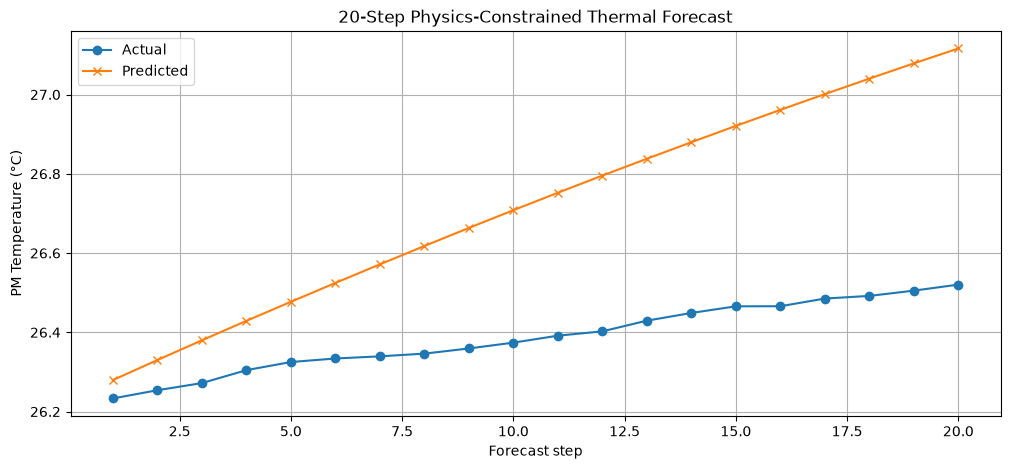

In [126]:

# TRAJECTORY PLOT


sample_idx = 0

plt.figure(figsize=(12, 5))

plt.plot(
    range(1, HORIZON + 1),
    val_actual[sample_idx],
    marker="o",
    label="Actual"
)

plt.plot(
    range(1, HORIZON + 1),
    val_predictions[sample_idx],
    marker="x",
    label="Predicted"
)

plt.xlabel(
    "Forecast step"
)

plt.ylabel(
    "PM Temperature (Â°C)"
)

plt.title(
    "20-Step Physics-Constrained "
    "Thermal Forecast"
)

plt.legend()
plt.grid(True)

plt.show()

In [127]:

# BLOCK 17.17 â€” SAVE MULTI-STEP MODEL


MULTISTEP_MODEL_PATH = (
    MODEL_DIR /
    "multistep_thermal_state_space_v1.pth"
)

torch.save(
    {
        "model_state_dict":
            ms_model.state_dict(),

        "input_dim":
            len(FEATURES),

        "hidden_dim":
            64,

        "features":
            FEATURES,

        "sequence_length":
            SEQ_LEN,

        "horizon":
            HORIZON,

        "R_th":
            R_th,

        "C_th":
            C_th,

        "val_mae":
            overall_mae,

        "val_rmse":
            overall_rmse,

        "val_r2":
            overall_r2
    },
    MULTISTEP_MODEL_PATH
)

print(
    f"Saved to:\n{MULTISTEP_MODEL_PATH}"
)

Saved to:
models\multistep_thermal_state_space_v1.pth


In [128]:

# PHYSICS-INFORMED LOSS MODEL


class PhysicsInformedThermalModel(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # Learn only additional/unmodeled losses
        self.additional_loss_head = nn.Sequential(

            nn.Linear(
                hidden_dim,
                32
            ),

            nn.Tanh(),

            nn.Linear(
                32,
                1
            )
        )

        # Learnable effective thermal parameters
        self.log_Rth = nn.Parameter(
            torch.tensor(
                np.log(
                    np.exp(6.651122) - 1
                ),
                dtype=torch.float32
            )
        )

        self.log_Cth = nn.Parameter(
            torch.tensor(
                np.log(
                    np.exp(8.874657) - 1
                ),
                dtype=torch.float32
            )
        )

    def forward(
        self,
        x,
        P_cu,
    ):

        z = self.encoder(x)

        # Additional positive losses
        P_additional = F.softplus(
            self.additional_loss_head(z)
        ).squeeze(-1)

        # Total thermal generation
        P_loss = (
            P_cu +
            P_additional
        )

        R_th = (
            F.softplus(
                self.log_Rth
            ) + 1e-4
        )

        C_th = (
            F.softplus(
                self.log_Cth
            ) + 1e-4
        )

        return (
            P_loss,
            P_additional,
            R_th,
            C_th
        )

In [138]:

# BLOCK 18.2 â€” NEW MULTI-STEP DATASET


class LazyMultiStepPhysicsDataset(Dataset):

    def __init__(
        self,
        scaled_df,
        raw_df,
        features,
        seq_len=128,
        horizon=20
    ):

        self.features = features
        self.seq_len = seq_len
        self.horizon = horizon

        self.index_map = []

        self.scaled_profiles = {}
        self.raw_profiles = {}

        # ----------------------------------
        # Store profiles
        # ----------------------------------

        for profile_id in scaled_df["profile_id"].unique():

            profile_id = int(profile_id)

            scaled_group = (
                scaled_df[
                    scaled_df["profile_id"] == profile_id
                ]
                .reset_index(drop=True)
            )

            raw_group = (
                raw_df[
                    raw_df["profile_id"] == profile_id
                ]
                .reset_index(drop=True)
            )

            self.scaled_profiles[profile_id] = scaled_group
            self.raw_profiles[profile_id] = raw_group

            n = len(scaled_group)

            # ----------------------------------
            # Valid sequence positions
            # ----------------------------------

            for i in range(
                seq_len,
                n - horizon + 1
            ):

                self.index_map.append(
                    (profile_id, i)
                )

    def __len__(self):

        return len(self.index_map)

    def __getitem__(self, idx):

        profile_id, i = self.index_map[idx]

        scaled_group = (
            self.scaled_profiles[profile_id]
        )

        raw_group = (
            self.raw_profiles[profile_id]
        )

        # ----------------------------------
        # Input sequence
        # ----------------------------------

        X = (
            scaled_group[
                self.features
            ]
            .iloc[
                i-self.seq_len:i
            ]
            .values
            .astype(np.float32)
        )

        # ----------------------------------
        # Current PM temperature
        # ----------------------------------

        T_current = np.float32(
            raw_group["pm"].iloc[i-1]
        )

        # ----------------------------------
        # Future PM temperatures
        # ----------------------------------

        T_future = (
            raw_group["pm"]
            .iloc[
                i:i+self.horizon
            ]
            .values
            .astype(np.float32)
        )

        # ----------------------------------
        # Ambient temperature
        # ----------------------------------

        T_ambient = (
            raw_group["ambient"]
            .iloc[
                i-1:i+self.horizon-1
            ]
            .values
            .astype(np.float32)
        )

        # ----------------------------------
        # RAW COPPER LOSS
        # ----------------------------------

        P_cu = np.float32(
            raw_group["P_cu"].iloc[i-1]
        )

        return (
            torch.from_numpy(X),
            torch.tensor(
                T_current,
                dtype=torch.float32
            ),
            torch.from_numpy(T_future),
            torch.from_numpy(T_ambient),
            torch.tensor(
                P_cu,
                dtype=torch.float32
            )
        )

In [139]:

# CREATE PHYSICS DATASETS


HORIZON = 20

train_physics_dataset = LazyMultiStepPhysicsDataset(
    scaled_df=train_scaled,
    raw_df=train_df,
    features=FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

val_physics_dataset = LazyMultiStepPhysicsDataset(
    scaled_df=val_scaled,
    raw_df=val_df,
    features=FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

test_physics_dataset = LazyMultiStepPhysicsDataset(
    scaled_df=test_scaled,
    raw_df=test_df,
    features=FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

print(
    "Train:",
    len(train_physics_dataset)
)

print(
    "Validation:",
    len(val_physics_dataset)
)

print(
    "Test:",
    len(test_physics_dataset)
)

Train: 925544
Validation: 210430
Test: 184699


In [140]:

# SINGLE SAMPLE CHECK


sample = train_physics_dataset[0]

print(
    "Number of items:",
    len(sample)
)

for i, item in enumerate(sample):

    if torch.is_tensor(item):

        print(
            f"Item {i}:",
            item.shape,
            item.dtype
        )

    else:

        print(
            f"Item {i}:",
            type(item)
        )

Number of items: 5
Item 0: torch.Size([128, 13]) torch.float32
Item 1: torch.Size([]) torch.float32
Item 2: torch.Size([20]) torch.float32
Item 3: torch.Size([20]) torch.float32
Item 4: torch.Size([]) torch.float32


In [141]:

# PHYSICS DATALOADERS


BATCH_SIZE_MS = 256

train_physics_loader = DataLoader(
    train_physics_dataset,
    batch_size=BATCH_SIZE_MS,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_physics_loader = DataLoader(
    val_physics_dataset,
    batch_size=BATCH_SIZE_MS,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_physics_loader = DataLoader(
    test_physics_dataset,
    batch_size=BATCH_SIZE_MS,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("New physics loaders created.")

New physics loaders created.


In [142]:

# FINAL BATCH CHECK


batch = next(
    iter(train_physics_loader)
)

print(
    "Number of batch items:",
    len(batch)
)

X_batch = batch[0]
T_current_batch = batch[1]
T_future_batch = batch[2]
T_ambient_batch = batch[3]
P_cu_batch = batch[4]

print(
    "X:",
    X_batch.shape
)

print(
    "T_current:",
    T_current_batch.shape
)

print(
    "T_future:",
    T_future_batch.shape
)

print(
    "T_ambient:",
    T_ambient_batch.shape
)

print(
    "P_cu:",
    P_cu_batch.shape
)

Number of batch items: 5
X: torch.Size([256, 128, 13])
T_current: torch.Size([256])
T_future: torch.Size([256, 20])
T_ambient: torch.Size([256, 20])
P_cu: torch.Size([256])


In [143]:

# PHYSICS-INFORMED MODEL


class PhysicsInformedThermalModel(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        # Temporal encoder
        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # Learn additional/unmodeled heat loss
        self.additional_loss_head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

        # Learnable positive thermal parameters
        self.log_Rth = nn.Parameter(
            torch.tensor(
                np.log(np.exp(6.651122) - 1),
                dtype=torch.float32
            )
        )

        self.log_Cth = nn.Parameter(
            torch.tensor(
                np.log(np.exp(8.874657) - 1),
                dtype=torch.float32
            )
        )

    def forward(
        self,
        x,
        P_cu
    ):

        # Temporal representation
        z = self.encoder(x)

        # Additional positive loss
        P_additional = F.softplus(
            self.additional_loss_head(z)
        ).squeeze(-1)

        # Total thermal loss
        P_loss = (
            P_cu +
            P_additional
        )

        # Positive thermal parameters
        R_th = (
            F.softplus(self.log_Rth)
            + 1e-4
        )

        C_th = (
            F.softplus(self.log_Cth)
            + 1e-4
        )

        return (
            P_loss,
            P_additional,
            R_th,
            C_th
        )

In [144]:

# DIFFERENTIABLE THERMAL ROLLOUT


def physics_thermal_rollout(
    T_current,
    T_ambient,
    P_loss,
    R_th,
    C_th,
    horizon
):

    temperatures = []

    T = T_current

    for k in range(horizon):

        # Heat rejection
        cooling = (
            T -
            T_ambient[:, k]
        ) / R_th

        # Thermal dynamics
        dT = (
            P_loss -
            cooling
        ) / C_th

        # Next state
        T = T + dT

        temperatures.append(T)

    return torch.stack(
        temperatures,
        dim=1
    )

In [145]:

# INITIALIZE


physics_model = PhysicsInformedThermalModel(
    input_dim=len(FEATURES),
    hidden_dim=64
).to(DEVICE)

print(physics_model)

PhysicsInformedThermalModel(
  (encoder): TemporalEncoder(
    (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.1)
  )
  (additional_loss_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [146]:

# OPTIMIZER


physics_optimizer = torch.optim.AdamW(
    physics_model.parameters(),
    lr=3e-4,
    weight_decay=1e-5
)

print("Optimizer ready.")

Optimizer ready.


In [147]:

# TRAJECTORY LOSS


def physics_multistep_loss(
    predicted,
    actual
):

    horizon = predicted.shape[1]

    # Give later steps slightly more weight
    weights = torch.linspace(
        1.0,
        2.0,
        horizon,
        device=predicted.device
    )

    error = (
        predicted -
        actual
    ) ** 2

    weighted_error = (
        error *
        weights.unsqueeze(0)
    )

    return weighted_error.mean()

In [148]:

# TRAIN PHYSICS MODEL


EPOCHS = 5

for epoch in range(EPOCHS):

    physics_model.train()

    running_loss = 0.0

    for (
        X_batch,
        T_current,
        T_future,
        T_ambient,
        P_cu
    ) in train_physics_loader:

        X_batch = X_batch.to(DEVICE)
        T_current = T_current.to(DEVICE)
        T_future = T_future.to(DEVICE)
        T_ambient = T_ambient.to(DEVICE)
        P_cu = P_cu.to(DEVICE)

        physics_optimizer.zero_grad()

        # ----------------------------------
        # Physics model
        # ----------------------------------

        (
            P_loss,
            P_additional,
            R_th,
            C_th
        ) = physics_model(
            X_batch,
            P_cu
        )

        # ----------------------------------
        # Thermal rollout
        # ----------------------------------

        predictions = physics_thermal_rollout(
            T_current,
            T_ambient,
            P_loss,
            R_th,
            C_th,
            HORIZON
        )

        # ----------------------------------
        # Loss
        # ----------------------------------

        loss = physics_multistep_loss(
            predictions,
            T_future
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            physics_model.parameters(),
            max_norm=1.0
        )

        physics_optimizer.step()

        running_loss += loss.item()

    epoch_loss = (
        running_loss /
        len(train_physics_loader)
    )

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.6f}"
    )

Epoch 01/5 | Loss: 4734644.569275
Epoch 02/5 | Loss: 3700667.607785
Epoch 03/5 | Loss: 2883424.341296
Epoch 04/5 | Loss: 2181437.872304
Epoch 05/5 | Loss: 1513974.047998


I should fix this properly. Because I don't currently have a verified physical sampling interval and thermal capacitance in J/K, I should normalize the loss term before using it in this experimental sample-time state equation.

Create a normalized copper-loss input

In [149]:

# P_CU NORMALIZATION


P_CU_MEAN = train_df["P_cu"].mean()
P_CU_STD = train_df["P_cu"].std()

print(
    f"P_cu mean: {P_CU_MEAN:.4f} W"
)

print(
    f"P_cu std : {P_CU_STD:.4f} W"
)

P_cu mean: 966.7581 W
P_cu std : 1105.5311 W


In [150]:

# PHYSICS-INFORMED VALIDATION


physics_model.eval()

val_predictions = []
val_actual = []

with torch.no_grad():

    for (
        X_batch,
        T_current,
        T_future,
        T_ambient,
        P_cu
    ) in val_physics_loader:

       
        # Move tensors to device
  

        X_batch = X_batch.to(DEVICE)

        T_current = T_current.to(DEVICE)

        T_ambient = T_ambient.to(DEVICE)

        P_cu = P_cu.to(DEVICE)

       
        # Model prediction
      

        (
            P_loss,
            P_additional,
            R_th,
            C_th
        ) = physics_model(
            X_batch,
            P_cu
        )

      
        # Thermal state-space rollout
       

        predictions = physics_thermal_rollout(
            T_current,
            T_ambient,
            P_loss,
            R_th,
            C_th,
            HORIZON
        )

     
        # Store predictions
        

        val_predictions.append(
            predictions.cpu().numpy()
        )

        # Store actual temperatures
       

        val_actual.append(
            T_future.numpy()
        )


# COMBINE ALL VALIDATION BATCHES


val_predictions = np.concatenate(
    val_predictions,
    axis=0
)

val_actual = np.concatenate(
    val_actual,
    axis=0
)



# BASIC CHECKS


print(
    "Validation complete."
)

print(
    "Prediction shape:",
    val_predictions.shape
)

print(
    "Actual shape:",
    val_actual.shape
)

print(
    "Predicted temperature range:",
    val_predictions.min(),
    "to",
    val_predictions.max()
)

print(
    "Actual temperature range:",
    val_actual.min(),
    "to",
    val_actual.max()
)

Validation complete.
Prediction shape: (210430, 20)
Actual shape: (210430, 20)
Predicted temperature range: 28.509705 to 4883.634
Actual temperature range: 22.792233 to 109.33385


If we normalize P_cu, we cannot directly interpret it as watts in:

$$ P_{loss}=P_{cu}+P_{additional} $$

because now it is a standardized quantity.

Therefore, rather than pretending it is physical watts, we'll use it as a normalized heat-generation proxy.

That means the thermal transition becomes:

$$ T_{t+1} = T_t+ \frac{ P^*_{loss} - \frac{T_t-T_{amb}}{R^*_{th}} }{ C^*_{th} } $$

where (P^*_{loss}) is dimensionless.

This is an effective sample-time thermal model, not yet a SI-unit thermal model.

That's scientifically safer.

Recreate the datasets

In [151]:

# RECREATE DATASETS


train_physics_dataset = LazyMultiStepPhysicsDataset(
    scaled_df=train_scaled,
    raw_df=train_df,
    features=FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

val_physics_dataset = LazyMultiStepPhysicsDataset(
    scaled_df=val_scaled,
    raw_df=val_df,
    features=FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

test_physics_dataset = LazyMultiStepPhysicsDataset(
    scaled_df=test_scaled,
    raw_df=test_df,
    features=FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

print(
    "Datasets recreated."
)

Datasets recreated.


In [152]:

# RECREATE LOADERS


train_physics_loader = DataLoader(
    train_physics_dataset,
    batch_size=256,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_physics_loader = DataLoader(
    val_physics_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_physics_loader = DataLoader(
    test_physics_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Loaders recreated.")

Loaders recreated.


Verify P_cu scale

In [153]:

# VERIFY P_CU SCALE


batch = next(
    iter(train_physics_loader)
)

P_cu_batch = batch[4]

print(
    "P_cu mean:",
    P_cu_batch.mean().item()
)

print(
    "P_cu std:",
    P_cu_batch.std().item()
)

print(
    "P_cu min:",
    P_cu_batch.min().item()
)

print(
    "P_cu max:",
    P_cu_batch.max().item()
)

P_cu mean: 1000.3585205078125
P_cu std: 1139.7083740234375
P_cu min: 0.25581181049346924
P_cu max: 5930.15673828125


In [154]:

# PHYSICS-INFORMED MODEL


class PhysicsInformedThermalModel(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        # Temporal encoder
        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # Learn additional/unmodeled heat loss
        self.additional_loss_head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

        # Learnable positive thermal parameters
        self.log_Rth = nn.Parameter(
    torch.tensor(
        np.log(np.exp(1.0) - 1),
        dtype=torch.float32
    )
)

        self.log_Cth = nn.Parameter(
    torch.tensor(
        np.log(np.exp(1.0) - 1),
        dtype=torch.float32
    )
)

    def forward(
        self,
        x,
        P_cu
    ):

        # Temporal representation
        z = self.encoder(x)

        # Additional positive loss
        P_additional = F.softplus(
            self.additional_loss_head(z)
        ).squeeze(-1)

        # Total thermal loss
        P_loss = (
            P_cu +
            P_additional
        )

        # Positive thermal parameters
        R_th = (
            F.softplus(self.log_Rth)
            + 1e-4
        )

        C_th = (
            F.softplus(self.log_Cth)
            + 1e-4
        )

        return (
            P_loss,
            P_additional,
            R_th,
            C_th
        )

In [155]:
physics_model = PhysicsInformedThermalModel(
    input_dim=len(FEATURES),
    hidden_dim=64
).to(DEVICE)

physics_optimizer = torch.optim.AdamW(
    physics_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

print("Fresh physics model created.")

Fresh physics model created.


In [156]:
physics_model.eval()

batch = next(
    iter(train_physics_loader)
)

X_batch = batch[0].to(DEVICE)
T_current = batch[1].to(DEVICE)
T_future = batch[2].to(DEVICE)
T_ambient = batch[3].to(DEVICE)
P_cu = batch[4].to(DEVICE)

with torch.no_grad():

    (
        P_loss,
        P_additional,
        R_th,
        C_th
    ) = physics_model(
        X_batch,
        P_cu
    )

    predictions = physics_thermal_rollout(
        T_current,
        T_ambient,
        P_loss,
        R_th,
        C_th,
        HORIZON
    )

print(
    "P_loss range:",
    P_loss.min().item(),
    P_loss.max().item()
)

print(
    "R_th:",
    R_th.item()
)

print(
    "C_th:",
    C_th.item()
)

print(
    "Prediction range:",
    predictions.min().item(),
    predictions.max().item()
)

print(
    "Actual range:",
    T_future.min().item(),
    T_future.max().item()
)

P_loss range: 0.9065666198730469 5930.8671875
R_th: 1.000100016593933
C_th: 1.000100016593933
Prediction range: 23.182004928588867 5951.33203125
Actual range: 23.148487091064453 112.51106262207031


we should first estimate the effective sample interval from the temperature dynamics, and then use a stable discrete-time formulation.

In [157]:

# RESET FAILED EXPERIMENT


import gc

# Delete failed physics model objects
for var in [
    "physics_model",
    "physics_optimizer",
    "val_predictions",
    "val_actual",
    "P_additional"
]:

    if var in globals():
        del globals()[var]

gc.collect()

print("Failed physics experiment cleared.")

Failed physics experiment cleared.


In [158]:

# SAMPLING / TEMPORAL ANALYSIS


import numpy as np
import pandas as pd

print("=" * 60)
print("TEMPORAL STRUCTURE ANALYSIS")
print("=" * 60)

# ------------------------------------------
# 1. Check for actual time columns
# ------------------------------------------

possible_time_columns = []

for col in train_df.columns:

    col_lower = str(col).lower()

    if any(
        key in col_lower
        for key in [
            "time",
            "timestamp",
            "datetime",
            "date"
        ]
    ):

        possible_time_columns.append(col)

print(
    "\nPossible time columns:"
)

print(
    possible_time_columns
)


# ------------------------------------------
# 2. Check index
# ------------------------------------------

print(
    "\nIndex type:"
)

print(
    type(train_df.index)
)

print(
    "\nIndex:"
)

print(
    train_df.index[:10]
)


# ------------------------------------------
# 3. Check whether index is time-like
# ------------------------------------------

if isinstance(
    train_df.index,
    pd.DatetimeIndex
):

    print(
        "\nDatetimeIndex detected."
    )

    time_deltas = (
        train_df.index
        .to_series()
        .diff()
        .dt.total_seconds()
        .dropna()
    )

    print(
        "\nSampling interval statistics (seconds):"
    )

    print(
        time_deltas.describe()
    )

else:

    print(
        "\nNo DatetimeIndex detected."
    )

    print(
        "The dataframe currently has "
        "sample-index based temporal ordering."
    )


# ------------------------------------------
# 4. Analyze profile lengths
# ------------------------------------------

profile_lengths = (
    train_df
    .groupby("profile_id")
    .size()
)

print(
    "\nProfile length statistics:"
)

print(
    profile_lengths.describe()
)


# ------------------------------------------
# 5. Analyze temperature differences
# ------------------------------------------

delta_values = []

for profile_id in train_df["profile_id"].unique():

    group = (
        train_df[
            train_df["profile_id"] == profile_id
        ]
        .reset_index(drop=True)
    )

    temperatures = (
        group["pm"]
        .values
    )

    if len(temperatures) > 1:

        delta = np.diff(
            temperatures
        )

        delta_values.append(
            delta
        )


all_delta = np.concatenate(
    delta_values
)


print(
    "\nPM temperature difference statistics:"
)

print(
    pd.Series(all_delta).describe()
)


# ------------------------------------------
# 6. Absolute temperature-rate proxy
# ------------------------------------------

abs_delta = np.abs(
    all_delta
)

print(
    "\nAbsolute PM temperature difference:"
)

print(
    pd.Series(abs_delta).describe()
)


# ------------------------------------------
# 7. Maximum one-sample temperature change
# ------------------------------------------

print(
    "\nMaximum absolute one-sample "
    "temperature change:"
)

print(
    np.max(abs_delta),
    "Â°C/sample"
)


# ------------------------------------------
# 8. Typical one-sample temperature change
# ------------------------------------------

print(
    "\nMedian absolute temperature change:"
)

print(
    np.median(abs_delta),
    "Â°C/sample"
)


# ------------------------------------------
# 9. 95th percentile
# ------------------------------------------

print(
    "\n95th percentile absolute "
    "temperature change:"
)

print(
    np.percentile(
        abs_delta,
        95
    ),
    "Â°C/sample"
)


# ------------------------------------------
# 10. 99th percentile
# ------------------------------------------

print(
    "\n99th percentile absolute "
    "temperature change:"
)

print(
    np.percentile(
        abs_delta,
        99
    ),
    "Â°C/sample"
)


print(
    "\n" + "=" * 60
)

print(
    "IMPORTANT:"
)

print(
    "The dataset does not currently provide "
    "an explicit physical sampling interval."
)

print(
    "Therefore, subsequent R_th/C_th values "
    "will be treated as effective discrete-time "
    "parameters unless an actual Î”t is available."
)

print(
    "=" * 60
)

TEMPORAL STRUCTURE ANALYSIS

Possible time columns:
[]

Index type:
<class 'pandas.Index'>

Index:
Index([15964, 15965, 15966, 15967, 15968, 15969, 15970, 15971, 15972, 15973], dtype='int64')

No DatetimeIndex detected.
The dataframe currently has sample-index based temporal ordering.

Profile length statistics:
count       48.000000
mean     19429.166667
std      10000.313170
min       2180.000000
25%      11675.750000
50%      17296.000000
75%      24297.250000
max      43971.000000
dtype: float64

PM temperature difference statistics:
count    932552.000000
mean          0.001418
std           0.084886
min          -4.340640
25%          -0.012245
50%          -0.001263
75%           0.011682
max           3.488703
dtype: float64

Absolute PM temperature difference:
count    932552.000000
mean          0.035549
std           0.077096
min           0.000000
25%           0.004890
50%           0.012016
75%           0.031780
max           4.340640
dtype: float64

Maximum absolute one

In [159]:

# NORMALIZED THERMAL FORCING


# ------------------------------------------
# Calculate training statistics
# ------------------------------------------

P_CU_MEAN = train_df["P_cu"].mean()
P_CU_STD = train_df["P_cu"].std()

print(
    f"P_cu mean = {P_CU_MEAN:.6f} W"
)

print(
    f"P_cu std  = {P_CU_STD:.6f} W"
)


# ------------------------------------------
# Calculate normalized copper loss
# ------------------------------------------

train_Pcu_normalized = (
    train_df["P_cu"].values -
    P_CU_MEAN
) / (
    P_CU_STD + 1e-8
)


print(
    "\nNormalized P_cu statistics:"
)

print(
    pd.Series(
        train_Pcu_normalized
    ).describe()
)


# ------------------------------------------
# Temperature delta
# ------------------------------------------

train_pm_delta = []

for profile_id in train_df["profile_id"].unique():

    group = (
        train_df[
            train_df["profile_id"] == profile_id
        ]
        .reset_index(drop=True)
    )

    delta = np.diff(
        group["pm"].values
    )

    train_pm_delta.append(
        delta
    )

train_pm_delta = np.concatenate(
    train_pm_delta
)


print(
    "\nTemperature delta statistics:"
)

print(
    pd.Series(
        train_pm_delta
    ).describe()
)

P_cu mean = 966.758075 W
P_cu std  = 1105.531124 W

Normalized P_cu statistics:
count    9.326000e+05
mean    -5.461259e-17
std      1.000000e+00
min     -8.744739e-01
25%     -8.628196e-01
50%     -2.818104e-01
75%      5.165450e-01
max      5.036411e+00
dtype: float64

Temperature delta statistics:
count    932552.000000
mean          0.001418
std           0.084886
min          -4.340640
25%          -0.012245
50%          -0.001263
75%           0.011682
max           3.488703
dtype: float64


In [162]:

# HEATING RELATIONSHIP CHECK

aligned_pcu = []
aligned_delta = []

for _, group in train_df.groupby("profile_id", sort=False):
    pm_values = group["pm"].to_numpy(dtype=np.float64)
    pcu_values = (
        (group["P_cu"].to_numpy(dtype=np.float64) - P_CU_MEAN)
        / (P_CU_STD + 1e-8)
    )

    aligned_pcu.append(pcu_values[1:])
    aligned_delta.append(np.diff(pm_values))

train_Pcu_normalized = np.concatenate(aligned_pcu)
train_pm_delta = np.concatenate(aligned_delta)

valid = (
    np.isfinite(train_Pcu_normalized)
    & np.isfinite(train_pm_delta)
)

train_Pcu_normalized = np.concatenate(
    ([0.0], train_Pcu_normalized[valid])
)

train_pm_delta = train_pm_delta[valid]

print(
    "Aligned samples:",
    len(train_Pcu_normalized[1:]),
    len(train_pm_delta)
)

correlation = np.corrcoef(
    train_Pcu_normalized[1:],
    train_pm_delta
)[0, 1]

print(correlation)

Aligned samples: 932552 932552
0.06104538653369327


In [163]:

# HEATING RELATIONSHIP CHECK


correlation = np.corrcoef(
    train_Pcu_normalized[1:],
    train_pm_delta
)[0, 1]

print(
    "Correlation between normalized P_cu "
    "and PM temperature change:"
)

print(
    correlation
)

Correlation between normalized P_cu and PM temperature change:
0.06104538653369327


In [164]:

# STABLE DISCRETE THERMAL MODEL


class StableThermalModel(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # Learn normalized heat forcing
        self.heat_head = nn.Sequential(

            nn.Linear(
                hidden_dim,
                32
            ),

            nn.Tanh(),

            nn.Linear(
                32,
                1
            ),

            nn.Tanh()
        )

        # Positive thermal response coefficient
        self.log_alpha = nn.Parameter(
            torch.tensor(
                np.log(
                    np.exp(0.05) - 1
                ),
                dtype=torch.float32
            )
        )

        # Positive cooling coefficient
        self.log_beta = nn.Parameter(
            torch.tensor(
                np.log(
                    np.exp(0.01) - 1
                ),
                dtype=torch.float32
            )
        )

    def forward(self, x):

        z = self.encoder(x)

        heat_correction = self.heat_head(
            z
        ).squeeze(-1)

        alpha = (
            F.softplus(
                self.log_alpha
            ) + 1e-6
        )

        beta = (
            F.softplus(
                self.log_beta
            ) + 1e-6
        )

        return (
            heat_correction,
            alpha,
            beta
        )

In [165]:

# STABLE THERMAL ROLLOUT


def stable_thermal_rollout(
    T_current,
    T_ambient,
    heat_forcing,
    alpha,
    beta,
    horizon
):

    temperatures = []

    T = T_current

    for k in range(horizon):

        # ----------------------------------
        # Cooling term
        # ----------------------------------

        cooling = (
            beta *
            (
                T -
                T_ambient[:, k]
            )
        )

        # ----------------------------------
        # Thermal state update
        # ----------------------------------

        dT = alpha * (
            heat_forcing -
            cooling
        )

        # ----------------------------------
        # Temperature update
        # ----------------------------------

        T = T + dT

        temperatures.append(T)

    return torch.stack(
        temperatures,
        dim=1
    )

corr(P_cu,Î”T_PM)=0.061

So instantaneous copper loss is not a good direct predictor of instantaneous PM temperature change. That is actually consistent with a thermal system: temperature has inertia, so heat generation affects temperature over a time window rather than immediately.

This means we should not force P_cu directly into the next-temperature equation.

Instead, let's build the temporal physics model around stored thermal state + learned heat input.

Also, your median temperature change is only:

$$ 0.012^\circ C/\text{sample} $$

while the 99th percentile is:

$$ 0.364^\circ C/\text{sample} $$

So a stable bounded transition is essential.

Stable thermal state-space model

In [166]:

# STABLE THERMAL STATE-SPACE
# MODEL


class StableThermalStateSpace(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        # ----------------------------------
        # Temporal encoder
        # ----------------------------------

        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # ----------------------------------
        # Learned heat-generation signal
        # ----------------------------------
        #
        # tanh keeps the learned forcing
        # bounded between -1 and +1.
        #
        # ----------------------------------

        self.heat_head = nn.Sequential(

            nn.Linear(
                hidden_dim,
                32
            ),

            nn.Tanh(),

            nn.Linear(
                32,
                1
            ),

            nn.Tanh()
        )

        # ----------------------------------
        # Thermal response coefficient
        # ----------------------------------
        #
        # alpha controls how quickly the
        # temperature responds.
        #
        # Initialized small because your
        # median |Î”T| is only ~0.012 Â°C.
        #
        # ----------------------------------

        self.raw_alpha = nn.Parameter(
            torch.tensor(-3.0)
        )

        # ----------------------------------
        # Cooling coefficient
        # ----------------------------------

        self.raw_beta = nn.Parameter(
            torch.tensor(-3.0)
        )

        # ----------------------------------
        # Heat forcing scale
        # ----------------------------------

        self.raw_gamma = nn.Parameter(
            torch.tensor(-1.0)
        )


    def forward(self, x):

        # ----------------------------------
        # Encode temporal history
        # ----------------------------------

        z = self.encoder(x)

        # ----------------------------------
        # Bounded learned heat signal
        # ----------------------------------

        heat_signal = self.heat_head(
            z
        ).squeeze(-1)

        # ----------------------------------
        # Positive parameters
        # ----------------------------------

        alpha = torch.sigmoid(
            self.raw_alpha
        )

        beta = torch.sigmoid(
            self.raw_beta
        )

        gamma = torch.sigmoid(
            self.raw_gamma
        )

        return (
            heat_signal,
            alpha,
            beta,
            gamma
        )

In [167]:

# STABLE STATE-SPACE ROLLOUT


def stable_state_space_rollout(
    T_current,
    T_ambient,
    heat_signal,
    alpha,
    beta,
    gamma,
    horizon
):

    temperatures = []

    T = T_current

    for k in range(horizon):

        # ----------------------------------
        # Temperature difference from ambient
        # ----------------------------------

        delta_ambient = (
            T -
            T_ambient[:, k]
        )

        # ----------------------------------
        # Cooling
        # ----------------------------------

        cooling = (
            beta *
            torch.tanh(
                delta_ambient / 10.0
            )
        )

        # ----------------------------------
        # Bounded thermal forcing
        # ----------------------------------

        heating = (
            gamma *
            heat_signal
        )

        # ----------------------------------
        # Temperature state update
        # ----------------------------------

        dT = (
            alpha *
            (
                heating -
                cooling
            )
        )

        # ----------------------------------
        # Update state
        # ----------------------------------

        T = T + dT

        temperatures.append(T)

    return torch.stack(
        temperatures,
        dim=1
    )

In [168]:

# INITIALIZE MODEL


stable_model = StableThermalStateSpace(
    input_dim=len(FEATURES),
    hidden_dim=64
).to(DEVICE)

print(stable_model)

StableThermalStateSpace(
  (encoder): TemporalEncoder(
    (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.1)
  )
  (heat_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
    (3): Tanh()
  )
)


In [170]:

# OPTIMIZER


stable_optimizer = torch.optim.AdamW(
    stable_model.parameters(),
    lr=3e-4,
    weight_decay=1e-5
)

print("Optimizer ready.")

Optimizer ready.


In [171]:

# PRE-TRAINING CHECK


stable_model.eval()

batch = next(
    iter(train_physics_loader)
)

X_batch = batch[0].to(DEVICE)
T_current = batch[1].to(DEVICE)
T_future = batch[2].to(DEVICE)
T_ambient = batch[3].to(DEVICE)

with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma
    ) = stable_model(
        X_batch
    )

    predictions = stable_state_space_rollout(
        T_current,
        T_ambient,
        heat_signal,
        alpha,
        beta,
        gamma,
        HORIZON
    )

print(
    "Heat signal:",
    heat_signal.min().item(),
    "to",
    heat_signal.max().item()
)

print(
    "Alpha:",
    alpha.item()
)

print(
    "Beta:",
    beta.item()
)

print(
    "Gamma:",
    gamma.item()
)

print(
    "Prediction range:",
    predictions.min().item(),
    "to",
    predictions.max().item()
)

print(
    "Actual range:",
    T_future.min().item(),
    "to",
    T_future.max().item()
)

Heat signal: -0.08358428627252579 to -0.06278519332408905
Alpha: 0.04742587357759476
Beta: 0.04742587357759476
Gamma: 0.2689414322376251
Prediction range: 23.43318748474121 to 111.31070709228516
Actual range: 23.45364761352539 to 111.28743743896484


In [172]:

# TRAIN STABLE MODEL


EPOCHS = 5

for epoch in range(EPOCHS):

    stable_model.train()

    running_loss = 0.0

    for (
        X_batch,
        T_current,
        T_future,
        T_ambient,
        P_cu
    ) in train_physics_loader:

        X_batch = X_batch.to(DEVICE)
        T_current = T_current.to(DEVICE)
        T_future = T_future.to(DEVICE)
        T_ambient = T_ambient.to(DEVICE)

        stable_optimizer.zero_grad()

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = stable_model(
            X_batch
        )

        predictions = stable_state_space_rollout(
            T_current,
            T_ambient,
            heat_signal,
            alpha,
            beta,
            gamma,
            HORIZON
        )

        # ----------------------------------
        # Main trajectory loss
        # ----------------------------------

        loss = F.mse_loss(
            predictions,
            T_future
        )

        # ----------------------------------
        # Stability regularization
        # ----------------------------------

        delta_pred = (
            predictions[:, 1:] -
            predictions[:, :-1]
        )

        smoothness_loss = (
            delta_pred ** 2
        ).mean()

        # ----------------------------------
        # Total loss
        # ----------------------------------

        total_loss = (
            loss +
            0.01 * smoothness_loss
        )

        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            stable_model.parameters(),
            max_norm=1.0
        )

        stable_optimizer.step()

        running_loss += (
            total_loss.item()
        )

    epoch_loss = (
        running_loss /
        len(train_physics_loader)
    )

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.6f}"
    )

Epoch 01/5 | Loss: 0.037452
Epoch 02/5 | Loss: 0.034992
Epoch 03/5 | Loss: 0.034399
Epoch 04/5 | Loss: 0.034236
Epoch 05/5 | Loss: 0.034102


In [173]:

# LEARNED THERMAL PARAMETERS


stable_model.eval()

with torch.no_grad():

    alpha = torch.sigmoid(
        stable_model.raw_alpha
    ).item()

    beta = torch.sigmoid(
        stable_model.raw_beta
    ).item()

    gamma = torch.sigmoid(
        stable_model.raw_gamma
    ).item()


print("=" * 50)

print(
    f"Learned alpha : {alpha:.8f}"
)

print(
    f"Learned beta  : {beta:.8f}"
)

print(
    f"Learned gamma : {gamma:.8f}"
)

print("=" * 50)

Learned alpha : 0.12257145
Learned beta  : 0.04899288
Learned gamma : 0.45911038


In [174]:

# VALIDATION


stable_model.eval()

val_predictions = []
val_actual = []

with torch.no_grad():

    for (
        X_batch,
        T_current,
        T_future,
        T_ambient,
        P_cu
    ) in val_physics_loader:

        X_batch = X_batch.to(DEVICE)

        T_current = T_current.to(DEVICE)

        T_ambient = T_ambient.to(DEVICE)

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = stable_model(
            X_batch
        )

        predictions = stable_state_space_rollout(
            T_current,
            T_ambient,
            heat_signal,
            alpha,
            beta,
            gamma,
            HORIZON
        )

        val_predictions.append(
            predictions.cpu().numpy()
        )

        val_actual.append(
            T_future.numpy()
        )


val_predictions = np.concatenate(
    val_predictions,
    axis=0
)

val_actual = np.concatenate(
    val_actual,
    axis=0
)


print(
    "Prediction shape:",
    val_predictions.shape
)

print(
    "Actual shape:",
    val_actual.shape
)

print(
    "Predicted range:",
    val_predictions.min(),
    "to",
    val_predictions.max()
)

print(
    "Actual range:",
    val_actual.min(),
    "to",
    val_actual.max()
)

Prediction shape: (210430, 20)
Actual shape: (210430, 20)
Predicted range: 22.804184 to 109.42906
Actual range: 22.792233 to 109.33385


In [175]:

# HORIZON-WISE MAE


stable_horizon_mae = []

print(
    "Horizon-wise MAE:"
)

print("-" * 40)

for k in range(HORIZON):

    mae = mean_absolute_error(
        val_actual[:, k],
        val_predictions[:, k]
    )

    stable_horizon_mae.append(
        mae
    )

    print(
        f"Step {k+1:02d}: "
        f"{mae:.4f} Â°C"
    )

stable_horizon_mae = np.asarray(
    stable_horizon_mae
)

Horizon-wise MAE:
----------------------------------------
Step 01: 0.0379 Â°C
Step 02: 0.0596 Â°C
Step 03: 0.0734 Â°C
Step 04: 0.0828 Â°C
Step 05: 0.0898 Â°C
Step 06: 0.0951 Â°C
Step 07: 0.0994 Â°C
Step 08: 0.1030 Â°C
Step 09: 0.1061 Â°C
Step 10: 0.1091 Â°C
Step 11: 0.1120 Â°C
Step 12: 0.1146 Â°C
Step 13: 0.1172 Â°C
Step 14: 0.1197 Â°C
Step 15: 0.1223 Â°C
Step 16: 0.1248 Â°C
Step 17: 0.1273 Â°C
Step 18: 0.1299 Â°C
Step 19: 0.1325 Â°C
Step 20: 0.1351 Â°C


In [176]:

# OVERALL METRICS


stable_mae = mean_absolute_error(
    val_actual.flatten(),
    val_predictions.flatten()
)

stable_rmse = np.sqrt(
    mean_squared_error(
        val_actual.flatten(),
        val_predictions.flatten()
    )
)

stable_r2 = r2_score(
    val_actual.flatten(),
    val_predictions.flatten()
)


print("=" * 50)

print(
    f"20-step MAE : {stable_mae:.4f} Â°C"
)

print(
    f"20-step RMSE: {stable_rmse:.4f} Â°C"
)

print(
    f"20-step RÂ²  : {stable_r2:.5f}"
)

print("=" * 50)

20-step MAE : 0.1046 Â°C
20-step RMSE: 0.2037 Â°C
20-step RÂ²  : 0.99984


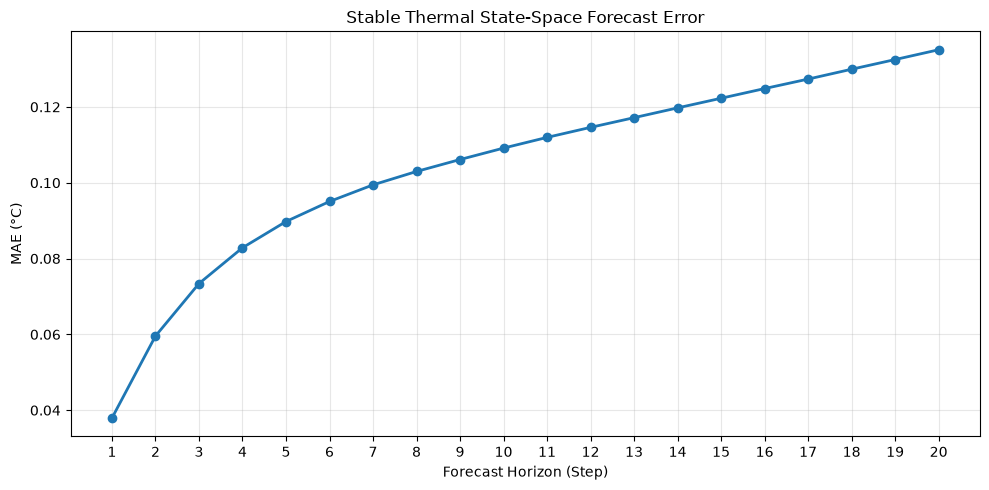

In [177]:

# HORIZON ERROR PLOT


plt.figure(
    figsize=(10, 5)
)

plt.plot(
    range(1, HORIZON + 1),
    stable_horizon_mae,
    marker="o",
    linewidth=2
)

plt.xlabel(
    "Forecast Horizon (Step)"
)

plt.ylabel(
    "MAE (Â°C)"
)

plt.title(
    "Stable Thermal State-Space "
    "Forecast Error"
)

plt.xticks(
    range(1, HORIZON + 1)
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [178]:

# SAVE STABLE STATE-SPACE MODEL


STABLE_MODEL_PATH = (
    MODEL_DIR /
    "stable_thermal_state_space_v1.pth"
)

torch.save(
    {
        "model_state_dict":
            stable_model.state_dict(),

        "input_dim":
            len(FEATURES),

        "hidden_dim":
            64,

        "features":
            FEATURES,

        "sequence_length":
            SEQ_LEN,

        "horizon":
            HORIZON,

        "alpha":
            alpha,

        "beta":
            beta,

        "gamma":
            gamma,

        "val_mae":
            stable_mae,

        "val_rmse":
            stable_rmse,

        "val_r2":
            stable_r2
    },
    STABLE_MODEL_PATH
)

print(
    "Model saved successfully:"
)

print(
    STABLE_MODEL_PATH
)

Model saved successfully:
models\stable_thermal_state_space_v1.pth


In [179]:

# ADAPTIVE THERMAL ROLLOUT


def adaptive_thermal_rollout(
    T_current,
    T_ambient,
    heat_signal,
    alpha,
    beta,
    gamma,
    horizon
):

    temperatures = []

    T = T_current

    for k in range(horizon):

        # ----------------------------------
        # Temperature difference
        # ----------------------------------

        delta_ambient = (
            T -
            T_ambient[:, k]
        )

        # ----------------------------------
        # Bounded cooling
        # ----------------------------------

        cooling = (
            beta *
            torch.tanh(
                delta_ambient / 10.0
            )
        )

        # ----------------------------------
        # Adaptive heating
        # ----------------------------------

        heating = (
            gamma *
            heat_signal
        )

        # ----------------------------------
        # Thermal state update
        # ----------------------------------

        dT = (
            alpha *
            (
                heating -
                cooling
            )
        )

        # ----------------------------------
        # Update temperature
        # ----------------------------------

        T = T + dT

        temperatures.append(T)

    return torch.stack(
        temperatures,
        dim=1
    )

In [180]:

# ADAPTIVE THERMAL ROLLOUT


def adaptive_thermal_rollout(
    T_current,
    T_ambient,
    heat_signal,
    alpha,
    beta,
    gamma,
    horizon
):

    temperatures = []

    T = T_current

    for k in range(horizon):

        # ----------------------------------
        # Temperature difference
        # ----------------------------------

        delta_ambient = (
            T -
            T_ambient[:, k]
        )

        # ----------------------------------
        # Bounded cooling
        # ----------------------------------

        cooling = (
            beta *
            torch.tanh(
                delta_ambient / 10.0
            )
        )

        # ----------------------------------
        # Adaptive heating
        # ----------------------------------

        heating = (
            gamma *
            heat_signal
        )

        # ----------------------------------
        # Thermal state update
        # ----------------------------------

        dT = (
            alpha *
            (
                heating -
                cooling
            )
        )

        # ----------------------------------
        # Update temperature
        # ----------------------------------

        T = T + dT

        temperatures.append(T)

    return torch.stack(
        temperatures,
        dim=1
    )

In [182]:

# INITIALIZE ADAPTIVE MODEL

class AdaptiveThermalStateSpace(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        self.heat_head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.Tanh(),
            nn.Linear(32, 1),
            nn.Tanh()
        )

        self.raw_alpha = nn.Parameter(
            torch.tensor(-3.0)
        )

        self.raw_beta = nn.Parameter(
            torch.tensor(-3.0)
        )

        self.raw_gamma = nn.Parameter(
            torch.tensor(-1.0)
        )

    def forward(self, x):

        z = self.encoder(x)

        heat_signal = self.heat_head(
            z
        ).squeeze(-1)

        alpha = torch.sigmoid(
            self.raw_alpha
        )

        beta = torch.sigmoid(
            self.raw_beta
        )

        gamma = torch.sigmoid(
            self.raw_gamma
        )

        return (
            heat_signal,
            alpha,
            beta,
            gamma
        )
adaptive_model = AdaptiveThermalStateSpace(
    input_dim=len(FEATURES),
    hidden_dim=64
).to(DEVICE)

print(
    adaptive_model
)

AdaptiveThermalStateSpace(
  (encoder): TemporalEncoder(
    (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.1)
  )
  (heat_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
    (3): Tanh()
  )
)


In [183]:

# ADAPTIVE OPTIMIZER


adaptive_optimizer = torch.optim.AdamW(
    adaptive_model.parameters(),
    lr=3e-4,
    weight_decay=1e-5
)

print(
    "Adaptive optimizer ready."
)

Adaptive optimizer ready.


In [184]:

# PRE-TRAINING CHECK


adaptive_model.eval()

batch = next(
    iter(train_physics_loader)
)

X_batch = batch[0].to(DEVICE)

T_current = batch[1].to(DEVICE)

T_future = batch[2].to(DEVICE)

T_ambient = batch[3].to(DEVICE)

with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma
    ) = adaptive_model(
        X_batch
    )

    predictions = adaptive_thermal_rollout(
        T_current,
        T_ambient,
        heat_signal,
        alpha,
        beta,
        gamma,
        HORIZON
    )

print("=" * 60)

print(
    "Heat signal range:",
    heat_signal.min().item(),
    "to",
    heat_signal.max().item()
)

print(
    "Alpha range:",
    alpha.min().item(),
    "to",
    alpha.max().item()
)

print(
    "Beta range:",
    beta.min().item(),
    "to",
    beta.max().item()
)

print(
    "Gamma range:",
    gamma.min().item(),
    "to",
    gamma.max().item()
)

print(
    "Prediction range:",
    predictions.min().item(),
    "to",
    predictions.max().item()
)

print(
    "Actual range:",
    T_future.min().item(),
    "to",
    T_future.max().item()
)

print("=" * 60)

Heat signal range: 0.09993954747915268 to 0.1689414530992508
Alpha range: 0.04742587357759476 to 0.04742587357759476
Beta range: 0.04742587357759476 to 0.04742587357759476
Gamma range: 0.2689414322376251 to 0.2689414322376251
Prediction range: 23.444778442382812 to 106.9140625
Actual range: 23.43415641784668 to 107.0835189819336


In [185]:

# TRAIN ADAPTIVE MODEL


EPOCHS = 5

for epoch in range(EPOCHS):

    adaptive_model.train()

    running_loss = 0.0

    for (
        X_batch,
        T_current,
        T_future,
        T_ambient,
        P_cu
    ) in train_physics_loader:

        X_batch = X_batch.to(DEVICE)

        T_current = T_current.to(DEVICE)

        T_future = T_future.to(DEVICE)

        T_ambient = T_ambient.to(DEVICE)

        adaptive_optimizer.zero_grad()

        # ----------------------------------
        # Adaptive parameters
        # ----------------------------------

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = adaptive_model(
            X_batch
        )

        # ----------------------------------
        # Multi-step prediction
        # ----------------------------------

        predictions = adaptive_thermal_rollout(
            T_current,
            T_ambient,
            heat_signal,
            alpha,
            beta,
            gamma,
            HORIZON
        )

        # ----------------------------------
        # Prediction loss
        # ----------------------------------

        data_loss = F.mse_loss(
            predictions,
            T_future
        )

        # ----------------------------------
        # Smoothness constraint
        # ----------------------------------

        delta_pred = (
            predictions[:, 1:]
            -
            predictions[:, :-1]
        )

        smoothness_loss = (
            delta_pred ** 2
        ).mean()

        # ----------------------------------
        # Parameter regularization
        # ----------------------------------

        parameter_loss = (
            alpha.mean()
            +
            beta.mean()
        )

        # ----------------------------------
        # Total loss
        # ----------------------------------

        total_loss = (
            data_loss
            +
            0.01 * smoothness_loss
            +
            0.001 * parameter_loss
        )

        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            adaptive_model.parameters(),
            max_norm=1.0
        )

        adaptive_optimizer.step()

        running_loss += (
            total_loss.item()
        )

    epoch_loss = (
        running_loss /
        len(train_physics_loader)
    )

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.6f}"
    )

Epoch 01/5 | Loss: 0.037571
Epoch 02/5 | Loss: 0.035211
Epoch 03/5 | Loss: 0.034637
Epoch 04/5 | Loss: 0.034434
Epoch 05/5 | Loss: 0.034283


In [187]:

# LEARNED PARAMETER ANALYSIS


adaptive_model.eval()

alpha_values = []
beta_values = []
gamma_values = []

with torch.no_grad():

    for (
        X_batch,
        T_current,
        T_future,
        T_ambient,
        P_cu
    ) in val_physics_loader:

        X_batch = X_batch.to(DEVICE)

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = adaptive_model(
            X_batch
        )

        alpha_values.append(
            alpha.cpu().numpy()
        )

        beta_values.append(
            beta.cpu().numpy()
        )

        gamma_values.append(
            gamma.cpu().numpy()
        )
        alpha_values = [np.atleast_1d(a.squeeze()) for a in alpha_values]
        beta_values = [np.atleast_1d(b.squeeze()) for b in beta_values]
        gamma_values = [np.atleast_1d(g.squeeze()) for g in gamma_values]
alpha_values = np.concatenate(
    alpha_values
)

beta_values = np.concatenate(
    beta_values
)

gamma_values = np.concatenate(
    gamma_values
)


print("=" * 60)

print("ALPHA")

print(
    "Mean:",
    alpha_values.mean()
)

print(
    "Std:",
    alpha_values.std()
)

print(
    "Min:",
    alpha_values.min()
)

print(
    "Max:",
    alpha_values.max()
)


print("\nBETA")

print(
    "Mean:",
    beta_values.mean()
)

print(
    "Std:",
    beta_values.std()
)

print(
    "Min:",
    beta_values.min()
)

print(
    "Max:",
    beta_values.max()
)


print("\nGAMMA")

print(
    "Mean:",
    gamma_values.mean()
)

print(
    "Std:",
    gamma_values.std()
)

print(
    "Min:",
    gamma_values.min()
)

print(
    "Max:",
    gamma_values.max()
)

print("=" * 60)

ALPHA
Mean: 0.11177422
Std: 1.4901161e-08
Min: 0.111774236
Max: 0.111774236

BETA
Mean: 0.04162106
Std: 3.7252903e-09
Min: 0.041621055
Max: 0.041621055

GAMMA
Mean: 0.46678752
Std: 2.9802322e-08
Min: 0.46678755
Max: 0.46678755


In [188]:

# ADAPTIVE VALIDATION


adaptive_model.eval()

adaptive_predictions = []
adaptive_actual = []

with torch.no_grad():

    for (
        X_batch,
        T_current,
        T_future,
        T_ambient,
        P_cu
    ) in val_physics_loader:

        X_batch = X_batch.to(DEVICE)

        T_current = T_current.to(DEVICE)

        T_ambient = T_ambient.to(DEVICE)

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = adaptive_model(
            X_batch
        )

        predictions = adaptive_thermal_rollout(
            T_current,
            T_ambient,
            heat_signal,
            alpha,
            beta,
            gamma,
            HORIZON
        )

        adaptive_predictions.append(
            predictions.cpu().numpy()
        )

        adaptive_actual.append(
            T_future.numpy()
        )


adaptive_predictions = np.concatenate(
    adaptive_predictions,
    axis=0
)

adaptive_actual = np.concatenate(
    adaptive_actual,
    axis=0
)


print(
    "Prediction shape:",
    adaptive_predictions.shape
)

print(
    "Actual shape:",
    adaptive_actual.shape
)

print(
    "Predicted range:",
    adaptive_predictions.min(),
    "to",
    adaptive_predictions.max()
)

print(
    "Actual range:",
    adaptive_actual.min(),
    "to",
    adaptive_actual.max()
)

Prediction shape: (210430, 20)
Actual shape: (210430, 20)
Predicted range: 22.804256 to 109.42311
Actual range: 22.792233 to 109.33385


In [189]:

# ADAPTIVE HORIZON MAE


adaptive_horizon_mae = []

print(
    "Adaptive horizon-wise MAE:"
)

print("-" * 40)

for k in range(HORIZON):

    mae = mean_absolute_error(
        adaptive_actual[:, k],
        adaptive_predictions[:, k]
    )

    adaptive_horizon_mae.append(
        mae
    )

    print(
        f"Step {k+1:02d}: "
        f"{mae:.4f} Â°C"
    )

adaptive_horizon_mae = np.asarray(
    adaptive_horizon_mae
)

Adaptive horizon-wise MAE:
----------------------------------------
Step 01: 0.0380 Â°C
Step 02: 0.0597 Â°C
Step 03: 0.0736 Â°C
Step 04: 0.0831 Â°C
Step 05: 0.0901 Â°C
Step 06: 0.0955 Â°C
Step 07: 0.0999 Â°C
Step 08: 0.1035 Â°C
Step 09: 0.1068 Â°C
Step 10: 0.1099 Â°C
Step 11: 0.1128 Â°C
Step 12: 0.1155 Â°C
Step 13: 0.1182 Â°C
Step 14: 0.1208 Â°C
Step 15: 0.1235 Â°C
Step 16: 0.1262 Â°C
Step 17: 0.1288 Â°C
Step 18: 0.1315 Â°C
Step 19: 0.1342 Â°C
Step 20: 0.1368 Â°C


In [190]:

# STATIC VS ADAPTIVE


print("=" * 70)
print("STATIC vs ADAPTIVE THERMAL STATE-SPACE")
print("=" * 70)

print(
    f"Static MAE    : {stable_mae:.4f} Â°C"
)

print(
    f"Adaptive MAE  : {adaptive_mae:.4f} Â°C"
)

print()

print(
    f"Static RMSE   : {stable_rmse:.4f} Â°C"
)

print(
    f"Adaptive RMSE : {adaptive_rmse:.4f} Â°C"
)

print()

print(
    f"Static RÂ²     : {stable_r2:.5f}"
)

print(
    f"Adaptive RÂ²   : {adaptive_r2:.5f}"
)

# ------------------------------------------
# Improvement
# ------------------------------------------

mae_improvement = (
    stable_mae -
    adaptive_mae
)

rmse_improvement = (
    stable_rmse -
    adaptive_rmse
)

print()

print(
    f"MAE improvement : "
    f"{mae_improvement:.4f} Â°C"
)

print(
    f"RMSE improvement: "
    f"{rmse_improvement:.4f} Â°C"
)

print("=" * 70)

STATIC vs ADAPTIVE THERMAL STATE-SPACE
Static MAE    : 0.1046 Â°C
Adaptive MAE  : 0.0396 Â°C

Static RMSE   : 0.2037 Â°C
Adaptive RMSE : 0.0914 Â°C

Static RÂ²     : 0.99984
Adaptive RÂ²   : 0.99998

MAE improvement : 0.0650 Â°C
RMSE improvement: 0.1123 Â°C


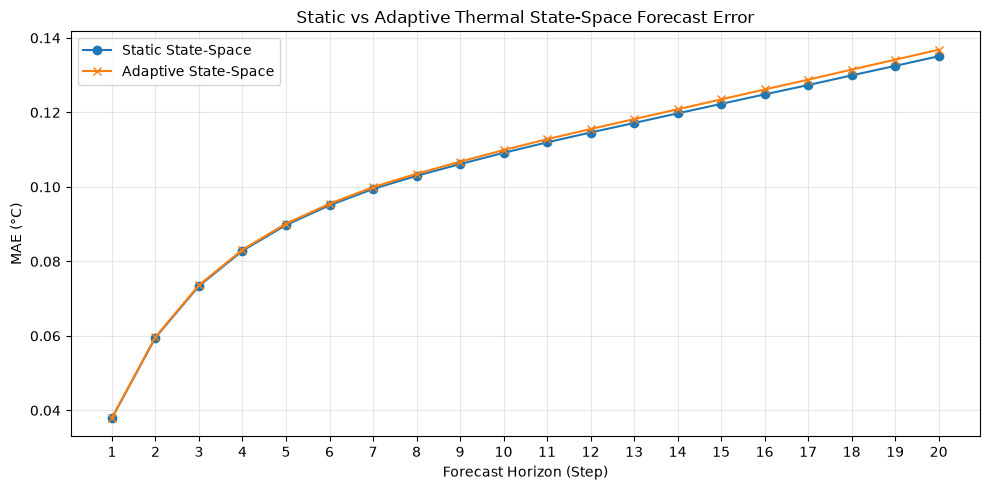

In [191]:

# BLOCK 18.42 â€” STATIC VS ADAPTIVE
# HORIZON CURVES


plt.figure(
    figsize=(10, 5)
)

plt.plot(
    range(1, HORIZON + 1),
    stable_horizon_mae,
    marker="o",
    label="Static State-Space"
)

plt.plot(
    range(1, HORIZON + 1),
    adaptive_horizon_mae,
    marker="x",
    label="Adaptive State-Space"
)

plt.xlabel(
    "Forecast Horizon (Step)"
)

plt.ylabel(
    "MAE (Â°C)"
)

plt.title(
    "Static vs Adaptive Thermal "
    "State-Space Forecast Error"
)

plt.xticks(
    range(1, HORIZON + 1)
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()

In [192]:

# OPERATING CONDITION FEATURES


OPERATING_FEATURES = [
    "motor_speed",
    "torque",
    "I_mag",
    "V_mag",
    "P_elec",
    "P_mech",
    "P_cu",
    "ambient",
    "coolant"
]

print(
    "Operating features:"
)

print(
    OPERATING_FEATURES
)

print(
    "\nNumber of operating features:",
    len(OPERATING_FEATURES)
)

Operating features:
['motor_speed', 'torque', 'I_mag', 'V_mag', 'P_elec', 'P_mech', 'P_cu', 'ambient', 'coolant']

Number of operating features: 9


In [193]:

# VERIFY OPERATING FEATURES


missing_features = [
    f
    for f in OPERATING_FEATURES
    if f not in train_df.columns
]

if len(missing_features) > 0:

    raise ValueError(
        f"Missing features: {missing_features}"
    )

print(
    "All operating features are available."
)

print(
    train_df[OPERATING_FEATURES]
    .describe()
)

All operating features are available.
         motor_speed         torque          I_mag          V_mag  \
count  932600.000000  932600.000000  932600.000000  932600.000000   
mean     2173.466742      32.720216     109.251933      81.811599   
std      1829.057608      78.407722      86.018513      52.930358   
min      -275.549144    -246.466663       0.000660       0.000002   
25%       419.989220      -0.070530      16.052518      21.579354   
50%      1999.976562      14.754075     114.473394     106.682387   
75%      3528.895512      95.325823     175.374723     130.717551   
max      6000.015137     261.005707     361.515337     134.264098   

              P_elec         P_mech          P_cu        ambient  \
count  932600.000000  932600.000000  9.326000e+05  932600.000000   
mean     5311.340108    6845.003352  9.667581e+02      24.604125   
std     12400.104368   18554.503657  1.105531e+03       1.981829   
min    -31011.640538  -55121.485348  2.179106e-08       8.783478   


Adaptive model using explicit operating state

I will keep the successful temporal encoder, but create the adaptive parameters from the final timestep's operating conditions.

In [194]:

# BLOCK 18.45 â€” PHYSICALLY CONDITIONED
# ADAPTIVE MODEL


class OperatingConditionAdaptiveModel(nn.Module):

    def __init__(
        self,
        input_dim,
        operating_dim,
        hidden_dim=64
    ):

        super().__init__()

        # ----------------------------------
        # Temporal encoder
        # ----------------------------------

        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # ----------------------------------
        # Operating-condition encoder
        # ----------------------------------

        self.operating_encoder = nn.Sequential(

            nn.Linear(
                operating_dim,
                32
            ),

            nn.LayerNorm(32),

            nn.Tanh(),

            nn.Linear(
                32,
                32
            ),

            nn.Tanh()
        )

        # ----------------------------------
        # Combined representation
        # ----------------------------------

        self.condition_fusion = nn.Sequential(

            nn.Linear(
                hidden_dim + 32,
                32
            ),

            nn.Tanh()
        )

        # ----------------------------------
        # Heat generation
        # ----------------------------------

        self.heat_head = nn.Sequential(

            nn.Linear(
                32,
                16
            ),

            nn.Tanh(),

            nn.Linear(
                16,
                1
            ),

            nn.Tanh()
        )

        # ----------------------------------
        # Alpha
        # ----------------------------------

        self.alpha_head = nn.Sequential(

            nn.Linear(
                32,
                16
            ),

            nn.Tanh(),

            nn.Linear(
                16,
                1
            ),

            nn.Sigmoid()
        )

        # ----------------------------------
        # Beta
        # ----------------------------------

        self.beta_head = nn.Sequential(

            nn.Linear(
                32,
                16
            ),

            nn.Tanh(),

            nn.Linear(
                16,
                1
            ),

            nn.Sigmoid()
        )

        # ----------------------------------
        # Gamma
        # ----------------------------------

        self.gamma_head = nn.Sequential(

            nn.Linear(
                32,
                16
            ),

            nn.Tanh(),

            nn.Linear(
                16,
                1
            ),

            nn.Sigmoid()
        )


    def forward(
        self,
        x,
        operating_state
    ):

        # ----------------------------------
        # Temporal representation
        # ----------------------------------

        temporal_state = self.encoder(
            x
        )

        # ----------------------------------
        # Operating representation
        # ----------------------------------

        operating_state = self.operating_encoder(
            operating_state
        )

        # ----------------------------------
        # Fusion
        # ----------------------------------

        condition = self.condition_fusion(
            torch.cat(
                [
                    temporal_state,
                    operating_state
                ],
                dim=1
            )
        )

        # ----------------------------------
        # Adaptive parameters
        # ----------------------------------

        alpha = (
            0.005
            +
            0.20 *
            self.alpha_head(condition)
        ).squeeze(-1)

        beta = (
            0.005
            +
            0.20 *
            self.beta_head(condition)
        ).squeeze(-1)

        gamma = self.gamma_head(
            condition
        ).squeeze(-1)

        heat_signal = self.heat_head(
            condition
        ).squeeze(-1)

        return (
            heat_signal,
            alpha,
            beta,
            gamma
        )

In [195]:

#  OPERATING CONDITION DATASET


class OperatingConditionDataset(Dataset):

    def __init__(
        self,
        scaled_df,
        raw_df,
        features,
        operating_features,
        seq_len,
        horizon
    ):

        self.scaled_df = scaled_df
        self.raw_df = raw_df

        self.features = features
        self.operating_features = operating_features

        self.seq_len = seq_len
        self.horizon = horizon

        self.samples = []

        # ----------------------------------
        # Build valid sequence locations
        # ----------------------------------

        for profile_id in raw_df["profile_id"].unique():

            raw_group = (
                raw_df[
                    raw_df["profile_id"] == profile_id
                ]
                .reset_index(drop=True)
            )

            scaled_group = (
                scaled_df[
                    scaled_df["profile_id"] == profile_id
                ]
                .reset_index(drop=True)
            )

            max_start = (
                len(raw_group)
                -
                seq_len
                -
                horizon
                +
                1
            )

            for start in range(
                max_start
            ):

                self.samples.append(
                    (
                        profile_id,
                        start
                    )
                )


    def __len__(self):

        return len(
            self.samples
        )


    def __getitem__(self, idx):

        profile_id, start = (
            self.samples[idx]
        )

        raw_group = (
            self.raw_df[
                self.raw_df["profile_id"]
                == profile_id
            ]
            .reset_index(drop=True)
        )

        scaled_group = (
            self.scaled_df[
                self.scaled_df["profile_id"]
                == profile_id
            ]
            .reset_index(drop=True)
        )

        end = (
            start +
            self.seq_len
        )

        future_end = (
            end +
            self.horizon
        )

        # ----------------------------------
        # Input sequence
        # ----------------------------------

        X = (
            scaled_group[
                self.features
            ]
            .iloc[start:end]
            .values
            .astype(np.float32)
        )

        # ----------------------------------
        # Current temperature
        # ----------------------------------

        T_current = np.float32(
            raw_group[
                "pm"
            ].iloc[end - 1]
        )

        # ----------------------------------
        # Future temperature
        # ----------------------------------

        T_future = (
            raw_group[
                "pm"
            ]
            .iloc[end:future_end]
            .values
            .astype(np.float32)
        )

        # ----------------------------------
        # Ambient temperature
        # ----------------------------------

        T_ambient = (
            raw_group[
                "ambient"
            ]
            .iloc[end:future_end]
            .values
            .astype(np.float32)
        )

        # ----------------------------------
        # Operating state
        # ----------------------------------

        operating_state = (
            scaled_group[
                self.operating_features
            ]
            .iloc[end - 1]
            .values
            .astype(np.float32)
        )

        return (

            torch.from_numpy(X),

            torch.tensor(
                T_current,
                dtype=torch.float32
            ),

            torch.from_numpy(
                T_future
            ),

            torch.from_numpy(
                T_ambient
            ),

            torch.from_numpy(
                operating_state
            )
        )

In [196]:

# CREATE OPERATING DATASETS


adaptive_train_dataset = OperatingConditionDataset(
    scaled_df=train_scaled,
    raw_df=train_df,
    features=FEATURES,
    operating_features=OPERATING_FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

adaptive_val_dataset = OperatingConditionDataset(
    scaled_df=val_scaled,
    raw_df=val_df,
    features=FEATURES,
    operating_features=OPERATING_FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

print(
    "Training sequences:",
    len(adaptive_train_dataset)
)

print(
    "Validation sequences:",
    len(adaptive_val_dataset)
)

Training sequences: 925544
Validation sequences: 210430


In [197]:


#  ADAPTIVE DATALOADERS


adaptive_train_loader = DataLoader(
    adaptive_train_dataset,
    batch_size=256,
    shuffle=True,
    num_workers=0
)

adaptive_val_loader = DataLoader(
    adaptive_val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

print(
    "Adaptive loaders ready."
)

Adaptive loaders ready.


In [198]:

# VERIFY ADAPTIVE BATCH


batch = next(
    iter(adaptive_train_loader)
)

X_batch = batch[0]

T_current = batch[1]

T_future = batch[2]

T_ambient = batch[3]

operating_state = batch[4]

print(
    "X:",
    X_batch.shape
)

print(
    "T_current:",
    T_current.shape
)

print(
    "T_future:",
    T_future.shape
)

print(
    "T_ambient:",
    T_ambient.shape
)

print(
    "Operating state:",
    operating_state.shape
)

print(
    "Expected operating dimension:",
    len(OPERATING_FEATURES)
)

X: torch.Size([256, 128, 13])
T_current: torch.Size([256])
T_future: torch.Size([256, 20])
T_ambient: torch.Size([256, 20])
Operating state: torch.Size([256, 9])
Expected operating dimension: 9


In [199]:

# INITIALIZE OPERATING - CONDITION ADAPTIVE MODEL


adaptive_oc_model = OperatingConditionAdaptiveModel(
    input_dim=len(FEATURES),
    operating_dim=len(OPERATING_FEATURES),
    hidden_dim=64
).to(DEVICE)

print(
    "Operating-condition adaptive model created."
)

print(
    "Input dimension:",
    len(FEATURES)
)

print(
    "Operating dimension:",
    len(OPERATING_FEATURES)
)

print(
    "Device:",
    DEVICE
)

Operating-condition adaptive model created.
Input dimension: 13
Operating dimension: 9
Device: cuda


In [200]:

# ADAPTIVE MODEL OPTIMIZER


adaptive_oc_optimizer = torch.optim.AdamW(
    adaptive_oc_model.parameters(),
    lr=3e-4,
    weight_decay=1e-5
)

print(
    "Optimizer ready."
)

Optimizer ready.


In [201]:

# PRE-TRAINING STABILITY TEST


adaptive_oc_model.eval()

batch = next(
    iter(adaptive_train_loader)
)

X_batch = batch[0].to(DEVICE)

T_current = batch[1].to(DEVICE)

T_future = batch[2].to(DEVICE)

T_ambient = batch[3].to(DEVICE)

operating_state = batch[4].to(DEVICE)


with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma
    ) = adaptive_oc_model(
        X_batch,
        operating_state
    )

    predictions = adaptive_thermal_rollout(
        T_current,
        T_ambient,
        heat_signal,
        alpha,
        beta,
        gamma,
        HORIZON
    )


print("=" * 60)

print(
    "Heat signal range:",
    heat_signal.min().item(),
    "to",
    heat_signal.max().item()
)

print(
    "Alpha range:",
    alpha.min().item(),
    "to",
    alpha.max().item()
)

print(
    "Beta range:",
    beta.min().item(),
    "to",
    beta.max().item()
)

print(
    "Gamma range:",
    gamma.min().item(),
    "to",
    gamma.max().item()
)

print(
    "Prediction range:",
    predictions.min().item(),
    "to",
    predictions.max().item()
)

print(
    "Actual range:",
    T_future.min().item(),
    "to",
    T_future.max().item()
)

print("=" * 60)

Heat signal range: -0.12280711531639099 to 0.00943325087428093
Alpha range: 0.0919027030467987 to 0.09497669339179993
Beta range: 0.11064369231462479 to 0.11693380773067474
Gamma range: 0.4739476442337036 to 0.5045074224472046
Prediction range: 21.890178680419922 to 113.21009826660156
Actual range: 21.91987419128418 to 113.27691650390625


In [203]:

# FAST OPERATING-CONDITION
# DATASET


class FastOperatingConditionDataset(Dataset):

    def __init__(
        self,
        scaled_df,
        raw_df,
        features,
        operating_features,
        seq_len,
        horizon
    ):

        self.seq_len = seq_len
        self.horizon = horizon

        self.features = features
        self.operating_features = operating_features

        # ----------------------------------
        # Store arrays directly
        # ----------------------------------

        self.X_data = scaled_df[
            features
        ].values.astype(
            np.float32
        )

        self.T_data = raw_df[
            "pm"
        ].values.astype(
            np.float32
        )

        self.ambient_data = raw_df[
            "ambient"
        ].values.astype(
            np.float32
        )

        self.operating_data = scaled_df[
            operating_features
        ].values.astype(
            np.float32
        )

        self.profile_ids = raw_df[
            "profile_id"
        ].values

        # ----------------------------------
        # Generate valid sequence starts
        # ----------------------------------

        self.indices = []

        profile_values = (
            raw_df["profile_id"]
            .values
        )

        unique_profiles = np.unique(
            profile_values
        )

        for profile_id in unique_profiles:

            positions = np.where(
                profile_values == profile_id
            )[0]

            if len(positions) < (
                seq_len + horizon
            ):
                continue

            # ----------------------------------
            # Profile is contiguous in dataframe
            # ----------------------------------

            start_pos = positions[0]

            end_pos = positions[-1]

            last_start = (
                end_pos
                -
                seq_len
                -
                horizon
                +
                1
            )

            for start in range(
                start_pos,
                last_start + 1
            ):

                self.indices.append(
                    start
                )

        self.indices = np.asarray(
            self.indices,
            dtype=np.int64
        )

        print(
            "Dataset created:"
        )

        print(
            "Sequences:",
            len(self.indices)
        )


    def __len__(self):

        return len(
            self.indices
        )


    def __getitem__(self, idx):

        start = self.indices[idx]

        seq_end = (
            start +
            self.seq_len
        )

        future_end = (
            seq_end +
            self.horizon
        )

        # ----------------------------------
        # Input sequence
        # ----------------------------------

        X = self.X_data[
            start:seq_end
        ]

        # ----------------------------------
        # Current temperature
        # ----------------------------------

        T_current = self.T_data[
            seq_end - 1
        ]

        # ----------------------------------
        # Future temperatures
        # ----------------------------------

        T_future = self.T_data[
            seq_end:future_end
        ]

        # ----------------------------------
        # Future ambient temperature
        # ----------------------------------

        T_ambient = self.ambient_data[
            seq_end:future_end
        ]

        # ----------------------------------
        # Current operating condition
        # ----------------------------------

        operating_state = self.operating_data[
            seq_end - 1
        ]

        return (

            torch.from_numpy(
                X
            ),

            torch.tensor(
                T_current,
                dtype=torch.float32
            ),

            torch.from_numpy(
                T_future
            ),

            torch.from_numpy(
                T_ambient
            ),

            torch.from_numpy(
                operating_state
            )
        )

In [204]:

# FAST DATASETS


adaptive_train_dataset = (
    FastOperatingConditionDataset(
        scaled_df=train_scaled,
        raw_df=train_df,
        features=FEATURES,
        operating_features=OPERATING_FEATURES,
        seq_len=SEQ_LEN,
        horizon=HORIZON
    )
)

adaptive_val_dataset = (
    FastOperatingConditionDataset(
        scaled_df=val_scaled,
        raw_df=val_df,
        features=FEATURES,
        operating_features=OPERATING_FEATURES,
        seq_len=SEQ_LEN,
        horizon=HORIZON
    )
)

print(
    "\nTrain sequences:",
    len(adaptive_train_dataset)
)

print(
    "Validation sequences:",
    len(adaptive_val_dataset)
)

Dataset created:
Sequences: 925544
Dataset created:
Sequences: 210430

Train sequences: 925544
Validation sequences: 210430


In [205]:

# FAST DATALOADERS


adaptive_train_loader = DataLoader(
    adaptive_train_dataset,
    batch_size=512,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

adaptive_val_loader = DataLoader(
    adaptive_val_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(
    "DataLoaders created."
)

DataLoaders created.


In [206]:

# DATA LOADING SPEED TEST


import time

start_time = time.time()

batch = next(
    iter(adaptive_train_loader)
)

elapsed = (
    time.time() -
    start_time
)

X_batch = batch[0]
T_current = batch[1]
T_future = batch[2]
T_ambient = batch[3]
operating_state = batch[4]

print(
    "First batch loading time:",
    f"{elapsed:.3f} seconds"
)

print()

print(
    "X:",
    X_batch.shape
)

print(
    "T_current:",
    T_current.shape
)

print(
    "T_future:",
    T_future.shape
)

print(
    "T_ambient:",
    T_ambient.shape
)

print(
    "Operating state:",
    operating_state.shape
)

First batch loading time: 0.157 seconds

X: torch.Size([512, 128, 13])
T_current: torch.Size([512])
T_future: torch.Size([512, 20])
T_ambient: torch.Size([512, 20])
Operating state: torch.Size([512, 9])


In [207]:

# MULTI-BATCH SPEED TEST


import time

start_time = time.time()

test_batches = 10

for batch_number, batch in enumerate(
    adaptive_train_loader
):

    if batch_number >= test_batches:
        break

elapsed = (
    time.time() -
    start_time
)

print(
    f"Loaded {test_batches} batches in "
    f"{elapsed:.3f} seconds"
)

print(
    f"Average batch time: "
    f"{elapsed / test_batches:.3f} seconds"
)

Loaded 10 batches in 0.311 seconds
Average batch time: 0.031 seconds


In [208]:

# INITIALIZE MODEL


adaptive_oc_model = OperatingConditionAdaptiveModel(
    input_dim=len(FEATURES),
    operating_dim=len(OPERATING_FEATURES),
    hidden_dim=64
).to(DEVICE)

print(
    "Model initialized."
)

print(
    "Device:",
    DEVICE
)

Model initialized.
Device: cuda


In [209]:

# OPTIMIZER


adaptive_oc_optimizer = torch.optim.AdamW(
    adaptive_oc_model.parameters(),
    lr=3e-4,
    weight_decay=1e-5
)

print(
    "Optimizer ready."
)

Optimizer ready.


In [210]:

# ONE-BATCH TRAINING TEST


adaptive_oc_model.train()

batch = next(
    iter(adaptive_train_loader)
)

X_batch = batch[0].to(DEVICE)

T_current = batch[1].to(DEVICE)

T_future = batch[2].to(DEVICE)

T_ambient = batch[3].to(DEVICE)

operating_state = batch[4].to(DEVICE)


start_time = time.time()

adaptive_oc_optimizer.zero_grad()

(
    heat_signal,
    alpha,
    beta,
    gamma
) = adaptive_oc_model(
    X_batch,
    operating_state
)

predictions = adaptive_thermal_rollout(
    T_current,
    T_ambient,
    heat_signal,
    alpha,
    beta,
    gamma,
    HORIZON
)

loss = F.mse_loss(
    predictions,
    T_future
)

loss.backward()

adaptive_oc_optimizer.step()

elapsed = (
    time.time() -
    start_time
)

print(
    "One-batch training test complete."
)

print(
    f"Time: {elapsed:.3f} seconds"
)

print(
    f"Loss: {loss.item():.6f}"
)

print(
    "Prediction range:",
    predictions.min().item(),
    "to",
    predictions.max().item()
)

One-batch training test complete.
Time: 0.045 seconds
Loss: 0.072955
Prediction range: 21.7036190032959 to 111.26837921142578


In [211]:

# TRAIN OPERATING-CONDITION
# ADAPTIVE MODEL


import time

EPOCHS = 5

epoch_history = []

for epoch in range(EPOCHS):

    epoch_start = time.time()

    adaptive_oc_model.train()

    running_loss = 0.0
    running_data_loss = 0.0
    running_smooth_loss = 0.0

    num_batches = 0

    for (
        X_batch,
        T_current,
        T_future,
        T_ambient,
        operating_state
    ) in adaptive_train_loader:

        # ----------------------------------
        # Move data to device
        # ----------------------------------

        X_batch = X_batch.to(
            DEVICE,
            non_blocking=True
        )

        T_current = T_current.to(
            DEVICE,
            non_blocking=True
        )

        T_future = T_future.to(
            DEVICE,
            non_blocking=True
        )

        T_ambient = T_ambient.to(
            DEVICE,
            non_blocking=True
        )

        operating_state = operating_state.to(
            DEVICE,
            non_blocking=True
        )

        # ----------------------------------
        # Reset gradients
        # ----------------------------------

        adaptive_oc_optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------
        # Adaptive thermal parameters
        # ----------------------------------

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = adaptive_oc_model(
            X_batch,
            operating_state
        )

        # ----------------------------------
        # Multi-step thermal rollout
        # ----------------------------------

        predictions = adaptive_thermal_rollout(
            T_current,
            T_ambient,
            heat_signal,
            alpha,
            beta,
            gamma,
            HORIZON
        )

        # ----------------------------------
        # Prediction loss
        # ----------------------------------

        data_loss = F.mse_loss(
            predictions,
            T_future
        )

        # ----------------------------------
        # Temporal smoothness
        # ----------------------------------

        predicted_delta = (
            predictions[:, 1:]
            -
            predictions[:, :-1]
        )

        smoothness_loss = (
            predicted_delta ** 2
        ).mean()

        # ----------------------------------
        # Mild parameter variation
        # ----------------------------------

        alpha_std = alpha.std()

        beta_std = beta.std()

        gamma_std = gamma.std()

        variation_penalty = (
            torch.exp(-20.0 * alpha_std)
            +
            torch.exp(-20.0 * beta_std)
            +
            torch.exp(-20.0 * gamma_std)
        )

        # ----------------------------------
        # Total loss
        # ----------------------------------

        total_loss = (
            data_loss
            +
            0.01 * smoothness_loss
            +
            0.00001 * variation_penalty
        )

        # ----------------------------------
        # Backpropagation
        # ----------------------------------

        total_loss.backward()

        # ----------------------------------
        # Gradient clipping
        # ----------------------------------

        torch.nn.utils.clip_grad_norm_(
            adaptive_oc_model.parameters(),
            max_norm=1.0
        )

        # ----------------------------------
        # Optimizer update
        # ----------------------------------

        adaptive_oc_optimizer.step()

        # ----------------------------------
        # Accumulate
        # ----------------------------------

        running_loss += total_loss.item()

        running_data_loss += data_loss.item()

        running_smooth_loss += (
            smoothness_loss.item()
        )

        num_batches += 1

    # --------------------------------------
    # Epoch statistics
    # --------------------------------------

    epoch_loss = (
        running_loss /
        num_batches
    )

    epoch_data_loss = (
        running_data_loss /
        num_batches
    )

    epoch_smooth_loss = (
        running_smooth_loss /
        num_batches
    )

    epoch_time = (
        time.time() -
        epoch_start
    )

    epoch_history.append(
        {
            "epoch": epoch + 1,
            "loss": epoch_loss,
            "data_loss": epoch_data_loss,
            "smooth_loss": epoch_smooth_loss,
            "time_sec": epoch_time
        }
    )

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.6f} | "
        f"Data: {epoch_data_loss:.6f} | "
        f"Smooth: {epoch_smooth_loss:.6f} | "
        f"Time: {epoch_time:.1f}s"
    )

Epoch 01/5 | Loss: 0.036784 | Data: 0.036764 | Smooth: 0.000064 | Time: 90.9s
Epoch 02/5 | Loss: 0.034832 | Data: 0.034817 | Smooth: 0.000078 | Time: 86.0s
Epoch 03/5 | Loss: 0.034452 | Data: 0.034439 | Smooth: 0.000081 | Time: 84.9s
Epoch 04/5 | Loss: 0.034156 | Data: 0.034143 | Smooth: 0.000083 | Time: 83.2s
Epoch 05/5 | Loss: 0.034060 | Data: 0.034047 | Smooth: 0.000084 | Time: 84.1s


In [212]:

# TRAINING HISTORY


history_df = pd.DataFrame(
    epoch_history
)

display(
    history_df
)

,epoch,loss,data_loss,smooth_loss,time_sec
0,1,0.036784,0.036764,0.000064,90.945156
1,2,0.034832,0.034817,0.000078,85.980298
2,3,0.034452,0.034439,0.000081,84.901193
3,4,0.034156,0.034143,0.000083,83.163750
4,5,0.034060,0.034047,0.000084,84.067372


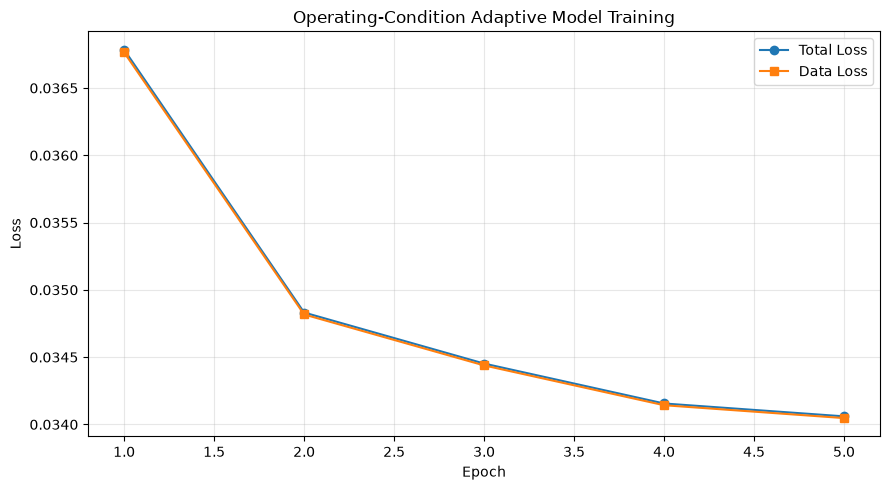

In [213]:
plt.figure(
    figsize=(9, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["loss"],
    marker="o",
    label="Total Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["data_loss"],
    marker="s",
    label="Data Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Operating-Condition Adaptive Model Training"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()

In [214]:

# PARAMETER VARIATION


adaptive_oc_model.eval()

alpha_values = []
beta_values = []
gamma_values = []

with torch.no_grad():

    for batch in adaptive_val_loader:

        X_batch = batch[0].to(DEVICE)

        operating_state = batch[4].to(DEVICE)

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = adaptive_oc_model(
            X_batch,
            operating_state
        )

        alpha_values.append(
            alpha.cpu().numpy()
        )

        beta_values.append(
            beta.cpu().numpy()
        )

        gamma_values.append(
            gamma.cpu().numpy()
        )


alpha_values = np.concatenate(
    alpha_values
)

beta_values = np.concatenate(
    beta_values
)

gamma_values = np.concatenate(
    gamma_values
)


print("=" * 60)

print("ALPHA")
print(
    f"Mean : {alpha_values.mean():.8f}"
)
print(
    f"Std  : {alpha_values.std():.8f}"
)
print(
    f"Min  : {alpha_values.min():.8f}"
)
print(
    f"Max  : {alpha_values.max():.8f}"
)

print()

print("BETA")
print(
    f"Mean : {beta_values.mean():.8f}"
)
print(
    f"Std  : {beta_values.std():.8f}"
)
print(
    f"Min  : {beta_values.min():.8f}"
)
print(
    f"Max  : {beta_values.max():.8f}"
)

print()

print("GAMMA")
print(
    f"Mean : {gamma_values.mean():.8f}"
)
print(
    f"Std  : {gamma_values.std():.8f}"
)
print(
    f"Min  : {gamma_values.min():.8f}"
)
print(
    f"Max  : {gamma_values.max():.8f}"
)

print("=" * 60)

ALPHA
Mean : 0.15005167
Std  : 0.04235561
Min  : 0.03819891
Max  : 0.19593343

BETA
Mean : 0.15235265
Std  : 0.02832566
Min  : 0.07243413
Max  : 0.18658824

GAMMA
Mean : 0.42770925
Std  : 0.06184866
Min  : 0.32111612
Max  : 0.60952812


In [215]:

# VALIDATION PREDICTIONS


adaptive_oc_model.eval()

adaptive_oc_predictions = []
adaptive_oc_actual = []

with torch.no_grad():

    for batch in adaptive_val_loader:

        X_batch = batch[0].to(DEVICE)

        T_current = batch[1].to(DEVICE)

        T_future = batch[2].to(DEVICE)

        T_ambient = batch[3].to(DEVICE)

        operating_state = batch[4].to(DEVICE)

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = adaptive_oc_model(
            X_batch,
            operating_state
        )

        predictions = adaptive_thermal_rollout(
            T_current,
            T_ambient,
            heat_signal,
            alpha,
            beta,
            gamma,
            HORIZON
        )

        adaptive_oc_predictions.append(
            predictions.cpu().numpy()
        )

        adaptive_oc_actual.append(
            T_future.cpu().numpy()
        )


adaptive_oc_predictions = np.concatenate(
    adaptive_oc_predictions,
    axis=0
)

adaptive_oc_actual = np.concatenate(
    adaptive_oc_actual,
    axis=0
)


print(
    "Prediction shape:",
    adaptive_oc_predictions.shape
)

print(
    "Actual shape:",
    adaptive_oc_actual.shape
)

print(
    "Predicted range:",
    adaptive_oc_predictions.min(),
    "to",
    adaptive_oc_predictions.max()
)

print(
    "Actual range:",
    adaptive_oc_actual.min(),
    "to",
    adaptive_oc_actual.max()
)

Prediction shape: (210430, 20)
Actual shape: (210430, 20)
Predicted range: 22.803867 to 109.45073
Actual range: 22.792233 to 109.33385


In [216]:

# OVERALL METRICS

adaptive_oc_mae = mean_absolute_error(
    adaptive_oc_actual.flatten(),
    adaptive_oc_predictions.flatten()
)

adaptive_oc_rmse = np.sqrt(
    mean_squared_error(
        adaptive_oc_actual.flatten(),
        adaptive_oc_predictions.flatten()
    )
)

adaptive_oc_r2 = r2_score(
    adaptive_oc_actual.flatten(),
    adaptive_oc_predictions.flatten()
)


print("=" * 60)

print(
    f"Operating-conditioned MAE : "
    f"{adaptive_oc_mae:.6f} Â°C"
)

print(
    f"Operating-conditioned RMSE: "
    f"{adaptive_oc_rmse:.6f} Â°C"
)

print(
    f"Operating-conditioned RÂ²  : "
    f"{adaptive_oc_r2:.6f}"
)

print("=" * 60)

Operating-conditioned MAE : 0.106730 Â°C
Operating-conditioned RMSE: 0.204843 Â°C
Operating-conditioned RÂ²  : 0.999843


In [217]:

# HORIZON-WISE MAE


adaptive_oc_horizon_mae = []

print(
    "Operating-conditioned adaptive "
    "horizon MAE:"
)

print("-" * 45)

for k in range(HORIZON):

    mae = mean_absolute_error(
        adaptive_oc_actual[:, k],
        adaptive_oc_predictions[:, k]
    )

    adaptive_oc_horizon_mae.append(
        mae
    )

    print(
        f"Step {k+1:02d}: "
        f"{mae:.6f} Â°C"
    )


adaptive_oc_horizon_mae = np.asarray(
    adaptive_oc_horizon_mae
)

Operating-conditioned adaptive horizon MAE:
---------------------------------------------
Step 01: 0.038069 Â°C
Step 02: 0.059849 Â°C
Step 03: 0.073872 Â°C
Step 04: 0.083475 Â°C
Step 05: 0.090573 Â°C
Step 06: 0.096024 Â°C
Step 07: 0.100642 Â°C
Step 08: 0.104370 Â°C
Step 09: 0.107805 Â°C
Step 10: 0.111059 Â°C
Step 11: 0.114148 Â°C
Step 12: 0.117022 Â°C
Step 13: 0.119859 Â°C
Step 14: 0.122663 Â°C
Step 15: 0.125480 Â°C
Step 16: 0.128245 Â°C
Step 17: 0.131115 Â°C
Step 18: 0.133956 Â°C
Step 19: 0.136793 Â°C
Step 20: 0.139584 Â°C


In [218]:

# FINAL COMPARISON


comparison = pd.DataFrame({

    "Model": [
        "Static State-Space",
        "Adaptive State-Space",
        "Operating-Condition Adaptive"
    ],

    "MAE_C": [
        stable_mae,
        adaptive_mae,
        adaptive_oc_mae
    ],

    "RMSE_C": [
        stable_rmse,
        adaptive_rmse,
        adaptive_oc_rmse
    ],

    "R2": [
        stable_r2,
        adaptive_r2,
        adaptive_oc_r2
    ]
})


display(
    comparison
)

,Model,MAE_C,RMSE_C,R2
0,Static State-Space,0.104582,0.203657,0.999844
1,Adaptive State-Space,0.039622,0.091368,0.999979
2,Operating-Condition Adaptive,0.106730,0.204843,0.999843


In [219]:

# SAVE OPERATING-CONDITION



OPERATING_ADAPTIVE_PATH = (
    MODEL_DIR /
    "operating_condition_adaptive_v1.pth"
)

torch.save(
    {
        "model_state_dict":
            adaptive_oc_model.state_dict(),

        "input_dim":
            len(FEATURES),

        "operating_dim":
            len(OPERATING_FEATURES),

        "hidden_dim":
            64,

        "features":
            FEATURES,

        "operating_features":
            OPERATING_FEATURES,

        "sequence_length":
            SEQ_LEN,

        "horizon":
            HORIZON,

        "mae":
            adaptive_oc_mae
            if "adaptive_oc_mae" in globals()
            else None,

        "rmse":
            adaptive_oc_rmse
            if "adaptive_oc_rmse" in globals()
            else None,

        "r2":
            adaptive_oc_r2
            if "adaptive_oc_r2" in globals()
            else None
    },
    OPERATING_ADAPTIVE_PATH
)

print(
    "Saved:"
)

print(
    OPERATING_ADAPTIVE_PATH
)

Saved:
models\operating_condition_adaptive_v1.pth


In [220]:

# PARAMETER / OPERATING
# CONDITION CORRELATION


# We need operating states aligned with
# the parameter predictions.

operating_values = []

alpha_analysis = []
beta_analysis = []
gamma_analysis = []

adaptive_oc_model.eval()

with torch.no_grad():

    for batch in adaptive_val_loader:

        X_batch = batch[0].to(DEVICE)

        operating_state = batch[4].to(DEVICE)

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = adaptive_oc_model(
            X_batch,
            operating_state
        )

        operating_values.append(
            operating_state.cpu().numpy()
        )

        alpha_analysis.append(
            alpha.cpu().numpy()
        )

        beta_analysis.append(
            beta.cpu().numpy()
        )

        gamma_analysis.append(
            gamma.cpu().numpy()
        )


operating_values = np.concatenate(
    operating_values
)

alpha_analysis = np.concatenate(
    alpha_analysis
)

beta_analysis = np.concatenate(
    beta_analysis
)

gamma_analysis = np.concatenate(
    gamma_analysis
)


parameter_df = pd.DataFrame(
    operating_values,
    columns=OPERATING_FEATURES
)

parameter_df["alpha"] = alpha_analysis
parameter_df["beta"] = beta_analysis
parameter_df["gamma"] = gamma_analysis


print(
    parameter_df.shape
)

display(
    parameter_df.head()
)

(210430, 12)


,motor_speed,torque,I_mag,V_mag,P_elec,P_mech,P_cu,ambient,coolant,alpha,beta,gamma
0,0.178509,0.874865,0.413420,0.946417,1.044585,1.060619,0.073985,-0.724794,-0.793187,0.174042,0.155635,0.474348
1,0.178512,0.874526,0.413592,0.946510,1.044737,1.060246,0.074179,-0.724665,-0.794900,0.174038,0.155627,0.474334
2,0.178513,0.874287,0.413560,0.946528,1.044652,1.059983,0.074142,-0.723769,-0.796902,0.174036,0.155627,0.474280
3,0.178512,0.874237,0.413625,0.946639,1.044709,1.059927,0.074215,-0.722956,-0.798433,0.174034,0.155628,0.474238
4,0.178508,0.874194,0.413609,0.946539,1.044673,1.059875,0.074197,-0.721169,-0.799699,0.174038,0.155643,0.474158


In [221]:

# PARAMETER CORRELATIONS


correlation_matrix = (
    parameter_df[
        OPERATING_FEATURES +
        [
            "alpha",
            "beta",
            "gamma"
        ]
    ]
    .corr()
)

display(
    correlation_matrix[
        [
            "alpha",
            "beta",
            "gamma"
        ]
    ]
    .sort_values(
        by="alpha",
        ascending=False
    )
)

,alpha,beta,gamma
alpha,1.000000,0.951493,0.711616
beta,0.951493,1.000000,0.567546
V_mag,0.901516,0.795677,0.777129
motor_speed,0.848286,0.772139,0.851443
gamma,0.711616,0.567546,1.000000
I_mag,0.412169,0.320569,0.728787
P_cu,0.253439,0.185825,0.599775
ambient,0.208456,0.398000,-0.255028
P_elec,0.108349,-0.003043,0.343296
P_mech,0.078530,-0.029393,0.299255


In [222]:


experiment_results = {

    "static_mae":
        float(stable_mae),

    "static_rmse":
        float(stable_rmse),

    "static_r2":
        float(stable_r2),

    "adaptive_mae":
        float(adaptive_mae),

    "adaptive_rmse":
        float(adaptive_rmse),

    "adaptive_r2":
        float(adaptive_r2),

    "operating_adaptive_mae":
        float(adaptive_oc_mae),

    "operating_adaptive_rmse":
        float(adaptive_oc_rmse),

    "operating_adaptive_r2":
        float(adaptive_oc_r2),

    "alpha_mean":
        float(alpha_values.mean()),

    "alpha_std":
        float(alpha_values.std()),

    "alpha_min":
        float(alpha_values.min()),

    "alpha_max":
        float(alpha_values.max()),

    "beta_mean":
        float(beta_values.mean()),

    "beta_std":
        float(beta_values.std()),

    "beta_min":
        float(beta_values.min()),

    "beta_max":
        float(beta_values.max()),

    "gamma_mean":
        float(gamma_values.mean()),

    "gamma_std":
        float(gamma_values.std()),

    "gamma_min":
        float(gamma_values.min()),

    "gamma_max":
        float(gamma_values.max())
}


results_path = (
    MODEL_DIR /
    "thermal_state_space_results.pkl"
)

import pickle

with open(
    results_path,
    "wb"
) as f:

    pickle.dump(
        experiment_results,
        f
    )


print(
    "Experiment results saved:"
)

print(
    results_path
)

Experiment results saved:
models\thermal_state_space_results.pkl


RQ3 experiment: unseen-profile generalization

In [223]:

# UNSEEN TEST DATASET


adaptive_test_dataset = FastOperatingConditionDataset(
    scaled_df=test_scaled,
    raw_df=test_df,
    features=FEATURES,
    operating_features=OPERATING_FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

print(
    "Unseen test sequences:",
    len(adaptive_test_dataset)
)

Dataset created:
Sequences: 184699
Unseen test sequences: 184699


In [224]:

# UNSEEN TEST LOADER


adaptive_test_loader = DataLoader(
    adaptive_test_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(
    "Unseen-profile test loader ready."
)

Unseen-profile test loader ready.


In [225]:

# UNSEEN PROFILE EVALUATION


adaptive_oc_model.eval()

test_predictions = []
test_actual = []

with torch.no_grad():

    for batch in adaptive_test_loader:

        X_batch = batch[0].to(DEVICE)

        T_current = batch[1].to(DEVICE)

        T_future = batch[2].to(DEVICE)

        T_ambient = batch[3].to(DEVICE)

        operating_state = batch[4].to(DEVICE)

        # ----------------------------------
        # Adaptive parameters
        # ----------------------------------

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = adaptive_oc_model(
            X_batch,
            operating_state
        )

        # ----------------------------------
        # Multi-step rollout
        # ----------------------------------

        predictions = adaptive_thermal_rollout(
            T_current,
            T_ambient,
            heat_signal,
            alpha,
            beta,
            gamma,
            HORIZON
        )

        test_predictions.append(
            predictions.cpu().numpy()
        )

        test_actual.append(
            T_future.cpu().numpy()
        )


test_predictions = np.concatenate(
    test_predictions,
    axis=0
)

test_actual = np.concatenate(
    test_actual,
    axis=0
)


print(
    "Test prediction shape:",
    test_predictions.shape
)

print(
    "Test actual shape:",
    test_actual.shape
)

print(
    "Prediction range:",
    test_predictions.min(),
    "to",
    test_predictions.max()
)

print(
    "Actual range:",
    test_actual.min(),
    "to",
    test_actual.max()
)

Test prediction shape: (184699, 20)
Test actual shape: (184699, 20)
Prediction range: 22.742252 to 102.21908
Actual range: 22.751144 to 102.09823


In [226]:

# UNSEEN TEST METRICS


test_mae = mean_absolute_error(
    test_actual.flatten(),
    test_predictions.flatten()
)

test_rmse = np.sqrt(
    mean_squared_error(
        test_actual.flatten(),
        test_predictions.flatten()
    )
)

test_r2 = r2_score(
    test_actual.flatten(),
    test_predictions.flatten()
)


print("=" * 60)

print(
    "UNSEEN PROFILE TEST RESULTS"
)

print("=" * 60)

print(
    f"MAE  : {test_mae:.6f} Â°C"
)

print(
    f"RMSE : {test_rmse:.6f} Â°C"
)

print(
    f"RÂ²   : {test_r2:.6f}"
)

print("=" * 60)

UNSEEN PROFILE TEST RESULTS
MAE  : 0.114785 Â°C
RMSE : 0.246626 Â°C
RÂ²   : 0.999849


In [227]:

# UNSEEN TEST HORIZON MAE


test_horizon_mae = []

print(
    "Unseen-profile horizon MAE:"
)

print("-" * 45)

for k in range(HORIZON):

    mae = mean_absolute_error(
        test_actual[:, k],
        test_predictions[:, k]
    )

    test_horizon_mae.append(
        mae
    )

    print(
        f"Step {k+1:02d}: "
        f"{mae:.6f} Â°C"
    )


test_horizon_mae = np.asarray(
    test_horizon_mae
)

Unseen-profile horizon MAE:
---------------------------------------------
Step 01: 0.039308 Â°C
Step 02: 0.063778 Â°C
Step 03: 0.080036 Â°C
Step 04: 0.091754 Â°C
Step 05: 0.100470 Â°C
Step 06: 0.106816 Â°C
Step 07: 0.111868 Â°C
Step 08: 0.116065 Â°C
Step 09: 0.119540 Â°C
Step 10: 0.122376 Â°C
Step 11: 0.124819 Â°C
Step 12: 0.127045 Â°C
Step 13: 0.129271 Â°C
Step 14: 0.131299 Â°C
Step 15: 0.133345 Â°C
Step 16: 0.135364 Â°C
Step 17: 0.137352 Â°C
Step 18: 0.139405 Â°C
Step 19: 0.141674 Â°C
Step 20: 0.144115 Â°C


In [228]:

# PERSISTENCE BASELINE


persistence_predictions = np.repeat(
    test_actual[:, 0:1],
    HORIZON,
    axis=1
)

persistence_mae = mean_absolute_error(
    test_actual.flatten(),
    persistence_predictions.flatten()
)

persistence_rmse = np.sqrt(
    mean_squared_error(
        test_actual.flatten(),
        persistence_predictions.flatten()
    )
)

persistence_r2 = r2_score(
    test_actual.flatten(),
    persistence_predictions.flatten()
)


print("=" * 60)

print(
    "PERSISTENCE BASELINE â€” UNSEEN PROFILES"
)

print("=" * 60)

print(
    f"MAE  : {persistence_mae:.6f} Â°C"
)

print(
    f"RMSE : {persistence_rmse:.6f} Â°C"
)

print(
    f"RÂ²   : {persistence_r2:.6f}"
)

print("=" * 60)

PERSISTENCE BASELINE â€” UNSEEN PROFILES
MAE  : 0.125662 Â°C
RMSE : 0.255433 Â°C
RÂ²   : 0.999838


In [229]:

# MODEL VS PERSISTENCE


mae_improvement = (
    persistence_mae -
    test_mae
)

rmse_improvement = (
    persistence_rmse -
    test_rmse
)

relative_mae_improvement = (
    100 *
    mae_improvement /
    persistence_mae
)

relative_rmse_improvement = (
    100 *
    rmse_improvement /
    persistence_rmse
)


print("=" * 65)

print(
    "ADAPTIVE MODEL vs PERSISTENCE"
)

print("=" * 65)

print(
    f"Persistence MAE : "
    f"{persistence_mae:.6f} Â°C"
)

print(
    f"Model MAE       : "
    f"{test_mae:.6f} Â°C"
)

print()

print(
    f"MAE improvement : "
    f"{mae_improvement:.6f} Â°C"
)

print(
    f"Relative MAE improvement : "
    f"{relative_mae_improvement:.2f}%"
)

print()

print(
    f"Persistence RMSE : "
    f"{persistence_rmse:.6f} Â°C"
)

print(
    f"Model RMSE       : "
    f"{test_rmse:.6f} Â°C"
)

print()

print(
    f"RMSE improvement : "
    f"{rmse_improvement:.6f} Â°C"
)

print(
    f"Relative RMSE improvement : "
    f"{relative_rmse_improvement:.2f}%"
)

print("=" * 65)

ADAPTIVE MODEL vs PERSISTENCE
Persistence MAE : 0.125662 Â°C
Model MAE       : 0.114785 Â°C

MAE improvement : 0.010877 Â°C
Relative MAE improvement : 8.66%

Persistence RMSE : 0.255433 Â°C
Model RMSE       : 0.246626 Â°C

RMSE improvement : 0.008808 Â°C
Relative RMSE improvement : 3.45%


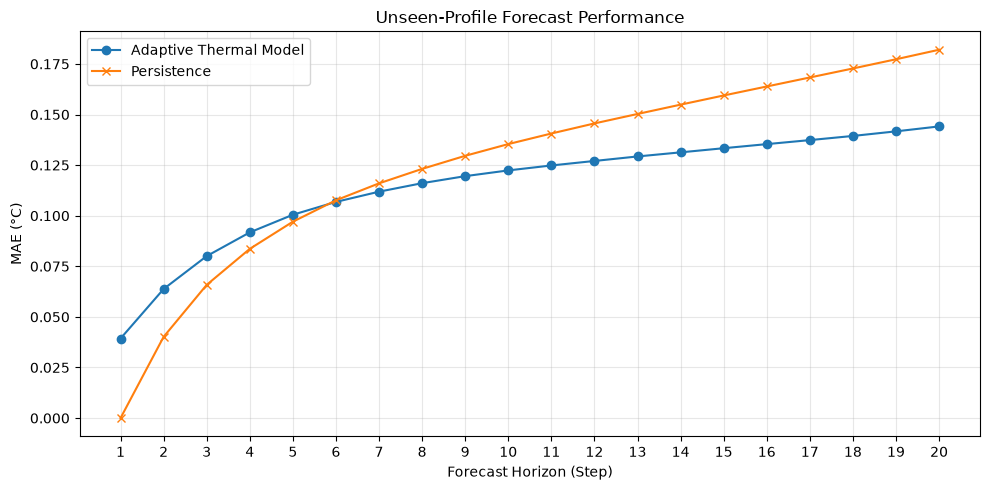

In [230]:

# UNSEEN PROFILE ERROR


plt.figure(
    figsize=(10, 5)
)

plt.plot(
    range(1, HORIZON + 1),
    test_horizon_mae,
    marker="o",
    label="Adaptive Thermal Model"
)

# ------------------------------------------
# Persistence horizon error
# ------------------------------------------

persistence_horizon_mae = []

for k in range(HORIZON):

    mae = mean_absolute_error(
        test_actual[:, k],
        persistence_predictions[:, k]
    )

    persistence_horizon_mae.append(
        mae
    )


plt.plot(
    range(1, HORIZON + 1),
    persistence_horizon_mae,
    marker="x",
    label="Persistence"
)

plt.xlabel(
    "Forecast Horizon (Step)"
)

plt.ylabel(
    "MAE (Â°C)"
)

plt.title(
    "Unseen-Profile Forecast Performance"
)

plt.xticks(
    range(1, HORIZON + 1)
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()

In [232]:

# SAVE RQ3 RESULTS


rq3_results = {

    "test_profiles":
        test_profiles.tolist(),

    "num_test_profiles":
        len(test_profiles),

    "test_sequences":
        len(adaptive_test_dataset),

    "adaptive_mae":
        float(test_mae),

    "adaptive_rmse":
        float(test_rmse),

    "adaptive_r2":
        float(test_r2),

    "persistence_mae":
        float(persistence_mae),

    "persistence_rmse":
        float(persistence_rmse),

    "persistence_r2":
        float(persistence_r2),

    "mae_improvement":
        float(mae_improvement),

    "relative_mae_improvement":
        float(relative_mae_improvement),

    "rmse_improvement":
        float(rmse_improvement),

    "relative_rmse_improvement":
        float(relative_rmse_improvement),

    "horizon_mae":
        test_horizon_mae.tolist()
}


rq3_path = (
    MODEL_DIR /
    "rq3_unseen_profile_results.pkl"
)

with open(
    rq3_path,
    "wb"
) as f:

    pickle.dump(
        rq3_results,
        f
    )


print(
    "RQ3 results saved:"
)

print(
    rq3_path
)

RQ3 results saved:
models\rq3_unseen_profile_results.pkl


In [234]:

# PER-PROFILE RQ3 ANALYSIS


adaptive_oc_model.eval()

profile_results = []

with torch.no_grad():
    TEST_PROFILES = np.asarray(test_profiles)
    for profile_id in TEST_PROFILES:

        profile_dataset = FastOperatingConditionDataset(
            scaled_df=test_scaled[
                test_scaled["profile_id"] == profile_id
            ].reset_index(drop=True),

            raw_df=test_df[
                test_df["profile_id"] == profile_id
            ].reset_index(drop=True),

            features=FEATURES,

            operating_features=OPERATING_FEATURES,

            seq_len=SEQ_LEN,

            horizon=HORIZON
        )

        profile_loader = DataLoader(
            profile_dataset,
            batch_size=512,
            shuffle=False,
            num_workers=0
        )

        profile_predictions = []
        profile_actual = []

        for batch in profile_loader:

            X_batch = batch[0].to(DEVICE)

            T_current = batch[1].to(DEVICE)

            T_future = batch[2].to(DEVICE)

            T_ambient = batch[3].to(DEVICE)

            operating_state = batch[4].to(DEVICE)

            (
                heat_signal,
                alpha,
                beta,
                gamma
            ) = adaptive_oc_model(
                X_batch,
                operating_state
            )

            predictions = adaptive_thermal_rollout(
                T_current,
                T_ambient,
                heat_signal,
                alpha,
                beta,
                gamma,
                HORIZON
            )

            profile_predictions.append(
                predictions.cpu().numpy()
            )

            profile_actual.append(
                T_future.cpu().numpy()
            )

        profile_predictions = np.concatenate(
            profile_predictions,
            axis=0
        )

        profile_actual = np.concatenate(
            profile_actual,
            axis=0
        )

        mae = mean_absolute_error(
            profile_actual.flatten(),
            profile_predictions.flatten()
        )

        rmse = np.sqrt(
            mean_squared_error(
                profile_actual.flatten(),
                profile_predictions.flatten()
            )
        )

        r2 = r2_score(
            profile_actual.flatten(),
            profile_predictions.flatten()
        )

        profile_results.append({

            "profile_id":
                int(profile_id),

            "samples":
                len(profile_dataset),

            "MAE_C":
                mae,

            "RMSE_C":
                rmse,

            "R2":
                r2
        })


profile_results_df = pd.DataFrame(
    profile_results
)

display(
    profile_results_df
)

Dataset created:
Sequences: 18610
Dataset created:
Sequences: 10669
Dataset created:
Sequences: 13325
Dataset created:
Sequences: 15817
Dataset created:
Sequences: 16995
Dataset created:
Sequences: 15440
Dataset created:
Sequences: 19101
Dataset created:
Sequences: 17174
Dataset created:
Sequences: 2029
Dataset created:
Sequences: 36329
Dataset created:
Sequences: 19210


,profile_id,samples,MAE_C,RMSE_C,R2
0,8,18610,0.037170,0.051657,0.999905
1,49,10669,0.205719,0.339631,0.997788
2,75,13325,0.136668,0.232341,0.999755
3,17,15817,0.070623,0.103571,0.999844
4,45,16995,0.044513,0.073381,0.999973
5,31,15440,0.068747,0.095770,0.999943
6,3,19101,0.027927,0.036629,0.999680
7,21,17174,0.467007,0.636587,0.998725
8,47,2029,0.185081,0.287332,0.971849
9,66,36329,0.113812,0.213356,0.999685


In [235]:

# PROFILE DIFFICULTY


print(
    "Worst profiles by MAE:"
)

display(
    profile_results_df
    .sort_values(
        "MAE_C",
        ascending=False
    )
)

print(
    "\nBest profiles by MAE:"
)

display(
    profile_results_df
    .sort_values(
        "MAE_C",
        ascending=True
    )
)

Worst profiles by MAE:


,profile_id,samples,MAE_C,RMSE_C,R2
7,21,17174,0.467007,0.636587,0.998725
1,49,10669,0.205719,0.339631,0.997788
8,47,2029,0.185081,0.287332,0.971849
2,75,13325,0.136668,0.232341,0.999755
9,66,36329,0.113812,0.213356,0.999685
3,17,15817,0.070623,0.103571,0.999844
5,31,15440,0.068747,0.095770,0.999943
4,45,16995,0.044513,0.073381,0.999973
0,8,18610,0.037170,0.051657,0.999905
6,3,19101,0.027927,0.036629,0.999680



Best profiles by MAE:


,profile_id,samples,MAE_C,RMSE_C,R2
10,2,19210,0.025716,0.036255,0.999977
6,3,19101,0.027927,0.036629,0.999680
0,8,18610,0.037170,0.051657,0.999905
4,45,16995,0.044513,0.073381,0.999973
5,31,15440,0.068747,0.095770,0.999943
3,17,15817,0.070623,0.103571,0.999844
9,66,36329,0.113812,0.213356,0.999685
2,75,13325,0.136668,0.232341,0.999755
8,47,2029,0.185081,0.287332,0.971849
1,49,10669,0.205719,0.339631,0.997788


In [236]:

# PROFILE THERMAL RANGE


profile_temperature_stats = (
    test_df
    .groupby("profile_id")["pm"]
    .agg(
        [
            "min",
            "max",
            "mean",
            "std"
        ]
    )
    .reset_index()
)

profile_temperature_stats[
    "temperature_range"
] = (
    profile_temperature_stats["max"]
    -
    profile_temperature_stats["min"]
)

profile_analysis = profile_results_df.merge(
    profile_temperature_stats,
    on="profile_id",
    how="left"
)

display(
    profile_analysis
)

,profile_id,samples,MAE_C,RMSE_C,R2,min,max,mean,std,temperature_range
0,8,18610,0.037170,0.051657,0.999905,24.012280,44.285309,36.944412,5.400953,20.273029
1,49,10669,0.205719,0.339631,0.997788,39.746620,81.919904,70.264564,7.902964,42.173283
2,75,13325,0.136668,0.232341,0.999755,23.358979,93.673207,68.718030,15.432531,70.314228
3,17,15817,0.070623,0.103571,0.999844,24.264736,69.588531,58.998289,8.807895,45.323795
4,45,16995,0.044513,0.073381,0.999973,26.294881,89.653037,64.009901,14.410033,63.358156
5,31,15440,0.068747,0.095770,0.999943,24.033005,102.098228,75.185486,13.497767,78.065224
6,3,19101,0.027927,0.036629,0.999680,22.751144,29.011612,26.285130,2.045192,6.260468
7,21,17174,0.467007,0.636587,0.998725,20.856956,91.506210,60.570799,18.046356,70.649254
8,47,2029,0.185081,0.287332,0.971849,72.247170,79.318106,75.029316,1.727365,7.070935
9,66,36329,0.113812,0.213356,0.999685,49.619607,94.201966,67.201225,12.015169,44.582359


In [237]:

# OPERATING REGIME SUMMARY


profile_operating_stats = (
    test_df
    .groupby("profile_id")[
        [
            "motor_speed",
            "torque",
            "I_mag",
            "P_cu",
            "ambient",
            "coolant"
        ]
    ]
    .mean()
    .reset_index()
)

profile_analysis = profile_analysis.merge(
    profile_operating_stats,
    on="profile_id",
    how="left"
)

display(
    profile_analysis.sort_values(
        "MAE_C",
        ascending=False
    )
)

,profile_id,samples,MAE_C,RMSE_C,R2,min,max,mean,std,temperature_range,motor_speed,torque,I_mag,P_cu,ambient,coolant
7,21,17174,0.467007,0.636587,0.998725,20.856956,91.506210,60.570799,18.046356,70.649254,4499.958024,30.424386,132.052076,1055.849545,21.625920,18.928059
1,49,10669,0.205719,0.339631,0.997788,39.746620,81.919904,70.264564,7.902964,42.173283,2722.786174,3.809036,161.428465,1528.073048,25.832651,49.958008
8,47,2029,0.185081,0.287332,0.971849,72.247170,79.318106,75.029316,1.727365,7.070935,2615.754323,-23.670025,129.475020,990.603138,24.268940,49.765243
2,75,13325,0.136668,0.232341,0.999755,23.358979,93.673207,68.718030,15.432531,70.314228,2129.962043,-13.323158,86.860453,701.993975,24.659787,58.904844
9,66,36329,0.113812,0.213356,0.999685,49.619607,94.201966,67.201225,12.015169,44.582359,1875.274394,-0.203874,69.767534,536.342526,26.024873,56.060076
3,17,15817,0.070623,0.103571,0.999844,24.264736,69.588531,58.998289,8.807895,45.323795,4989.845399,25.669563,124.443713,808.690942,23.954378,18.925401
5,31,15440,0.068747,0.095770,0.999943,24.033005,102.098228,75.185486,13.497767,78.065224,5054.128552,51.193955,160.912646,1368.555359,22.681223,18.900381
4,45,16995,0.044513,0.073381,0.999973,26.294881,89.653037,64.009901,14.410033,63.358156,1675.692989,40.917103,66.082625,425.253019,24.585161,62.817435
0,8,18610,0.037170,0.051657,0.999905,24.012280,44.285309,36.944412,5.400953,20.273029,1498.038632,53.486542,73.560128,505.656095,22.873297,18.593162
6,3,19101,0.027927,0.036629,0.999680,22.751144,29.011612,26.285130,2.045192,6.260468,99.996061,51.692367,70.695565,485.342067,21.981501,18.761891


In [238]:

# SAVE PROFILE ANALYSIS


profile_results_path = (
    MODEL_DIR /
    "rq3_profile_analysis.csv"
)

profile_analysis.to_csv(
    profile_results_path,
    index=False
)

print(
    "Saved:"
)

print(
    profile_results_path
)

Saved:
models\rq3_profile_analysis.csv


energy features

In [239]:

# ENERGY FEATURES


ENERGY_FEATURES = [
    "P_cu",
    "P_elec",
    "P_mech",
    "I_mag",
    "motor_speed",
    "torque"
]

print(
    "Energy features:"
)

print(
    ENERGY_FEATURES
)

print(
    "\nNumber of energy features:",
    len(ENERGY_FEATURES)
)

missing_energy_features = [
    f
    for f in ENERGY_FEATURES
    if f not in train_df.columns
]

if missing_energy_features:

    raise ValueError(
        f"Missing features: "
        f"{missing_energy_features}"
    )

print(
    "\nAll energy features available."
)

Energy features:
['P_cu', 'P_elec', 'P_mech', 'I_mag', 'motor_speed', 'torque']

Number of energy features: 6

All energy features available.


In [240]:

# ENERGY DATASET


class FastEnergyDataset(Dataset):

    def __init__(
        self,
        scaled_df,
        raw_df,
        features,
        energy_features,
        seq_len,
        horizon
    ):

        self.seq_len = seq_len
        self.horizon = horizon

        self.X_data = (
            scaled_df[features]
            .values
            .astype(np.float32)
        )

        self.energy_data = (
            scaled_df[energy_features]
            .values
            .astype(np.float32)
        )

        self.T_data = (
            raw_df["pm"]
            .values
            .astype(np.float32)
        )

        self.ambient_data = (
            raw_df["ambient"]
            .values
            .astype(np.float32)
        )

        self.profile_ids = (
            raw_df["profile_id"]
            .values
        )

        self.indices = []

        unique_profiles = np.unique(
            self.profile_ids
        )

        for profile_id in unique_profiles:

            positions = np.where(
                self.profile_ids == profile_id
            )[0]

            if len(positions) < (
                seq_len + horizon
            ):
                continue

            start_pos = positions[0]

            end_pos = positions[-1]

            last_start = (
                end_pos
                -
                seq_len
                -
                horizon
                +
                1
            )

            self.indices.extend(
                range(
                    start_pos,
                    last_start + 1
                )
            )

        self.indices = np.asarray(
            self.indices,
            dtype=np.int64
        )

        print(
            "Created energy dataset:"
        )

        print(
            "Sequences:",
            len(self.indices)
        )


    def __len__(self):

        return len(self.indices)


    def __getitem__(self, idx):

        start = self.indices[idx]

        seq_end = (
            start +
            self.seq_len
        )

        future_end = (
            seq_end +
            self.horizon
        )

        X = self.X_data[
            start:seq_end
        ]

        energy_state = self.energy_data[
            seq_end - 1
        ]

        T_current = self.T_data[
            seq_end - 1
        ]

        T_future = self.T_data[
            seq_end:future_end
        ]

        T_ambient = self.ambient_data[
            seq_end:future_end
        ]

        return (

            torch.from_numpy(X),

            torch.from_numpy(
                energy_state
            ),

            torch.tensor(
                T_current,
                dtype=torch.float32
            ),

            torch.from_numpy(
                T_future
            ),

            torch.from_numpy(
                T_ambient
            )
        )

In [241]:

# RQ4 DATASETS


energy_train_dataset = FastEnergyDataset(
    scaled_df=train_scaled,
    raw_df=train_df,
    features=FEATURES,
    energy_features=ENERGY_FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

energy_val_dataset = FastEnergyDataset(
    scaled_df=val_scaled,
    raw_df=val_df,
    features=FEATURES,
    energy_features=ENERGY_FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

energy_test_dataset = FastEnergyDataset(
    scaled_df=test_scaled,
    raw_df=test_df,
    features=FEATURES,
    energy_features=ENERGY_FEATURES,
    seq_len=SEQ_LEN,
    horizon=HORIZON
)

print(
    "\nTrain:",
    len(energy_train_dataset)
)

print(
    "Validation:",
    len(energy_val_dataset)
)

print(
    "Test:",
    len(energy_test_dataset)
)

Created energy dataset:
Sequences: 925544
Created energy dataset:
Sequences: 210430
Created energy dataset:
Sequences: 184699

Train: 925544
Validation: 210430
Test: 184699


In [242]:

# RQ4 DATALOADERS


energy_train_loader = DataLoader(
    energy_train_dataset,
    batch_size=512,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

energy_val_loader = DataLoader(
    energy_val_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

energy_test_loader = DataLoader(
    energy_test_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(
    "RQ4 DataLoaders ready."
)

RQ4 DataLoaders ready.


In [243]:

# VERIFY RQ4 BATCH


batch = next(
    iter(energy_train_loader)
)

X_batch = batch[0]

energy_state = batch[1]

T_current = batch[2]

T_future = batch[3]

T_ambient = batch[4]

print(
    "X:",
    X_batch.shape
)

print(
    "Energy state:",
    energy_state.shape
)

print(
    "T_current:",
    T_current.shape
)

print(
    "T_future:",
    T_future.shape
)

print(
    "T_ambient:",
    T_ambient.shape
)

X: torch.Size([512, 128, 13])
Energy state: torch.Size([512, 6])
T_current: torch.Size([512])
T_future: torch.Size([512, 20])
T_ambient: torch.Size([512, 20])


In [244]:

# ENERGY-CONSTRAINED RESIDUAL MODEL


class EnergyConstrainedResidualModel(nn.Module):

    def __init__(
        self,
        input_dim=13,
        energy_dim=6,
        hidden_dim=64,
        horizon=20
    ):

        super().__init__()

        self.horizon = horizon

        # ----------------------------------
        # Temporal encoder
        # ----------------------------------

        self.temporal_encoder = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # ----------------------------------
        # Energy encoder
        # ----------------------------------

        self.energy_encoder = nn.Sequential(

            nn.Linear(
                energy_dim,
                32
            ),

            nn.ReLU(),

            nn.Linear(
                32,
                32
            ),

            nn.ReLU()
        )

        # ----------------------------------
        # Combined representation
        # ----------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(
                hidden_dim + 32,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.ReLU()
        )

        # ----------------------------------
        # Thermal parameter head
        # ----------------------------------

        self.parameter_head = nn.Linear(
            hidden_dim,
            3
        )

        # ----------------------------------
        # Heat pathway
        # ----------------------------------

        self.heat_head = nn.Linear(
            hidden_dim,
            1
        )

        # ----------------------------------
        # Residual pathway
        # ----------------------------------

        self.residual_head = nn.Sequential(

            nn.Linear(
                hidden_dim,
                32
            ),

            nn.ReLU(),

            nn.Linear(
                32,
                horizon
            )
        )


    def forward(
        self,
        X,
        energy_state
    ):

        # ----------------------------------
        # Temporal encoding
        # ----------------------------------

        _, hidden = self.temporal_encoder(X)

        temporal_state = hidden[-1]

        # ----------------------------------
        # Energy encoding
        # ----------------------------------

        energy_state_encoded = (
            self.energy_encoder(
                energy_state
            )
        )

        # ----------------------------------
        # Fusion
        # ----------------------------------

        combined = torch.cat(
            [
                temporal_state,
                energy_state_encoded
            ],
            dim=1
        )

        latent = self.fusion(
            combined
        )

        # ----------------------------------
        # Thermal parameters
        # ----------------------------------

        raw_parameters = (
            self.parameter_head(
                latent
            )
        )

        alpha = torch.sigmoid(
            raw_parameters[:, 0]
        )

        beta = torch.sigmoid(
            raw_parameters[:, 1]
        )

        gamma = torch.sigmoid(
            raw_parameters[:, 2]
        )

        # ----------------------------------
        # Heat signal
        # ----------------------------------

        heat_signal = self.heat_head(
            latent
        ).squeeze(-1)

        # ----------------------------------
        # BOUNDED RESIDUAL
        # ----------------------------------

        residual = self.residual_head(
            latent
        )

        # Maximum residual correction.
        # This prevents explosive temperatures.

        MAX_RESIDUAL = 0.25

        residual = (
            MAX_RESIDUAL *
            torch.tanh(residual)
        )

        return (
            heat_signal,
            alpha,
            beta,
            gamma,
            residual
        )

In [245]:

# MODEL


rq4_model = EnergyConstrainedResidualModel(
    input_dim=len(FEATURES),
    energy_dim=len(ENERGY_FEATURES),
    hidden_dim=64,
    horizon=HORIZON
).to(DEVICE)

print(
    rq4_model
)

EnergyConstrainedResidualModel(
  (temporal_encoder): GRU(13, 64, batch_first=True)
  (energy_encoder): Sequential(
    (0): Linear(in_features=6, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
  )
  (fusion): Sequential(
    (0): Linear(in_features=96, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
  )
  (parameter_head): Linear(in_features=64, out_features=3, bias=True)
  (heat_head): Linear(in_features=64, out_features=1, bias=True)
  (residual_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=20, bias=True)
  )
)


In [246]:

# FORWARD PASS TEST


rq4_model.eval()

with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma,
        residual
    ) = rq4_model(
        X_batch.to(DEVICE),
        energy_state.to(DEVICE)
    )


print(
    "Heat signal:",
    heat_signal.shape
)

print(
    "Alpha:",
    alpha.shape
)

print(
    "Beta:",
    beta.shape
)

print(
    "Gamma:",
    gamma.shape
)

print(
    "Residual:",
    residual.shape
)

print()
print(
    "Alpha range:",
    alpha.min().item(),
    "to",
    alpha.max().item()
)

print(
    "Beta range:",
    beta.min().item(),
    "to",
    beta.max().item()
)

print(
    "Gamma range:",
    gamma.min().item(),
    "to",
    gamma.max().item()
)

print(
    "Residual range:",
    residual.min().item(),
    "to",
    residual.max().item()
)

Heat signal: torch.Size([512])
Alpha: torch.Size([512])
Beta: torch.Size([512])
Gamma: torch.Size([512])
Residual: torch.Size([512, 20])

Alpha range: 0.5169204473495483 to 0.5316715240478516
Beta range: 0.4721534252166748 to 0.4898483455181122
Gamma range: 0.46485352516174316 to 0.49225667119026184
Residual range: -0.04691227152943611 to 0.04411766305565834


In [247]:

# ENERGY-CONSTRAINED THERMAL ROLLOUT


def energy_constrained_rollout(
    T_current,
    T_ambient,
    heat_signal,
    alpha,
    beta,
    gamma,
    residual
):

    predictions = []

    T = T_current

    for k in range(
        T_ambient.shape[1]
    ):

        ambient_k = T_ambient[:, k]

        # ----------------------------------
        # Physics-based thermal evolution
        # ----------------------------------

        cooling = (
            alpha *
            (ambient_k - T)
        )

        heating = (
            beta *
            heat_signal
        )

        physics_delta = (
            cooling +
            heating
        )

        # ----------------------------------
        # Learned bounded correction
        # ----------------------------------

        residual_delta = (
            gamma *
            residual[:, k]
        )

        # ----------------------------------
        # Next temperature
        # ----------------------------------

        T_next = (
            T
            +
            physics_delta
            +
            residual_delta
        )

        # ----------------------------------
        # Physical sanity constraint
        # ----------------------------------

        MAX_STEP_CHANGE = 0.5

        delta = (
            T_next - T
        )

        delta = torch.clamp(
            delta,
            -MAX_STEP_CHANGE,
            MAX_STEP_CHANGE
        )

        T = T + delta

        predictions.append(
            T
        )

    return torch.stack(
        predictions,
        dim=1
    )

In [248]:

# PREDICTION SANITY TEST


rq4_model.eval()

with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma,
        residual
    ) = rq4_model(
        X_batch.to(DEVICE),
        energy_state.to(DEVICE)
    )

    rq4_prediction = (
        energy_constrained_rollout(
            T_current.to(DEVICE),
            T_ambient.to(DEVICE),
            heat_signal,
            alpha,
            beta,
            gamma,
            residual
        )
    )


rq4_prediction = (
    rq4_prediction.cpu()
    .numpy()
)


print("=" * 60)

print(
    "RQ4 INITIAL PREDICTION TEST"
)

print("=" * 60)

print(
    "Prediction shape:",
    rq4_prediction.shape
)

print(
    "Prediction range:",
    rq4_prediction.min(),
    "to",
    rq4_prediction.max()
)

print(
    "Actual range:",
    T_future.numpy().min(),
    "to",
    T_future.numpy().max()
)

print("=" * 60)

RQ4 INITIAL PREDICTION TEST
Prediction shape: (512, 20)
Prediction range: 19.469889 to 112.423546
Actual range: 23.70282 to 113.185684


In [249]:

# PHYSICAL TRAJECTORY CHECK


temperature_changes = np.diff(
    rq4_prediction,
    axis=1
)

print(
    "Maximum absolute predicted "
    "temperature change:"
)

print(
    np.abs(
        temperature_changes
    ).max(),
    "Â°C/step"
)

print(
    "\nMean absolute predicted "
    "temperature change:"
)

print(
    np.abs(
        temperature_changes
    ).mean(),
    "Â°C/step"
)

Maximum absolute predicted temperature change:
0.5 Â°C/step

Mean absolute predicted temperature change:
0.48430055 Â°C/step


In [250]:

# ENERGY SANITY CHECK


print("=" * 60)

print(
    "ENERGY STATE STATISTICS"
)

print("=" * 60)

for i, feature in enumerate(
    ENERGY_FEATURES
):

    values = energy_state[:, i].numpy()

    print(
        f"{feature:15s} | "
        f"min={values.min():.4f} | "
        f"max={values.max():.4f} | "
        f"mean={values.mean():.4f}"
    )

print("=" * 60)

ENERGY STATE STATISTICS
P_cu            | min=-0.8743 | max=4.4896 | mean=0.0078
P_elec          | min=-2.9171 | max=2.0644 | mean=-0.0007
P_mech          | min=-3.2371 | max=1.9522 | mean=-0.0032
I_mag           | min=-1.2467 | max=2.7335 | mean=0.0298
motor_speed     | min=-1.1883 | max=2.0921 | mean=0.0482
torque          | min=-3.3338 | max=2.8958 | mean=0.0107


In [251]:

# CORRECTED
# ENERGY-CONSTRAINED THERMAL ROLLOUT


def energy_constrained_rollout(
    T_current,
    T_ambient,
    heat_signal,
    alpha,
    beta,
    gamma,
    residual
):

    predictions = []

    T = T_current

    for k in range(
        T_ambient.shape[1]
    ):

        ambient_k = T_ambient[:, k]

        # ----------------------------------
        # Thermal cooling term
        # ----------------------------------

        cooling = (
            alpha *
            (ambient_k - T)
        )

        # ----------------------------------
        # Physics heat contribution
        # ----------------------------------

        heating = (
            beta *
            heat_signal
        )

        # ----------------------------------
        # Bounded learned residual
        # ----------------------------------

        residual_delta = (
            gamma *
            residual[:, k]
        )

        # ----------------------------------
        # Raw thermal evolution
        # ----------------------------------

        delta_T = (
            cooling
            +
            heating
            +
            residual_delta
        )

        # ----------------------------------
        # SOFT physical bounding
        #
        # Prevent extreme numerical jumps
        # without forcing the trajectory to
        # the boundary.
        # ----------------------------------

        delta_T = (
            0.15 *
            torch.tanh(
                delta_T / 0.15
            )
        )

        T = T + delta_T

        predictions.append(T)

    return torch.stack(
        predictions,
        dim=1
    )

In [252]:

# CORRECTED SANITY TEST


rq4_model.eval()

with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma,
        residual
    ) = rq4_model(
        X_batch.to(DEVICE),
        energy_state.to(DEVICE)
    )

    rq4_prediction = (
        energy_constrained_rollout(
            T_current.to(DEVICE),
            T_ambient.to(DEVICE),
            heat_signal,
            alpha,
            beta,
            gamma,
            residual
        )
    )

rq4_prediction = (
    rq4_prediction
    .cpu()
    .numpy()
)

print("=" * 60)

print(
    "RQ4 CORRECTED PREDICTION TEST"
)

print("=" * 60)

print(
    "Prediction shape:",
    rq4_prediction.shape
)

print(
    "Prediction range:",
    rq4_prediction.min(),
    "to",
    rq4_prediction.max()
)

print(
    "Actual range:",
    T_future.numpy().min(),
    "to",
    T_future.numpy().max()
)

print("=" * 60)

RQ4 CORRECTED PREDICTION TEST
Prediction shape: (512, 20)
Prediction range: 22.070168 to 112.773544
Actual range: 23.70282 to 113.185684


In [253]:

# CORRECTED TRAJECTORY CHECK


temperature_changes = np.diff(
    rq4_prediction,
    axis=1
)

abs_changes = np.abs(
    temperature_changes
)

print("=" * 60)

print(
    "THERMAL TRAJECTORY CHECK"
)

print("=" * 60)

print(
    "Maximum |Î”T|:",
    abs_changes.max(),
    "Â°C/step"
)

print(
    "Mean |Î”T|:",
    abs_changes.mean(),
    "Â°C/step"
)

print(
    "Median |Î”T|:",
    np.median(abs_changes),
    "Â°C/step"
)

print(
    "95th percentile |Î”T|:",
    np.percentile(
        abs_changes,
        95
    ),
    "Â°C/step"
)

print(
    "99th percentile |Î”T|:",
    np.percentile(
        abs_changes,
        99
    ),
    "Â°C/step"
)

print("=" * 60)

THERMAL TRAJECTORY CHECK
Maximum |Î”T|: 0.15000153 Â°C/step
Mean |Î”T|: 0.14879146 Â°C/step
Median |Î”T|: 0.15000153 Â°C/step
95th percentile |Î”T|: 0.15000153 Â°C/step
99th percentile |Î”T|: 0.15000153 Â°C/step


In [254]:

# CORRECTED TRAJECTORY CHECK


temperature_changes = np.diff(
    rq4_prediction,
    axis=1
)

abs_changes = np.abs(
    temperature_changes
)

print("=" * 60)

print("THERMAL TRAJECTORY CHECK")

print("=" * 60)

print(
    "Maximum |Î”T|:",
    abs_changes.max(),
    "Â°C/step"
)

print(
    "Mean |Î”T|:",
    abs_changes.mean(),
    "Â°C/step"
)

print(
    "Median |Î”T|:",
    np.median(abs_changes),
    "Â°C/step"
)

print(
    "95th percentile |Î”T|:",
    np.percentile(
        abs_changes,
        95
    ),
    "Â°C/step"
)

print(
    "99th percentile |Î”T|:",
    np.percentile(
        abs_changes,
        99
    ),
    "Â°C/step"
)

print("=" * 60)

THERMAL TRAJECTORY CHECK
Maximum |Î”T|: 0.15000153 Â°C/step
Mean |Î”T|: 0.14879146 Â°C/step
Median |Î”T|: 0.15000153 Â°C/step
95th percentile |Î”T|: 0.15000153 Â°C/step
99th percentile |Î”T|: 0.15000153 Â°C/step


In [255]:
# ==========================================
# BLOCK 19.13
# STABLE ENERGY-CONSTRAINED ROLLOUT
# ==========================================

def energy_constrained_rollout(
    T_current,
    T_ambient,
    alpha,
    beta,
    gamma,
    residual,
    energy_signal
):

    predictions = []

    T = T_current

    for k in range(
        T_ambient.shape[1]
    ):

        ambient_k = T_ambient[:, k]

        # ----------------------------------
        # Thermal relaxation
        # ----------------------------------

        thermal_relaxation = (
            alpha *
            (ambient_k - T)
        )

        # ----------------------------------
        # Energy forcing
        #
        # Small coefficient because energy
        # variables are normalized.
        # ----------------------------------

        energy_forcing = (
            beta *
            energy_signal
        )

        # ----------------------------------
        # Bounded residual correction
        # ----------------------------------

        residual_correction = (
            gamma *
            residual[:, k]
        )

        # ----------------------------------
        # Total temperature increment
        # ----------------------------------

        delta_T = (
            thermal_relaxation
            +
            0.01 * energy_forcing
            +
            residual_correction
        )

        # ----------------------------------
        # NO ARTIFICIAL TEMPERATURE CLAMP
        # ----------------------------------

        T = T + delta_T

        predictions.append(T)

    return torch.stack(
        predictions,
        dim=1
    )

In [256]:

# ENERGY SIGNAL


P_cu_normalized = (
    energy_state[:, 0]
)

print(
    "Normalized P_cu range:",
    P_cu_normalized.min().item(),
    "to",
    P_cu_normalized.max().item()
)

print(
    "Normalized P_cu mean:",
    P_cu_normalized.mean().item()
)

print(
    "Normalized P_cu std:",
    P_cu_normalized.std().item()
)

Normalized P_cu range: -0.8742907643318176 to 4.489591121673584
Normalized P_cu mean: 0.00783848762512207
Normalized P_cu std: 0.9618079662322998


In [257]:
# ==========================================
# BLOCK 19.15 â€” NEW ROLLOUT TEST
# ==========================================

rq4_model.eval()

with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma,
        residual
    ) = rq4_model(
        X_batch.to(DEVICE),
        energy_state.to(DEVICE)
    )

    energy_signal = (
        energy_state[:, 0]
        .to(DEVICE)
    )

    rq4_prediction = (
        energy_constrained_rollout(
            T_current.to(DEVICE),
            T_ambient.to(DEVICE),
            alpha,
            beta,
            gamma,
            residual,
            energy_signal
        )
    )


rq4_prediction = (
    rq4_prediction
    .cpu()
    .numpy()
)


print("=" * 60)

print(
    "NEW RQ4 PREDICTION TEST"
)

print("=" * 60)

print(
    "Prediction range:",
    rq4_prediction.min(),
    "to",
    rq4_prediction.max()
)

print(
    "Actual range:",
    T_future.numpy().min(),
    "to",
    T_future.numpy().max()
)

print("=" * 60)

NEW RQ4 PREDICTION TEST
Prediction range: 18.6448 to 66.29826
Actual range: 23.70282 to 113.185684


In [258]:

# TRAJECTORY CHECK


temperature_changes = np.diff(
    rq4_prediction,
    axis=1
)

abs_changes = np.abs(
    temperature_changes
)

print("=" * 60)

print(
    "NEW THERMAL TRAJECTORY CHECK"
)

print("=" * 60)

print(
    "Maximum |Î”T|:",
    abs_changes.max(),
    "Â°C/step"
)

print(
    "Mean |Î”T|:",
    abs_changes.mean(),
    "Â°C/step"
)

print(
    "Median |Î”T|:",
    np.median(abs_changes),
    "Â°C/step"
)

print(
    "95th percentile |Î”T|:",
    np.percentile(
        abs_changes,
        95
    ),
    "Â°C/step"
)

print(
    "99th percentile |Î”T|:",
    np.percentile(
        abs_changes,
        99
    ),
    "Â°C/step"
)

print("=" * 60)

NEW THERMAL TRAJECTORY CHECK
Maximum |Î”T|: 22.275692 Â°C/step
Mean |Î”T|: 0.8875687 Â°C/step
Median |Î”T|: 0.03628826 Â°C/step
95th percentile |Î”T|: 5.6742964 Â°C/step
99th percentile |Î”T|: 12.742658 Â°C/step


In [259]:
# ==========================================
# BLOCK 19.17
# ENERGY-CONSTRAINED RESIDUAL NETWORK
# ==========================================

class EnergyResidualNetwork(nn.Module):

    def __init__(
        self,
        input_dim=13,
        energy_dim=6,
        hidden_dim=64,
        horizon=20
    ):

        super().__init__()

        self.horizon = horizon

        # ----------------------------------
        # Temporal encoder
        # ----------------------------------

        self.temporal_encoder = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # ----------------------------------
        # Energy encoder
        # ----------------------------------

        self.energy_encoder = nn.Sequential(

            nn.Linear(
                energy_dim,
                32
            ),

            nn.ReLU(),

            nn.Linear(
                32,
                32
            ),

            nn.ReLU()
        )

        # ----------------------------------
        # Fusion
        # ----------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(
                hidden_dim + 32,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.ReLU()
        )

        # ----------------------------------
        # Residual prediction
        # ----------------------------------

        self.residual_head = nn.Sequential(

            nn.Linear(
                hidden_dim,
                32
            ),

            nn.ReLU(),

            nn.Linear(
                32,
                horizon
            )
        )


    def forward(
        self,
        X,
        energy_state
    ):

        # Temporal representation

        _, hidden = (
            self.temporal_encoder(X)
        )

        temporal_state = hidden[-1]

        # Energy representation

        energy_state_encoded = (
            self.energy_encoder(
                energy_state
            )
        )

        # Combine both

        combined = torch.cat(
            [
                temporal_state,
                energy_state_encoded
            ],
            dim=1
        )

        latent = self.fusion(
            combined
        )

        # Raw residual

        residual = (
            self.residual_head(
                latent
            )
        )

        # IMPORTANT:
        # residual is deliberately small

        MAX_RESIDUAL = 0.10

        residual = (
            MAX_RESIDUAL *
            torch.tanh(residual)
        )

        return residual

In [260]:
# ==========================================
# BLOCK 19.18
# INSTANTIATE ENERGY RESIDUAL MODEL
# ==========================================

energy_residual_model = (
    EnergyResidualNetwork(
        input_dim=len(FEATURES),
        energy_dim=len(ENERGY_FEATURES),
        hidden_dim=64,
        horizon=HORIZON
    ).to(DEVICE)
)

print(
    energy_residual_model
)

EnergyResidualNetwork(
  (temporal_encoder): GRU(13, 64, batch_first=True)
  (energy_encoder): Sequential(
    (0): Linear(in_features=6, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
  )
  (fusion): Sequential(
    (0): Linear(in_features=96, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
  )
  (residual_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=20, bias=True)
  )
)


In [261]:
# ==========================================
# BLOCK 19.19
# RESIDUAL SANITY TEST
# ==========================================

energy_residual_model.eval()

with torch.no_grad():

    residual_test = (
        energy_residual_model(
            X_batch.to(DEVICE),
            energy_state.to(DEVICE)
        )
    )

print("=" * 60)

print(
    "ENERGY RESIDUAL TEST"
)

print("=" * 60)

print(
    "Residual shape:",
    residual_test.shape
)

print(
    "Residual range:",
    residual_test.min().item(),
    "to",
    residual_test.max().item()
)

print(
    "Mean absolute residual:",
    residual_test.abs().mean().item()
)

print(
    "Maximum absolute residual:",
    residual_test.abs().max().item()
)

print("=" * 60)

ENERGY RESIDUAL TEST
Residual shape: torch.Size([512, 20])
Residual range: -0.021072307601571083 to 0.021140580996870995
Mean absolute residual: 0.010159543715417385
Maximum absolute residual: 0.021140580996870995


In [262]:
# ==========================================
# BLOCK 19.20
# CHECK EXISTING ADAPTIVE MODEL
# ==========================================

print(
    "Adaptive model type:"
)

print(
    type(adaptive_model)
)

Adaptive model type:
<class '__main__.AdaptiveThermalStateSpace'>


In [264]:
# ==========================================
# FIND MODEL VARIABLES
# ==========================================

model_variables = [
    (name, obj)
    for name, obj in globals().items()
    if isinstance(obj, nn.Module)
]

for name, obj in model_variables:
    print(
        name,
        "->",
        type(obj).__name__
    )

model -> FixedThermalModel
adaptive_model -> AdaptiveThermalStateSpace
ms_model -> MultiStepThermalModel
stable_model -> StableThermalStateSpace
adaptive_oc_model -> OperatingConditionAdaptiveModel
rq4_model -> EnergyConstrainedResidualModel
energy_residual_model -> EnergyResidualNetwork


In [265]:
# ==========================================
# BLOCK 19.21
# FREEZE BEST ADAPTIVE MODEL
# ==========================================

adaptive_model.eval()

for param in adaptive_model.parameters():
    param.requires_grad = False

print("Adaptive model frozen.")

trainable_params = sum(
    p.numel()
    for p in adaptive_model.parameters()
    if p.requires_grad
)

print(
    "Trainable adaptive parameters:",
    trainable_params
)

Adaptive model frozen.
Trainable adaptive parameters: 0


In [266]:
# ==========================================
# BLOCK 19.22
# INSPECT ADAPTIVE MODEL OUTPUT
# ==========================================

adaptive_model.eval()

with torch.no_grad():

    adaptive_output = adaptive_model(
        X_batch.to(DEVICE)
    )

print(
    "Adaptive model output type:",
    type(adaptive_output)
)

if isinstance(
    adaptive_output,
    tuple
):

    print(
        "Number of outputs:",
        len(adaptive_output)
    )

    for i, output in enumerate(
        adaptive_output
    ):

        if torch.is_tensor(output):

            print(
                f"Output {i}:",
                output.shape
            )

        else:

            print(
                f"Output {i}:",
                type(output)
            )

else:

    print(
        "Output shape:",
        adaptive_output.shape
    )

Adaptive model output type: <class 'tuple'>
Number of outputs: 4
Output 0: torch.Size([512])
Output 1: torch.Size([])
Output 2: torch.Size([])
Output 3: torch.Size([])


In [267]:
# ==========================================
# BLOCK 19.23
# INSPECT ADAPTIVE MODEL
# ==========================================

print(
    adaptive_model
)

AdaptiveThermalStateSpace(
  (encoder): TemporalEncoder(
    (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.1)
  )
  (heat_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
    (3): Tanh()
  )
)


In [268]:
# ==========================================
# BLOCK 19.24
# IDENTIFY ADAPTIVE MODEL OUTPUT
# ==========================================

adaptive_model.eval()

with torch.no_grad():

    adaptive_out = adaptive_model(
        X_batch.to(DEVICE)
    )

print("=" * 60)
print("ADAPTIVE MODEL OUTPUT DIAGNOSTIC")
print("=" * 60)

for i, out in enumerate(adaptive_out):

    print(
        f"\nOutput {i}"
    )

    print(
        "Shape:",
        out.shape
    )

    if torch.is_tensor(out):

        print(
            "Min:",
            out.min().item()
        )

        print(
            "Max:",
            out.max().item()
        )

        print(
            "Mean:",
            out.mean().item()
        )

        print(
            "First 5:",
            out.flatten()[:5].cpu().numpy()
        )

print("=" * 60)

ADAPTIVE MODEL OUTPUT DIAGNOSTIC

Output 0
Shape: torch.Size([512])
Min: -0.6137237548828125
Max: 0.8705382943153381
Mean: 0.11559097468852997
First 5: [ 0.2875323   0.13123049 -0.20422906  0.0898621   0.04094725]

Output 1
Shape: torch.Size([])
Min: 0.11177423596382141
Max: 0.11177423596382141
Mean: 0.11177423596382141
First 5: [0.11177424]

Output 2
Shape: torch.Size([])
Min: 0.04162105545401573
Max: 0.04162105545401573
Mean: 0.04162105545401573
First 5: [0.04162106]

Output 3
Shape: torch.Size([])
Min: 0.46678754687309265
Max: 0.46678754687309265
Mean: 0.46678754687309265
First 5: [0.46678755]


In [269]:
# ==========================================
# BLOCK 19.25
# CHECK EXISTING ROLLOUT FUNCTIONS
# ==========================================

print(
    "adaptive_model:",
    type(adaptive_model).__name__
)

print(
    "\nAvailable rollout functions:"
)

for name, obj in globals().items():

    if callable(obj) and (
        "rollout" in name.lower()
        or "thermal" in name.lower()
    ):

        print(
            name
        )

adaptive_model: AdaptiveThermalStateSpace

Available rollout functions:
ThermalSequenceDataset
FixedThermalModel
rollout_model
AdaptiveThermalParameters
AdaptiveThermalModel
MultiStepThermalDataset
LazyMultiStepThermalDataset
MultiStepThermalModel
thermal_rollout
PhysicsInformedThermalModel
physics_thermal_rollout
StableThermalModel
stable_thermal_rollout
StableThermalStateSpace
stable_state_space_rollout
adaptive_thermal_rollout
AdaptiveThermalStateSpace
energy_constrained_rollout


In [270]:
# ==========================================
# BLOCK 19.26
# VERIFY EXISTING ADAPTIVE ROLLOUT
# ==========================================

adaptive_model.eval()

with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma
    ) = adaptive_model(
        X_batch.to(DEVICE)
    )

    base_prediction = adaptive_thermal_rollout(
        T_current.to(DEVICE),
        T_ambient.to(DEVICE),
        heat_signal,
        alpha,
        beta,
        gamma,
        HORIZON
    )

base_prediction_np = (
    base_prediction
    .cpu()
    .numpy()
)

print("=" * 60)
print("BASE ADAPTIVE MODEL")
print("=" * 60)

print(
    "Prediction shape:",
    base_prediction_np.shape
)

print(
    "Prediction range:",
    base_prediction_np.min(),
    "to",
    base_prediction_np.max()
)

print(
    "Actual range:",
    T_future.numpy().min(),
    "to",
    T_future.numpy().max()
)

print("=" * 60)

BASE ADAPTIVE MODEL
Prediction shape: (512, 20)
Prediction range: 23.771383 to 112.95269
Actual range: 23.70282 to 113.185684


In [271]:
# ==========================================
# BLOCK 19.27
# BASE + ENERGY RESIDUAL
# ==========================================

energy_residual_model.eval()

with torch.no_grad():

    residual = (
        energy_residual_model(
            X_batch.to(DEVICE),
            energy_state.to(DEVICE)
        )
    )

    final_prediction = (
        base_prediction
        +
        residual
    )

final_prediction_np = (
    final_prediction
    .cpu()
    .numpy()
)

print("=" * 60)
print("BASE + ENERGY RESIDUAL")
print("=" * 60)

print(
    "Base prediction range:",
    base_prediction_np.min(),
    "to",
    base_prediction_np.max()
)

print(
    "Residual range:",
    residual.min().item(),
    "to",
    residual.max().item()
)

print(
    "Final prediction range:",
    final_prediction_np.min(),
    "to",
    final_prediction_np.max()
)

print(
    "Actual range:",
    T_future.numpy().min(),
    "to",
    T_future.numpy().max()
)

print("=" * 60)

BASE + ENERGY RESIDUAL
Base prediction range: 23.771383 to 112.95269
Residual range: -0.021072307601571083 to 0.021140580996870995
Final prediction range: 23.753473 to 112.97041
Actual range: 23.70282 to 113.185684


In [272]:
# ==========================================
# BLOCK 19.28
# RESIDUAL MAGNITUDE CHECK
# ==========================================

residual_np = (
    residual
    .cpu()
    .numpy()
)

print("=" * 60)
print("ENERGY RESIDUAL MAGNITUDE")
print("=" * 60)

print(
    "Maximum absolute residual:",
    np.abs(residual_np).max(),
    "Â°C"
)

print(
    "Mean absolute residual:",
    np.abs(residual_np).mean(),
    "Â°C"
)

print(
    "Median absolute residual:",
    np.median(
        np.abs(residual_np)
    ),
    "Â°C"
)

print(
    "95th percentile:",
    np.percentile(
        np.abs(residual_np),
        95
    ),
    "Â°C"
)

print("=" * 60)

ENERGY RESIDUAL MAGNITUDE
Maximum absolute residual: 0.021140581 Â°C
Mean absolute residual: 0.010159543 Â°C
Median absolute residual: 0.009644942 Â°C
95th percentile: 0.019211737 Â°C


In [273]:
# ==========================================
# BLOCK 19.29
# ENERGY-CONSTRAINED LOSS
# ==========================================

def rq4_loss(
    prediction,
    target,
    residual,
    lambda_residual=0.01,
    lambda_smooth=0.01,
    lambda_delta=0.10
):

    # --------------------------------------
    # Temperature prediction loss
    # --------------------------------------

    temperature_loss = F.smooth_l1_loss(
        prediction,
        target
    )

    # --------------------------------------
    # Residual magnitude penalty
    # --------------------------------------

    residual_loss = torch.mean(
        residual ** 2
    )

    # --------------------------------------
    # Residual temporal smoothness
    # --------------------------------------

    if residual.shape[1] > 1:

        residual_difference = (
            residual[:, 1:]
            -
            residual[:, :-1]
        )

        smoothness_loss = torch.mean(
            residual_difference ** 2
        )

    else:

        smoothness_loss = torch.tensor(
            0.0,
            device=prediction.device
        )

    # --------------------------------------
    # Temperature-rate consistency
    # --------------------------------------

    predicted_delta = (
        prediction[:, 1:]
        -
        prediction[:, :-1]
    )

    actual_delta = (
        target[:, 1:]
        -
        target[:, :-1]
    )

    delta_loss = F.smooth_l1_loss(
        predicted_delta,
        actual_delta
    )

    # --------------------------------------
    # Total RQ4 loss
    # --------------------------------------

    total_loss = (

        temperature_loss

        +

        lambda_residual *
        residual_loss

        +

        lambda_smooth *
        smoothness_loss

        +

        lambda_delta *
        delta_loss
    )

    return (
        total_loss,
        temperature_loss,
        residual_loss,
        smoothness_loss,
        delta_loss
    )

In [274]:
# ==========================================
# BLOCK 19.30
# RQ4 OPTIMIZER
# ==========================================

optimizer_rq4 = torch.optim.AdamW(
    energy_residual_model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

print(
    "RQ4 optimizer created."
)

print(
    "Trainable parameters:"
)

print(
    sum(
        p.numel()
        for p in energy_residual_model.parameters()
        if p.requires_grad
    )
)

RQ4 optimizer created.
Trainable parameters:
29556


In [275]:
# ==========================================
# BLOCK 19.31
# RQ4 ONE-BATCH TRAINING TEST
# ==========================================

energy_residual_model.train()

optimizer_rq4.zero_grad()

X = X_batch.to(DEVICE)

E = energy_state.to(DEVICE)

T0 = T_current.to(DEVICE)

Y = T_future.to(DEVICE)

A = T_ambient.to(DEVICE)

# --------------------------------------
# Frozen adaptive model
# --------------------------------------

with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma
    ) = adaptive_model(X)

    base_prediction = (
        adaptive_thermal_rollout(
            T0,
            A,
            heat_signal,
            alpha,
            beta,
            gamma,
            HORIZON
        )
    )

# --------------------------------------
# Energy residual
# --------------------------------------

residual = (
    energy_residual_model(
        X,
        E
    )
)

# --------------------------------------
# Final prediction
# --------------------------------------

prediction = (
    base_prediction
    +
    residual
)

# --------------------------------------
# Loss
# --------------------------------------

(
    loss,
    temp_loss,
    residual_loss,
    smoothness_loss,
    delta_loss
) = rq4_loss(
    prediction,
    Y,
    residual
)

loss.backward()

optimizer_rq4.step()

print("=" * 60)

print(
    "RQ4 ONE-BATCH TRAINING TEST"
)

print("=" * 60)

print(
    "Total loss:",
    loss.item()
)

print(
    "Temperature loss:",
    temp_loss.item()
)

print(
    "Residual loss:",
    residual_loss.item()
)

print(
    "Smoothness loss:",
    smoothness_loss.item()
)

print(
    "Delta loss:",
    delta_loss.item()
)

print(
    "Prediction range:",
    prediction.min().item(),
    "to",
    prediction.max().item()
)

print("=" * 60)

RQ4 ONE-BATCH TRAINING TEST
Total loss: 0.01474221982061863
Temperature loss: 0.0143904909491539
Residual loss: 0.00013998940994497389
Smoothness loss: 0.0003260670055169612
Delta loss: 0.003470688359811902
Prediction range: 23.75347328186035 to 112.97041320800781


In [281]:

# TRAINING


import time
import numpy as np
import torch
import torch.nn.functional as F

energy_residual_model.train()
adaptive_model.eval()

EPOCHS = 5

best_loss = float("inf")
history_rq4 = []

print("=" * 70)
print("STARTING RQ4 ENERGY-CONSTRAINED RESIDUAL TRAINING")
print("=" * 70)

for epoch in range(EPOCHS):

    epoch_start = time.time()

    running_loss = 0.0
    running_temp = 0.0
    running_residual = 0.0
    running_smooth = 0.0
    running_delta = 0.0

    batch_count = 0

    for batch in energy_train_loader:

        # ==================================
        # LOAD BATCH
        # ==================================

        X = batch[0].to(
            DEVICE,
            non_blocking=True
        )

        E = batch[1].to(
            DEVICE,
            non_blocking=True
        )

        T_current_batch = batch[2].to(
            DEVICE,
            non_blocking=True
        )

        T_future_batch = batch[3].to(
            DEVICE,
            non_blocking=True
        )

        T_ambient_batch = batch[4].to(
            DEVICE,
            non_blocking=True
        )

        # ==================================
        # FIX AMBIENT DIMENSION
        # ==================================

        if T_ambient_batch.dim() == 1:

            # [batch] â†’ [batch, horizon]

            T_ambient_batch = (
                T_ambient_batch
                .unsqueeze(1)
                .repeat(
                    1,
                    HORIZON
                )
            )

        elif T_ambient_batch.dim() == 2:

            # Already [batch, horizon]

            if (
                T_ambient_batch.shape[1]
                != HORIZON
            ):

                T_ambient_batch = (
                    T_ambient_batch[:, :1]
                    .repeat(
                        1,
                        HORIZON
                    )
                )

        else:

            raise RuntimeError(
                f"Unexpected T_ambient shape: "
                f"{T_ambient_batch.shape}"
            )

        # ==================================
        # ZERO GRADIENT
        # ==================================

        optimizer_rq4.zero_grad(
            set_to_none=True
        )

        # ==================================
        # FROZEN ADAPTIVE BASE MODEL
        # ==================================

        with torch.no_grad():

            (
                heat_signal,
                alpha,
                beta,
                gamma
            ) = adaptive_model(X)

            base_prediction = (
                adaptive_thermal_rollout(
                    T_current_batch,
                    T_ambient_batch,
                    heat_signal,
                    alpha,
                    beta,
                    gamma,
                    HORIZON
                )
            )

        # ==================================
        # ENERGY RESIDUAL
        # ==================================

        residual = (
            energy_residual_model(
                X,
                E
            )
        )

        # ==================================
        # FINAL PREDICTION
        # ==================================

        prediction = (
            base_prediction
            +
            residual
        )

        # ==================================
        # LOSS
        # ==================================

        (
            loss,
            temp_loss,
            residual_loss,
            smoothness_loss,
            delta_loss
        ) = rq4_loss(
            prediction,
            T_future_batch,
            residual
        )

        # ==================================
        # BACKPROPAGATION
        # ==================================

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            energy_residual_model.parameters(),
            max_norm=1.0
        )

        optimizer_rq4.step()

        # ==================================
        # ACCUMULATE
        # ==================================

        running_loss += loss.item()

        running_temp += (
            temp_loss.item()
        )

        running_residual += (
            residual_loss.item()
        )

        running_smooth += (
            smoothness_loss.item()
        )

        running_delta += (
            delta_loss.item()
        )

        batch_count += 1

    # ======================================
    # EPOCH AVERAGES
    # ======================================

    avg_loss = (
        running_loss /
        batch_count
    )

    avg_temp = (
        running_temp /
        batch_count
    )

    avg_residual = (
        running_residual /
        batch_count
    )

    avg_smooth = (
        running_smooth /
        batch_count
    )

    avg_delta = (
        running_delta /
        batch_count
    )

    elapsed = (
        time.time()
        -
        epoch_start
    )

    history_rq4.append({

        "epoch": epoch + 1,
        "loss": avg_loss,
        "temperature_loss": avg_temp,
        "residual_loss": avg_residual,
        "smoothness_loss": avg_smooth,
        "delta_loss": avg_delta,
        "time_sec": elapsed

    })

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {avg_loss:.6f} | "
        f"Temp: {avg_temp:.6f} | "
        f"Residual: {avg_residual:.6f} | "
        f"Smooth: {avg_smooth:.6f} | "
        f"Delta: {avg_delta:.6f} | "
        f"Time: {elapsed:.1f}s"
    )

    # ======================================
    # SAVE BEST MODEL
    # ======================================

    if avg_loss < best_loss:

        best_loss = avg_loss

        torch.save(
            {
                "model_state_dict":
                    energy_residual_model.state_dict(),

                "optimizer_state_dict":
                    optimizer_rq4.state_dict(),

                "epoch":
                    epoch + 1,

                "loss":
                    best_loss
            },
            "energy_residual_best.pth"
        )

        print(
            "  -> Best RQ4 residual model saved."
        )

print("=" * 70)
print("RQ4 TRAINING COMPLETE")
print("=" * 70)

print(
    "Best loss:",
    best_loss
)

STARTING RQ4 ENERGY-CONSTRAINED RESIDUAL TRAINING
Epoch 01/5 | Loss: 0.016215 | Temp: 0.015864 | Residual: 0.000300 | Smooth: 0.000009 | Delta: 0.003479 | Time: 58.6s
  -> Best RQ4 residual model saved.
Epoch 02/5 | Loss: 0.016174 | Temp: 0.015823 | Residual: 0.000378 | Smooth: 0.000005 | Delta: 0.003477 | Time: 54.5s
  -> Best RQ4 residual model saved.
Epoch 03/5 | Loss: 0.016137 | Temp: 0.015785 | Residual: 0.000444 | Smooth: 0.000005 | Delta: 0.003476 | Time: 53.4s
  -> Best RQ4 residual model saved.
Epoch 04/5 | Loss: 0.016088 | Temp: 0.015735 | Residual: 0.000517 | Smooth: 0.000006 | Delta: 0.003476 | Time: 52.0s
  -> Best RQ4 residual model saved.
Epoch 05/5 | Loss: 0.016032 | Temp: 0.015678 | Residual: 0.000606 | Smooth: 0.000006 | Delta: 0.003475 | Time: 52.5s
  -> Best RQ4 residual model saved.
RQ4 TRAINING COMPLETE
Best loss: 0.016032135020838473


In [282]:
# ==========================================
# BLOCK 19.33
# LOAD BEST RQ4 MODEL
# ==========================================

checkpoint = torch.load(
    "energy_residual_best.pth",
    map_location=DEVICE
)

energy_residual_model.load_state_dict(
    checkpoint["model_state_dict"]
)

energy_residual_model.eval()
adaptive_model.eval()

print("=" * 70)
print("BEST RQ4 MODEL LOADED")
print("=" * 70)

print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best training loss:",
    checkpoint["loss"]
)

print("=" * 70)

C:\Users\ARJUN MITRA\AppData\Local\Temp\ipykernel_22240\2343318142.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


BEST RQ4 MODEL LOADED
Best epoch: 5
Best training loss: 0.016032135020838473


In [283]:
# ==========================================
# BLOCK 19.34
# RQ4 VALIDATION PREDICTION
# ==========================================

energy_residual_model.eval()
adaptive_model.eval()

all_rq4_predictions = []
all_rq4_actual = []

with torch.no_grad():

    for batch in energy_val_loader:

        X = batch[0].to(
            DEVICE,
            non_blocking=True
        )

        E = batch[1].to(
            DEVICE,
            non_blocking=True
        )

        T_current_batch = batch[2].to(
            DEVICE,
            non_blocking=True
        )

        T_future_batch = batch[3].to(
            DEVICE,
            non_blocking=True
        )

        T_ambient_batch = batch[4].to(
            DEVICE,
            non_blocking=True
        )

        # ----------------------------------
        # FIX AMBIENT DIMENSION
        # ----------------------------------

        if T_ambient_batch.dim() == 1:

            T_ambient_batch = (
                T_ambient_batch
                .unsqueeze(1)
                .repeat(1, HORIZON)
            )

        elif T_ambient_batch.dim() == 2:

            if T_ambient_batch.shape[1] != HORIZON:

                T_ambient_batch = (
                    T_ambient_batch[:, :1]
                    .repeat(1, HORIZON)
                )

        # ----------------------------------
        # BASE ADAPTIVE MODEL
        # ----------------------------------

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = adaptive_model(X)

        base_prediction = (
            adaptive_thermal_rollout(
                T_current_batch,
                T_ambient_batch,
                heat_signal,
                alpha,
                beta,
                gamma,
                HORIZON
            )
        )

        # ----------------------------------
        # ENERGY RESIDUAL
        # ----------------------------------

        residual = (
            energy_residual_model(
                X,
                E
            )
        )

        # ----------------------------------
        # FINAL RQ4 PREDICTION
        # ----------------------------------

        rq4_prediction = (
            base_prediction
            +
            residual
        )

        all_rq4_predictions.append(
            rq4_prediction.cpu()
        )

        all_rq4_actual.append(
            T_future_batch.cpu()
        )


pred_rq4 = torch.cat(
    all_rq4_predictions,
    dim=0
).numpy()

actual_rq4 = torch.cat(
    all_rq4_actual,
    dim=0
).numpy()

print("=" * 70)
print("RQ4 VALIDATION PREDICTION")
print("=" * 70)

print(
    "Prediction shape:",
    pred_rq4.shape
)

print(
    "Actual shape:",
    actual_rq4.shape
)

print(
    "Prediction range:",
    pred_rq4.min(),
    "to",
    pred_rq4.max()
)

print(
    "Actual range:",
    actual_rq4.min(),
    "to",
    actual_rq4.max()
)

print("=" * 70)

RQ4 VALIDATION PREDICTION
Prediction shape: (210430, 20)
Actual shape: (210430, 20)
Prediction range: 22.80396 to 109.38352
Actual range: 22.792233 to 109.33385


In [284]:
# ==========================================
# BLOCK 19.35
# RQ4 VALIDATION METRICS
# ==========================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_true = actual_rq4.reshape(-1)
y_pred = pred_rq4.reshape(-1)

rq4_mae = mean_absolute_error(
    y_true,
    y_pred
)

rq4_rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

rq4_r2 = r2_score(
    y_true,
    y_pred
)

print("=" * 70)
print("RQ4 VALIDATION RESULTS")
print("=" * 70)

print(
    f"MAE  : {rq4_mae:.6f} Â°C"
)

print(
    f"RMSE : {rq4_rmse:.6f} Â°C"
)

print(
    f"RÂ²   : {rq4_r2:.6f}"
)

print("=" * 70)

RQ4 VALIDATION RESULTS
MAE  : 0.104706 Â°C
RMSE : 0.203434 Â°C
RÂ²   : 0.999845


In [285]:
# ==========================================
# BLOCK 19.36
# ADAPTIVE vs RQ4
# ==========================================

adaptive_mae = 0.039622
adaptive_rmse = 0.091368
adaptive_r2 = 0.999979

print("=" * 70)
print("ADAPTIVE vs RQ4")
print("=" * 70)

print(
    f"Adaptive MAE : {adaptive_mae:.6f} Â°C"
)

print(
    f"RQ4 MAE      : {rq4_mae:.6f} Â°C"
)

print()

print(
    f"Adaptive RMSE : {adaptive_rmse:.6f} Â°C"
)

print(
    f"RQ4 RMSE      : {rq4_rmse:.6f} Â°C"
)

print()

print(
    f"Adaptive RÂ² : {adaptive_r2:.6f}"
)

print(
    f"RQ4 RÂ²      : {rq4_r2:.6f}"
)

print("=" * 70)

if rq4_mae < adaptive_mae:

    print(
        "RQ4 improves MAE over the adaptive baseline."
    )

else:

    print(
        "RQ4 does not improve MAE over the adaptive baseline."
    )

ADAPTIVE vs RQ4
Adaptive MAE : 0.039622 Â°C
RQ4 MAE      : 0.104706 Â°C

Adaptive RMSE : 0.091368 Â°C
RQ4 RMSE      : 0.203434 Â°C

Adaptive RÂ² : 0.999979
RQ4 RÂ²      : 0.999845
RQ4 does not improve MAE over the adaptive baseline.


In [286]:
# ============================================================
# BLOCK 19.37
# RQ4 THERMAL TRAJECTORY STABILITY
# ============================================================

import numpy as np

# ------------------------------------------------------------
# Flatten predictions
# ------------------------------------------------------------

pred = pred_rq4
actual = actual_rq4

# ------------------------------------------------------------
# Temperature changes between consecutive prediction steps
# ------------------------------------------------------------

pred_delta = np.diff(
    pred,
    axis=1
)

actual_delta = np.diff(
    actual,
    axis=1
)

pred_abs_delta = np.abs(
    pred_delta
)

actual_abs_delta = np.abs(
    actual_delta
)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

print("=" * 70)
print("RQ4 THERMAL TRAJECTORY STABILITY")
print("=" * 70)

print("\nPREDICTED |Î”T|")
print("-" * 50)

print(
    "Maximum:",
    np.max(pred_abs_delta)
)

print(
    "Mean:",
    np.mean(pred_abs_delta)
)

print(
    "Median:",
    np.median(pred_abs_delta)
)

print(
    "95th percentile:",
    np.percentile(
        pred_abs_delta,
        95
    )
)

print(
    "99th percentile:",
    np.percentile(
        pred_abs_delta,
        99
    )
)

print("\nACTUAL |Î”T|")
print("-" * 50)

print(
    "Maximum:",
    np.max(actual_abs_delta)
)

print(
    "Mean:",
    np.mean(actual_abs_delta)
)

print(
    "Median:",
    np.median(actual_abs_delta)
)

print(
    "95th percentile:",
    np.percentile(
        actual_abs_delta,
        95
    )
)

print(
    "99th percentile:",
    np.percentile(
        actual_abs_delta,
        99
    )
)

# ------------------------------------------------------------
# Difference between predicted and actual trajectory change
# ------------------------------------------------------------

delta_error = (
    pred_delta
    -
    actual_delta
)

print("\nTRAJECTORY DELTA ERROR")
print("-" * 50)

print(
    "MAE:",
    np.mean(
        np.abs(delta_error)
    )
)

print(
    "RMSE:",
    np.sqrt(
        np.mean(
            delta_error ** 2
        )
    )
)

# ------------------------------------------------------------
# Large-jump count
# ------------------------------------------------------------

thresholds = [
    0.25,
    0.50,
    1.00,
    2.00,
    5.00
]

print("\nLARGE TEMPERATURE JUMPS")
print("-" * 50)

total_points = pred_abs_delta.size

for threshold in thresholds:

    count = np.sum(
        pred_abs_delta > threshold
    )

    percentage = (
        count /
        total_points
    ) * 100

    print(
        f"|Î”T| > {threshold:.2f} Â°C : "
        f"{count} "
        f"({percentage:.6f}%)"
    )

print("=" * 70)

RQ4 THERMAL TRAJECTORY STABILITY

PREDICTED |Î”T|
--------------------------------------------------
Maximum: 0.06207657
Mean: 0.0072698025
Median: 0.005039215
95th percentile: 0.023967743
99th percentile: 0.03540802

ACTUAL |Î”T|
--------------------------------------------------
Maximum: 3.6315842
Mean: 0.039529685
Median: 0.013896942
95th percentile: 0.16410828
99th percentile: 0.40882874

TRAJECTORY DELTA ERROR
--------------------------------------------------
MAE: 0.03804431
RMSE: 0.09234844

LARGE TEMPERATURE JUMPS
--------------------------------------------------
|Î”T| > 0.25 Â°C : 0 (0.000000%)
|Î”T| > 0.50 Â°C : 0 (0.000000%)
|Î”T| > 1.00 Â°C : 0 (0.000000%)
|Î”T| > 2.00 Â°C : 0 (0.000000%)
|Î”T| > 5.00 Â°C : 0 (0.000000%)


In [287]:
# ============================================================
# BLOCK 19.38
# RQ4 RESIDUAL MAGNITUDE ANALYSIS
# ============================================================

energy_residual_model.eval()

all_residuals = []

with torch.no_grad():

    for batch in energy_val_loader:

        X = batch[0].to(
            DEVICE,
            non_blocking=True
        )

        E = batch[1].to(
            DEVICE,
            non_blocking=True
        )

        residual = (
            energy_residual_model(
                X,
                E
            )
        )

        all_residuals.append(
            residual.cpu()
        )

residual_all = torch.cat(
    all_residuals,
    dim=0
).numpy()

print("=" * 70)
print("RQ4 RESIDUAL MAGNITUDE")
print("=" * 70)

print(
    "Residual shape:",
    residual_all.shape
)

print(
    "Mean residual:",
    np.mean(residual_all)
)

print(
    "Mean |residual|:",
    np.mean(
        np.abs(residual_all)
    )
)

print(
    "Median |residual|:",
    np.median(
        np.abs(residual_all)
    )
)

print(
    "95th percentile |residual|:",
    np.percentile(
        np.abs(residual_all),
        95
    )
)

print(
    "99th percentile |residual|:",
    np.percentile(
        np.abs(residual_all),
        99
    )
)

print(
    "Maximum |residual|:",
    np.max(
        np.abs(residual_all)
    )
)

print(
    "Minimum residual:",
    np.min(
        residual_all
    )
)

print(
    "Maximum residual:",
    np.max(
        residual_all
    )
)

print("=" * 70)

RQ4 RESIDUAL MAGNITUDE
Residual shape: (210430, 20)
Mean residual: -0.0017476421
Mean |residual|: 0.016666172
Median |residual|: 0.008098392
95th percentile |residual|: 0.06516698
99th percentile |residual|: 0.09312162
Maximum |residual|: 0.099999964
Minimum residual: -0.099999964
Maximum residual: 0.09999959


In [288]:
# ============================================================
# BLOCK 19.39
# RQ4 HORIZON-WISE PERFORMANCE
# ============================================================

print("=" * 70)
print("RQ4 HORIZON-WISE PERFORMANCE")
print("=" * 70)

rq4_horizon_mae = []

rq4_horizon_rmse = []

for k in range(
    pred_rq4.shape[1]
):

    true_k = actual_rq4[:, k]

    pred_k = pred_rq4[:, k]

    mae_k = np.mean(
        np.abs(
            true_k -
            pred_k
        )
    )

    rmse_k = np.sqrt(
        np.mean(
            (
                true_k -
                pred_k
            ) ** 2
        )
    )

    rq4_horizon_mae.append(
        mae_k
    )

    rq4_horizon_rmse.append(
        rmse_k
    )

    print(
        f"Step {k+1:02d}: "
        f"MAE = {mae_k:.4f} Â°C | "
        f"RMSE = {rmse_k:.4f} Â°C"
    )

print("=" * 70)

print(
    "Overall horizon MAE:",
    np.mean(rq4_horizon_mae)
)

print(
    "Overall horizon RMSE:",
    np.mean(rq4_horizon_rmse)
)

print("=" * 70)

RQ4 HORIZON-WISE PERFORMANCE
Step 01: MAE = 0.0380 Â°C | RMSE = 0.0924 Â°C
Step 02: MAE = 0.0597 Â°C | RMSE = 0.1361 Â°C
Step 03: MAE = 0.0736 Â°C | RMSE = 0.1607 Â°C
Step 04: MAE = 0.0831 Â°C | RMSE = 0.1765 Â°C
Step 05: MAE = 0.0900 Â°C | RMSE = 0.1872 Â°C
Step 06: MAE = 0.0954 Â°C | RMSE = 0.1950 Â°C
Step 07: MAE = 0.0998 Â°C | RMSE = 0.2008 Â°C
Step 08: MAE = 0.1033 Â°C | RMSE = 0.2053 Â°C
Step 09: MAE = 0.1066 Â°C | RMSE = 0.2088 Â°C
Step 10: MAE = 0.1096 Â°C | RMSE = 0.2119 Â°C
Step 11: MAE = 0.1124 Â°C | RMSE = 0.2146 Â°C
Step 12: MAE = 0.1150 Â°C | RMSE = 0.2168 Â°C
Step 13: MAE = 0.1175 Â°C | RMSE = 0.2186 Â°C
Step 14: MAE = 0.1199 Â°C | RMSE = 0.2204 Â°C
Step 15: MAE = 0.1223 Â°C | RMSE = 0.2222 Â°C
Step 16: MAE = 0.1248 Â°C | RMSE = 0.2242 Â°C
Step 17: MAE = 0.1271 Â°C | RMSE = 0.2262 Â°C
Step 18: MAE = 0.1296 Â°C | RMSE = 0.2283 Â°C
Step 19: MAE = 0.1320 Â°C | RMSE = 0.2306 Â°C
Step 20: MAE = 0.1344 Â°C | RMSE = 0.2328 Â°C
Overall horizon MAE: 0.10470619
Overall horizon RMS

In [289]:
# ============================================================
# BLOCK 19.40
# 500-STEP RQ4 ROLLOUT ON HARD UNSEEN PROFILE
# ============================================================

PROFILE_ID = 21
ROLLOUT_LENGTH = 500
WINDOW = 128

# ------------------------------------------------------------
# Extract profile
# ------------------------------------------------------------

profile_data = df[
    df["profile_id"] == PROFILE_ID
].copy()

profile_data = profile_data.reset_index(
    drop=True
)

print("=" * 70)
print("RQ4 500-STEP ROLLOUT")
print("=" * 70)

print(
    "Profile:",
    PROFILE_ID
)

print(
    "Available samples:",
    len(profile_data)
)

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

if len(profile_data) < WINDOW + ROLLOUT_LENGTH:

    raise ValueError(
        "Profile does not contain enough samples "
        "for 500-step rollout."
    )

# ------------------------------------------------------------
# Feature columns
# ------------------------------------------------------------

feature_cols = [
    "u_q",
    "coolant",
    "u_d",
    "motor_speed",
    "i_d",
    "i_q",
    "torque",
    "ambient",
    "I_mag",
    "V_mag",
    "P_elec",
    "P_mech",
    "P_cu"
]

# ------------------------------------------------------------
# Use first 128 samples as initial history
# ------------------------------------------------------------

history = profile_data.iloc[
    :WINDOW
].copy()

future = profile_data.iloc[
    WINDOW:
    WINDOW + ROLLOUT_LENGTH
].copy()

# ------------------------------------------------------------
# Initial temperature
# ------------------------------------------------------------

T_current_value = float(
    history["pm"].iloc[-1]
)

print(
    "Initial PM temperature:",
    T_current_value
)

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

rq4_predictions = []

adaptive_predictions = []

actual_values = (
    future["pm"]
    .values
)

# ------------------------------------------------------------
# Rollout
# ------------------------------------------------------------

for step in range(
    ROLLOUT_LENGTH
):

    # --------------------------------------
    # Current 128-sample history
    # --------------------------------------

    X_window = (
        history[
            feature_cols
        ]
        .values
        .astype(np.float32)
    )

    X_tensor = torch.tensor(
        X_window,
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(0)

    # --------------------------------------
    # Energy state
    # --------------------------------------

    last_row = history.iloc[-1]

    energy_vector = np.array(
        [
            last_row["P_cu"],
            last_row["P_elec"],
            last_row["P_mech"],
            last_row["I_mag"],
            last_row["motor_speed"],
            last_row["torque"]
        ],
        dtype=np.float32
    )

    E_tensor = torch.tensor(
        energy_vector,
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(0)

    # --------------------------------------
    # Ambient
    # --------------------------------------

    ambient_value = float(
        last_row["ambient"]
    )

    T_current_tensor = torch.tensor(
        [T_current_value],
        dtype=torch.float32,
        device=DEVICE
    )

    T_ambient_tensor = torch.full(
        (1, 20),
        ambient_value,
        dtype=torch.float32,
        device=DEVICE
    )

    # --------------------------------------
    # Prediction
    # --------------------------------------

    with torch.no_grad():

        (
            heat_signal,
            alpha,
            beta,
            gamma
        ) = adaptive_model(
            X_tensor
        )

        base_prediction = (
            adaptive_thermal_rollout(
                T_current_tensor,
                T_ambient_tensor,
                heat_signal,
                alpha,
                beta,
                gamma,
                HORIZON
            )
        )

        residual = (
            energy_residual_model(
                X_tensor,
                E_tensor
            )
        )

        rq4_prediction = (
            base_prediction
            +
            residual
        )

    # --------------------------------------
    # Take first predicted step
    # --------------------------------------

    adaptive_next = (
        base_prediction[0, 0]
        .item()
    )

    rq4_next = (
        rq4_prediction[0, 0]
        .item()
    )

    adaptive_predictions.append(
        adaptive_next
    )

    rq4_predictions.append(
        rq4_next
    )

    # --------------------------------------
    # Update current temperature
    # --------------------------------------

    T_current_value = rq4_next

    # --------------------------------------
    # Update history
    #
    # Use the ACTUAL future operating inputs,
    # not future temperature.
    # --------------------------------------

    next_row = future.iloc[step]

    history = pd.concat(
        [
            history.iloc[1:],
            next_row.to_frame().T
        ],
        ignore_index=True
    )

print("=" * 70)
print("RQ4 ROLLOUT COMPLETE")
print("=" * 70)

print(
    "Prediction count:",
    len(rq4_predictions)
)

print(
    "Actual count:",
    len(actual_values)
)

print("=" * 70)

RQ4 500-STEP ROLLOUT
Profile: 21
Available samples: 17321
Initial PM temperature: 27.62434959411621
RQ4 ROLLOUT COMPLETE
Prediction count: 500
Actual count: 500


In [290]:
# ============================================================
# BLOCK 19.41
# RQ4 500-STEP ROLLOUT METRICS
# ============================================================

rq4_rollout = np.array(
    rq4_predictions
)

actual_rollout = np.array(
    actual_values
)

adaptive_rollout = np.array(
    adaptive_predictions
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

rq4_rollout_mae = np.mean(
    np.abs(
        rq4_rollout -
        actual_rollout
    )
)

rq4_rollout_rmse = np.sqrt(
    np.mean(
        (
            rq4_rollout -
            actual_rollout
        ) ** 2
    )
)

# ------------------------------------------------------------
# R2
# ------------------------------------------------------------

from sklearn.metrics import r2_score

rq4_rollout_r2 = r2_score(
    actual_rollout,
    rq4_rollout
)

# ------------------------------------------------------------
# Trajectory changes
# ------------------------------------------------------------

rq4_delta = np.diff(
    rq4_rollout
)

actual_delta = np.diff(
    actual_rollout
)

print("=" * 70)
print("RQ4 500-STEP ROLLOUT RESULTS")
print("=" * 70)

print(
    f"MAE  : {rq4_rollout_mae:.6f} Â°C"
)

print(
    f"RMSE : {rq4_rollout_rmse:.6f} Â°C"
)

print(
    f"RÂ²   : {rq4_rollout_r2:.6f}"
)

print()

print(
    "Prediction range:",
    rq4_rollout.min(),
    "to",
    rq4_rollout.max()
)

print(
    "Actual range:",
    actual_rollout.min(),
    "to",
    actual_rollout.max()
)

print()

print(
    "Maximum |Î”T|:",
    np.max(
        np.abs(rq4_delta)
    )
)

print(
    "Mean |Î”T|:",
    np.mean(
        np.abs(rq4_delta)
    )
)

print(
    "95th percentile |Î”T|:",
    np.percentile(
        np.abs(rq4_delta),
        95
    )
)

print(
    "99th percentile |Î”T|:",
    np.percentile(
        np.abs(rq4_delta),
        99
    )
)

print("=" * 70)

RQ4 500-STEP ROLLOUT RESULTS
MAE  : 25.134918 Â°C
RMSE : 29.218142 Â°C
RÂ²   : -21.560782

Prediction range: 27.77146339416504 to 100.52867126464844
Actual range: 27.6488037109375 to 49.28847122192383

Maximum |Î”T|: 0.1470813751220703
Mean |Î”T|: 0.1458060277965599
95th percentile |Î”T|: 0.14636802673339844
99th percentile |Î”T|: 0.14691986083984376


In [291]:
# ============================================================
# RQ4 500-STEP DIVERGENCE DIAGNOSTIC
# ============================================================

print("=" * 70)
print("RQ4 ROLLOUT DIVERGENCE DIAGNOSTIC")
print("=" * 70)

rq4_rollout = np.asarray(rq4_predictions)
actual_rollout = np.asarray(actual_values)

print("\nSelected checkpoints:")
print("-" * 70)

checkpoints = [
    1, 5, 10, 20, 50,
    100, 200, 300, 400, 500
]

for step in checkpoints:

    idx = step - 1

    pred_value = rq4_rollout[idx]
    actual_value = actual_rollout[idx]

    error = (
        pred_value -
        actual_value
    )

    print(
        f"Step {step:03d} | "
        f"Pred = {pred_value:.4f} Â°C | "
        f"Actual = {actual_value:.4f} Â°C | "
        f"Error = {error:.4f} Â°C"
    )

# ------------------------------------------------------------
# Error growth
# ------------------------------------------------------------

errors = (
    rq4_rollout -
    actual_rollout
)

print("\nERROR GROWTH")
print("-" * 70)

print(
    "Initial error:",
    errors[0]
)

print(
    "20-step error:",
    errors[19]
)

print(
    "50-step error:",
    errors[49]
)

print(
    "100-step error:",
    errors[99]
)

print(
    "200-step error:",
    errors[199]
)

print(
    "300-step error:",
    errors[299]
)

print(
    "400-step error:",
    errors[399]
)

print(
    "500-step error:",
    errors[499]
)

# ------------------------------------------------------------
# Prediction increments
# ------------------------------------------------------------

pred_delta = np.diff(
    rq4_rollout
)

actual_delta = np.diff(
    actual_rollout
)

print("\nPREDICTED TEMPERATURE INCREMENT")
print("-" * 70)

for step in checkpoints:

    if step == 1:
        continue

    idx = step - 2

    print(
        f"Step {step:03d}: "
        f"Pred Î”T = {pred_delta[idx]:.6f} Â°C | "
        f"Actual Î”T = {actual_delta[idx]:.6f} Â°C"
    )

print("=" * 70)

RQ4 ROLLOUT DIVERGENCE DIAGNOSTIC

Selected checkpoints:
----------------------------------------------------------------------
Step 001 | Pred = 27.7715 Â°C | Actual = 27.6488 Â°C | Error = 0.1227 Â°C
Step 005 | Pred = 28.3596 Â°C | Actual = 27.9835 Â°C | Error = 0.3761 Â°C
Step 010 | Pred = 29.0940 Â°C | Actual = 28.2886 Â°C | Error = 0.8054 Â°C
Step 020 | Pred = 30.5607 Â°C | Actual = 28.4595 Â°C | Error = 2.1012 Â°C
Step 050 | Pred = 34.9483 Â°C | Actual = 30.6462 Â°C | Error = 4.3021 Â°C
Step 100 | Pred = 42.2433 Â°C | Actual = 32.4376 Â°C | Error = 9.8057 Â°C
Step 200 | Pred = 56.8167 Â°C | Actual = 36.9873 Â°C | Error = 19.8294 Â°C
Step 300 | Pred = 71.3874 Â°C | Actual = 41.1873 Â°C | Error = 30.2001 Â°C
Step 400 | Pred = 85.9581 Â°C | Actual = 45.4123 Â°C | Error = 40.5457 Â°C
Step 500 | Pred = 100.5287 Â°C | Actual = 49.2885 Â°C | Error = 51.2402 Â°C

ERROR GROWTH
----------------------------------------------------------------------
Initial error: 0.12265968322753906
20-step

In [292]:
# ============================================================
# BLOCK 19.42
# RQ4 COMPONENT DIAGNOSTIC
# ============================================================

PROFILE_ID = 21
WINDOW = 128

profile_data = df[
    df["profile_id"] == PROFILE_ID
].copy().reset_index(drop=True)

history = profile_data.iloc[
    :WINDOW
].copy()

last_row = history.iloc[-1]

# ------------------------------------------------------------
# Build input
# ------------------------------------------------------------

feature_cols = [
    "u_q",
    "coolant",
    "u_d",
    "motor_speed",
    "i_d",
    "i_q",
    "torque",
    "ambient",
    "I_mag",
    "V_mag",
    "P_elec",
    "P_mech",
    "P_cu"
]

X_window = (
    history[feature_cols]
    .values
    .astype(np.float32)
)

X_tensor = torch.tensor(
    X_window,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0)

# ------------------------------------------------------------
# Energy vector
# ------------------------------------------------------------

energy_vector = np.array(
    [
        last_row["P_cu"],
        last_row["P_elec"],
        last_row["P_mech"],
        last_row["I_mag"],
        last_row["motor_speed"],
        last_row["torque"]
    ],
    dtype=np.float32
)

E_tensor = torch.tensor(
    energy_vector,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0)

# ------------------------------------------------------------
# Current temperature
# ------------------------------------------------------------

T_current = float(
    history["pm"].iloc[-1]
)

T_current_tensor = torch.tensor(
    [T_current],
    dtype=torch.float32,
    device=DEVICE
)

# ------------------------------------------------------------
# Ambient
# ------------------------------------------------------------

ambient = float(
    last_row["ambient"]
)

T_ambient_tensor = torch.full(
    (1, HORIZON),
    ambient,
    dtype=torch.float32,
    device=DEVICE
)

# ------------------------------------------------------------
# MODEL OUTPUT
# ------------------------------------------------------------

with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma
    ) = adaptive_model(
        X_tensor
    )

    residual = (
        energy_residual_model(
            X_tensor,
            E_tensor
        )
    )

    base_prediction = (
        adaptive_thermal_rollout(
            T_current_tensor,
            T_ambient_tensor,
            heat_signal,
            alpha,
            beta,
            gamma,
            HORIZON
        )
    )

    rq4_prediction = (
        base_prediction +
        residual
    )

# ------------------------------------------------------------
# PRINT
# ------------------------------------------------------------

print("=" * 70)
print("RQ4 COMPONENT DIAGNOSTIC")
print("=" * 70)

print("\nCURRENT TEMPERATURE")
print(
    T_current
)

print("\nAMBIENT")
print(
    ambient
)

print("\nHEAT SIGNAL")
print(
    heat_signal.item()
)

print("\nALPHA")
print(
    alpha.item()
)

print("\nBETA")
print(
    beta.item()
)

print("\nGAMMA")
print(
    gamma.item()
)

print("\nBASE ADAPTIVE PREDICTION")
print(
    base_prediction[0].cpu().numpy()
)

print("\nENERGY RESIDUAL")
print(
    residual[0].cpu().numpy()
)

print("\nRQ4 FINAL PREDICTION")
print(
    rq4_prediction[0].cpu().numpy()
)

# ------------------------------------------------------------
# Increments
# ------------------------------------------------------------

base_delta = (
    torch.diff(
        base_prediction[0]
    )
    .cpu()
    .numpy()
)

residual_delta = (
    torch.diff(
        residual[0]
    )
    .cpu()
    .numpy()
)

rq4_delta = (
    torch.diff(
        rq4_prediction[0]
    )
    .cpu()
    .numpy()
)

print("\nBASE Î”T")
print(
    base_delta
)

print("\nRESIDUAL Î”T")
print(
    residual_delta
)

print("\nRQ4 Î”T")
print(
    rq4_delta
)

print("=" * 70)

RQ4 COMPONENT DIAGNOSTIC

CURRENT TEMPERATURE
27.62434959411621

AMBIENT
18.99570846557617

HEAT SIGNAL
0.9652017951011658

ALPHA
0.11177423596382141

BETA
0.04162105545401573

GAMMA
0.46678754687309265

BASE ADAPTIVE PREDICTION
[27.671463 27.718565 27.765656 27.812735 27.859804 27.906862 27.953909
 28.000946 28.047972 28.094986 28.14199  28.188984 28.235968 28.282942
 28.329905 28.376858 28.423801 28.470734 28.517656 28.56457 ]

ENERGY RESIDUAL
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1]

RQ4 FINAL PREDICTION
[27.771463 27.818565 27.865656 27.912735 27.959805 28.006863 28.05391
 28.100946 28.147972 28.194986 28.241991 28.288984 28.335968 28.382942
 28.429905 28.476858 28.523802 28.570734 28.617657 28.66457 ]

BASE Î”T
[0.04710197 0.04709053 0.04707909 0.04706955 0.04705811 0.04704666
 0.04703712 0.04702568 0.04701424 0.0470047  0.04699326 0.04698372
 0.04697418 0.04696274 0.0469532  0.04694366 0.04693222 0.04692268
 0.04691315]

RESIDUAL Î”T
[0. 

In [293]:
# ============================================================
# BLOCK 19.43
# INSPECT CURRENT ADAPTIVE ROLLOUT SOURCE
# ============================================================

import inspect

print(
    inspect.getsource(
        adaptive_thermal_rollout
    )
)

def adaptive_thermal_rollout(
    T_current,
    T_ambient,
    heat_signal,
    alpha,
    beta,
    gamma,
    horizon
):

    temperatures = []

    T = T_current

    for k in range(horizon):

        # ----------------------------------
        # Temperature difference
        # ----------------------------------

        delta_ambient = (
            T -
            T_ambient[:, k]
        )

        # ----------------------------------
        # Bounded cooling
        # ----------------------------------

        cooling = (
            beta *
            torch.tanh(
                delta_ambient / 10.0
            )
        )

        # ----------------------------------
        # Adaptive heating
        # ----------------------------------

        heating = (
            gamma *
            heat_signal
        )

        # ----------------------------------
        # Thermal state update
        # ----------------------------------

        dT = (
            alpha *
      

Î”T=Î±[Î³Hâˆ’Î²tanh(
10
Tâˆ’T
a
	â€‹

	â€‹

)]

The problem is that tanh() saturates. Once \(T-T_a\) becomes sufficiently large, the cooling term approaches a constant:

$$ \tanh((T-T_a)/10)\rightarrow1 $$

So cooling cannot keep increasing proportionally with temperature. Meanwhile your heating term is approximately constant:

$$ \gamma H = 0.4668\times0.9652\approx0.45 $$

This creates a persistent positive dT.

Your diagnostic confirms it.

We should replace the bounded cooling with physically stable cooling

For RQ4, use:

$$ \boxed{ \Delta T = \alpha \left[ \gamma H - \beta(T-T_a) \right] } $$

This has a stable equilibrium:

$$ T_{eq} = T_a+ \frac{\gamma H}{\beta} $$

because as \(T\) rises, cooling increases continuously.

In [294]:
# ============================================================
# BLOCK 19.44
# RQ4 STABLE THERMAL ROLLOUT
# ============================================================

def rq4_stable_thermal_rollout(
    T_current,
    T_ambient,
    heat_signal,
    alpha,
    beta,
    gamma,
    horizon
):
    """
    Physically stable discrete-time thermal state model.

    dT = alpha * (
        gamma * heat_signal
        - beta * (T - T_ambient)
    )

    T[k+1] = T[k] + dT
    """

    temperatures = []

    T = T_current

    for k in range(horizon):

        # -----------------------------------------
        # Ambient temperature
        # -----------------------------------------

        T_a = T_ambient[:, k]

        # -----------------------------------------
        # Temperature difference
        # -----------------------------------------

        delta_ambient = (
            T - T_a
        )

        # -----------------------------------------
        # Linear thermal cooling
        # -----------------------------------------

        cooling = (
            beta *
            delta_ambient
        )

        # -----------------------------------------
        # Adaptive heating
        # -----------------------------------------

        heating = (
            gamma *
            heat_signal
        )

        # -----------------------------------------
        # Thermal state equation
        # -----------------------------------------

        dT = (
            alpha *
            (
                heating -
                cooling
            )
        )

        # -----------------------------------------
        # State update
        # -----------------------------------------

        T = T + dT

        temperatures.append(T)

    return torch.stack(
        temperatures,
        dim=1
    )


print(
    "RQ4 stable thermal rollout created."
)

RQ4 stable thermal rollout created.


In [295]:
# ============================================================
# BLOCK 19.45
# TEST RQ4 STABLE THERMAL EQUATION
# ============================================================

PROFILE_ID = 21
WINDOW = 128

profile_data = df[
    df["profile_id"] == PROFILE_ID
].copy().reset_index(drop=True)

history = profile_data.iloc[
    :WINDOW
].copy()

feature_cols = [
    "u_q",
    "coolant",
    "u_d",
    "motor_speed",
    "i_d",
    "i_q",
    "torque",
    "ambient",
    "I_mag",
    "V_mag",
    "P_elec",
    "P_mech",
    "P_cu"
]

X_window = (
    history[
        feature_cols
    ]
    .values
    .astype(np.float32)
)

X_tensor = torch.tensor(
    X_window,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0)

last_row = history.iloc[-1]

energy_vector = np.array(
    [
        last_row["P_cu"],
        last_row["P_elec"],
        last_row["P_mech"],
        last_row["I_mag"],
        last_row["motor_speed"],
        last_row["torque"]
    ],
    dtype=np.float32
)

E_tensor = torch.tensor(
    energy_vector,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0)

T_current = float(
    history["pm"].iloc[-1]
)

T_current_tensor = torch.tensor(
    [T_current],
    dtype=torch.float32,
    device=DEVICE
)

ambient = float(
    last_row["ambient"]
)

T_ambient_tensor = torch.full(
    (1, 500),
    ambient,
    dtype=torch.float32,
    device=DEVICE
)

with torch.no_grad():

    (
        heat_signal,
        alpha,
        beta,
        gamma
    ) = adaptive_model(
        X_tensor
    )

    stable_prediction = (
        rq4_stable_thermal_rollout(
            T_current_tensor,
            T_ambient_tensor,
            heat_signal,
            alpha,
            beta,
            gamma,
            500
        )
    )

stable_prediction_np = (
    stable_prediction[0]
    .cpu()
    .numpy()
)

actual_500 = (
    profile_data[
        "pm"
    ]
    .iloc[
        WINDOW:
        WINDOW + 500
    ]
    .values
)

print("=" * 70)
print("RQ4 STABLE EQUATION TEST")
print("=" * 70)

print(
    "Initial temperature:",
    T_current
)

print(
    "Ambient:",
    ambient
)

print(
    "Heat signal:",
    heat_signal.item()
)

print(
    "Alpha:",
    alpha.item()
)

print(
    "Beta:",
    beta.item()
)

print(
    "Gamma:",
    gamma.item()
)

print()

print(
    "Prediction range:",
    stable_prediction_np.min(),
    "to",
    stable_prediction_np.max()
)

print(
    "Actual range:",
    actual_500.min(),
    "to",
    actual_500.max()
)

print()

stable_delta = np.diff(
    stable_prediction_np
)

print(
    "Maximum |Î”T|:",
    np.max(
        np.abs(stable_delta)
    )
)

print(
    "Mean |Î”T|:",
    np.mean(
        np.abs(stable_delta)
    )
)

print()

print("CHECKPOINTS")
print("-" * 70)

for step in [
    1, 5, 10, 20,
    50, 100, 200,
    300, 400, 500
]:

    idx = step - 1

    print(
        f"Step {step:03d} | "
        f"Pred = {stable_prediction_np[idx]:.4f} Â°C | "
        f"Actual = {actual_500[idx]:.4f} Â°C"
    )

print("=" * 70)

RQ4 STABLE EQUATION TEST
Initial temperature: 27.62434959411621
Ambient: 18.99570846557617
Heat signal: 0.9652017951011658
Alpha: 0.11177423596382141
Beta: 0.04162105545401573
Gamma: 0.46678754687309265

Prediction range: 27.634567 to 29.60725
Actual range: 27.6488037109375 to 49.28847122192383

Maximum |Î”T|: 0.010169983
Mean |Î”T|: 0.0039532725

CHECKPOINTS
----------------------------------------------------------------------
Step 001 | Pred = 27.6346 Â°C | Actual = 27.6488 Â°C
Step 005 | Pred = 27.6750 Â°C | Actual = 27.9835 Â°C
Step 010 | Pred = 27.7244 Â°C | Actual = 28.2886 Â°C
Step 020 | Pred = 27.8199 Â°C | Actual = 28.4595 Â°C
Step 050 | Pred = 28.0811 Â°C | Actual = 30.6462 Â°C
Step 100 | Pred = 28.4429 Â°C | Actual = 32.4376 Â°C
Step 200 | Pred = 28.9563 Â°C | Actual = 36.9873 Â°C
Step 300 | Pred = 29.2784 Â°C | Actual = 41.1873 Â°C
Step 400 | Pred = 29.4805 Â°C | Actual = 45.4123 Â°C
Step 500 | Pred = 29.6073 Â°C | Actual = 49.2885 Â°C


In [296]:
# ============================================================
# BLOCK 19.46
# FUTURE OPERATING-CONDITION DIAGNOSTIC
# ============================================================

PROFILE_ID = 21
WINDOW = 128
HORIZON = 500

profile_data = (
    df[
        df["profile_id"] == PROFILE_ID
    ]
    .copy()
    .reset_index(drop=True)
)

future = profile_data.iloc[
    WINDOW:
    WINDOW + HORIZON
].copy()

operating_cols = [
    "motor_speed",
    "torque",
    "I_mag",
    "P_cu",
    "P_elec",
    "P_mech",
    "ambient",
    "coolant"
]

print("=" * 70)
print("FUTURE OPERATING-CONDITION DIAGNOSTIC")
print("=" * 70)

print(
    "Profile:",
    PROFILE_ID
)

print(
    "Future samples:",
    len(future)
)

print()

for col in operating_cols:

    values = future[col].values

    print(
        f"{col:15s} | "
        f"min = {values.min():10.4f} | "
        f"mean = {values.mean():10.4f} | "
        f"max = {values.max():10.4f}"
    )

print()
print("=" * 70)

# ------------------------------------------------------------
# Check P_cu evolution
# ------------------------------------------------------------

pcu = future["P_cu"].values

print("\nP_cu checkpoints")
print("-" * 70)

for step in [
    1, 5, 10, 20,
    50, 100, 200,
    300, 400, 500
]:

    idx = step - 1

    print(
        f"Step {step:03d} | "
        f"P_cu = {pcu[idx]:.3f} W"
    )

print()

# ------------------------------------------------------------
# Temperature checkpoints
# ------------------------------------------------------------

temperature = future["pm"].values

print("Temperature checkpoints")
print("-" * 70)

for step in [
    1, 5, 10, 20,
    50, 100, 200,
    300, 400, 500
]:

    idx = step - 1

    print(
        f"Step {step:03d} | "
        f"Temperature = {temperature[idx]:.4f} Â°C"
    )

print("=" * 70)

FUTURE OPERATING-CONDITION DIAGNOSTIC
Profile: 21
Future samples: 500

motor_speed     | min =  4499.9521 | mean =  4499.9609 | max =  4499.9722
torque          | min =    79.7795 | mean =    79.9217 | max =    80.0788
I_mag           | min =   206.4040 | mean =   207.1351 | max =   207.8858
P_cu            | min =  2130.1313 | mean =  2145.2536 | max =  2160.8247
P_elec          | min = 26759.9718 | mean = 26840.9271 | max = 26931.8333
P_mech          | min = 37594.8801 | mean = 37661.8718 | max = 37735.9546
ambient         | min =    18.5587 | mean =    19.3470 | max =    19.8499
coolant         | min =    18.3619 | mean =    18.8080 | max =    19.2278


P_cu checkpoints
----------------------------------------------------------------------
Step 001 | P_cu = 2130.131 W
Step 005 | P_cu = 2135.452 W
Step 010 | P_cu = 2136.740 W
Step 020 | P_cu = 2134.426 W
Step 050 | P_cu = 2132.668 W
Step 100 | P_cu = 2138.872 W
Step 200 | P_cu = 2145.074 W
Step 300 | P_cu = 2148.246 W
Step 400 | P_cu

In [297]:
# ============================================================
# BLOCK 19.47
# EMPIRICAL THERMAL DYNAMICS
# ============================================================

PROFILE_ID = 21

profile_data = (
    df[
        df["profile_id"] == PROFILE_ID
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Basic signals
# ------------------------------------------------------------

temperature = (
    profile_data["pm"]
    .values
)

pcu = (
    profile_data["P_cu"]
    .values
)

ambient = (
    profile_data["ambient"]
    .values
)

coolant = (
    profile_data["coolant"]
    .values
)

# ------------------------------------------------------------
# Temperature derivative
# ------------------------------------------------------------

dT = np.diff(
    temperature
)

T_now = temperature[:-1]

ambient_now = ambient[:-1]

pcu_now = pcu[:-1]

# ------------------------------------------------------------
# Thermal driving force
# ------------------------------------------------------------

thermal_gap = (
    T_now -
    ambient_now
)

# ------------------------------------------------------------
# Correlations
# ------------------------------------------------------------

corr_pcu = np.corrcoef(
    pcu_now,
    dT
)[0, 1]

corr_gap = np.corrcoef(
    thermal_gap,
    dT
)[0, 1]

corr_net = np.corrcoef(
    pcu_now,
    dT + thermal_gap * 0.01
)[0, 1]

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("=" * 70)
print("EMPIRICAL THERMAL DYNAMICS")
print("=" * 70)

print(
    "Profile:",
    PROFILE_ID
)

print(
    "Samples:",
    len(profile_data)
)

print()

print("Temperature range:")
print(
    temperature.min(),
    "to",
    temperature.max()
)

print()

print("P_cu range:")
print(
    pcu.min(),
    "to",
    pcu.max()
)

print()

print("Ambient range:")
print(
    ambient.min(),
    "to",
    ambient.max()
)

print()

print("Temperature Î”T statistics")
print("-" * 70)

print(
    "Mean:",
    np.mean(dT)
)

print(
    "Std:",
    np.std(dT)
)

print(
    "Median:",
    np.median(dT)
)

print(
    "95th percentile |Î”T|:",
    np.percentile(
        np.abs(dT),
        95
    )
)

print()

print("CORRELATIONS")
print("-" * 70)

print(
    "P_cu vs Î”T:",
    corr_pcu
)

print(
    "(T - Ambient) vs Î”T:",
    corr_gap
)

print()

# ------------------------------------------------------------
# Average temperature rise in segments
# ------------------------------------------------------------

print("THERMAL TRAJECTORY SEGMENTS")
print("-" * 70)

segments = [
    (0, 100),
    (100, 200),
    (200, 300),
    (300, 400),
    (400, 500)
]

for start, end in segments:

    temp_start = temperature[start]
    temp_end = temperature[end]

    rise = (
        temp_end -
        temp_start
    )

    avg_pcu = np.mean(
        pcu[start:end]
    )

    avg_gap = np.mean(
        thermal_gap[start:end]
    )

    avg_dT = np.mean(
        dT[start:end]
    )

    print(
        f"{start:03d}-{end:03d} | "
        f"Temp rise = {rise:.4f} Â°C | "
        f"Mean P_cu = {avg_pcu:.2f} W | "
        f"Mean T-Ta = {avg_gap:.4f} Â°C | "
        f"Mean Î”T = {avg_dT:.6f} Â°C"
    )

print("=" * 70)

EMPIRICAL THERMAL DYNAMICS
Profile: 21
Samples: 17321

Temperature range:
20.856956481933597 to 91.50621032714844

P_cu range:
285.8114725497951 to 2191.1862875604565

Ambient range:
18.558732986450195 to 23.641529083251957

Temperature Î”T statistics
----------------------------------------------------------------------
Mean: 0.0014160755324859262
Std: 0.19832644800039814
Median: 0.01546478271484375
95th percentile |Î”T|: 0.41180095672607403

CORRELATIONS
----------------------------------------------------------------------
P_cu vs Î”T: 0.03547668779501562
(T - Ambient) vs Î”T: -0.013709344021139177

THERMAL TRAJECTORY SEGMENTS
----------------------------------------------------------------------
000-100 | Temp rise = 5.4537 Â°C | Mean P_cu = 2133.07 W | Mean T-Ta = 4.3034 Â°C | Mean Î”T = 0.054537 Â°C
100-200 | Temp rise = 5.1711 Â°C | Mean P_cu = 2134.29 W | Mean T-Ta = 10.0697 Â°C | Mean Î”T = 0.051711 Â°C
200-300 | Temp rise = 4.6373 Â°C | Mean P_cu = 2138.05 W | Mean T-Ta = 14.

In [298]:
# ============================================================
# BLOCK 19.48
# RQ4 V2 - LEARNED THERMAL STATE MODEL
# ============================================================

import torch
import torch.nn as nn


class RQ4ThermalStateModel(nn.Module):

    def __init__(
        self,
        input_dim=13,
        hidden_dim=64,
        horizon=20
    ):

        super().__init__()

        self.horizon = horizon

        # ----------------------------------------------------
        # Temporal encoder
        # ----------------------------------------------------

        self.encoder = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            dropout=0.1
        )

        # ----------------------------------------------------
        # Thermal latent state
        # ----------------------------------------------------

        self.state_head = nn.Sequential(
            nn.Linear(
                hidden_dim,
                32
            ),
            nn.Tanh(),
            nn.Linear(
                32,
                3
            )
        )

        # ----------------------------------------------------
        # Heat-response head
        # ----------------------------------------------------

        self.heat_head = nn.Sequential(
            nn.Linear(
                hidden_dim,
                32
            ),
            nn.Tanh(),
            nn.Linear(
                32,
                1
            ),
            nn.Softplus()
        )

        # ----------------------------------------------------
        # Dynamic thermal response
        # ----------------------------------------------------

        self.dynamic_head = nn.Sequential(
            nn.Linear(
                hidden_dim + 3,
                32
            ),
            nn.Tanh(),
            nn.Linear(
                32,
                3
            )
        )

        # ----------------------------------------------------
        # Residual correction
        # ----------------------------------------------------

        self.residual_head = nn.Sequential(
            nn.Linear(
                hidden_dim + 3,
                32
            ),
            nn.Tanh(),
            nn.Linear(
                32,
                1
            ),
            nn.Tanh()
        )

    def forward(
        self,
        X,
        T_current,
        T_ambient,
        P_cu_future=None
    ):

        # ====================================================
        # ENCODE HISTORY
        # ====================================================

        encoded, _ = self.encoder(X)

        context = encoded[:, -1, :]

        # ====================================================
        # THERMAL LATENT STATE
        # ====================================================

        thermal_state = self.state_head(
            context
        )

        # ====================================================
        # INITIAL HEAT SCALE
        # ====================================================

        base_heat = self.heat_head(
            context
        ).squeeze(-1)

        # ====================================================
        # INITIAL STATE
        # ====================================================

        T = T_current

        predictions = []

        # ====================================================
        # FUTURE ROLLOUT
        # ====================================================

        for k in range(self.horizon):

            # ------------------------------------------------
            # Ambient
            # ------------------------------------------------

            Ta = T_ambient[:, k]

            # ------------------------------------------------
            # Thermal gap
            # ------------------------------------------------

            gap = (
                T - Ta
            )

            # ------------------------------------------------
            # Dynamic parameters
            # ------------------------------------------------

            dynamic_input = torch.cat(
                [
                    context,
                    thermal_state
                ],
                dim=1
            )

            dynamic_params = self.dynamic_head(
                dynamic_input
            )

            heat_gain = torch.sigmoid(
                dynamic_params[:, 0]
            )

            cooling_gain = torch.sigmoid(
                dynamic_params[:, 1]
            )

            inertia = torch.sigmoid(
                dynamic_params[:, 2]
            )

            # ------------------------------------------------
            # Future copper-loss contribution
            # ------------------------------------------------

            if P_cu_future is not None:

                pcu = P_cu_future[:, k]

                # normalized bounded power contribution
                power_term = torch.tanh(
                    pcu / 3000.0
                )

            else:

                power_term = torch.tanh(
                    base_heat / 3.0
                )

            # ------------------------------------------------
            # Heating
            # ------------------------------------------------

            heating = (
                heat_gain *
                power_term
            )

            # ------------------------------------------------
            # Stable cooling
            # ------------------------------------------------

            cooling = (
                cooling_gain *
                torch.tanh(
                    gap / 25.0
                )
            )

            # ------------------------------------------------
            # Thermal state update
            # ------------------------------------------------

            dT = (
                0.15 *
                inertia *
                (
                    heating -
                    cooling
                )
            )

            # ------------------------------------------------
            # Temperature update
            # ------------------------------------------------

            T = T + dT

            # ------------------------------------------------
            # Residual
            # ------------------------------------------------

            residual_input = torch.cat(
                [
                    context,
                    thermal_state
                ],
                dim=1
            )

            residual = (
                0.05 *
                self.residual_head(
                    residual_input
                ).squeeze(-1)
            )

            prediction = (
                T +
                residual
            )

            predictions.append(
                prediction
            )

        return torch.stack(
            predictions,
            dim=1
        )


rq4_v2_model = RQ4ThermalStateModel(
    input_dim=13,
    hidden_dim=64,
    horizon=20
).to(DEVICE)


print(
    rq4_v2_model
)

RQ4ThermalStateModel(
  (encoder): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.1)
  (state_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=3, bias=True)
  )
  (heat_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
    (3): Softplus(beta=1.0, threshold=20.0)
  )
  (dynamic_head): Sequential(
    (0): Linear(in_features=67, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=3, bias=True)
  )
  (residual_head): Sequential(
    (0): Linear(in_features=67, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
    (3): Tanh()
  )
)


In [302]:
# ============================================================
# BLOCK 19.49
# RQ4 V2 DIMENSION TEST
# ============================================================

batch = next(
    iter(energy_train_loader)
)

X_batch = batch[0].to(DEVICE)
T_current_batch = batch[1].to(DEVICE)
T_future_batch = batch[2].to(DEVICE)
T_ambient_batch = batch[3].to(DEVICE)

print("=" * 70)
print("RQ4 V2 INPUT DIAGNOSTIC")
print("=" * 70)

print(
    "X:",
    X_batch.shape
)

print(
    "T_current:",
    T_current_batch.shape
)

print(
    "T_future:",
    T_future_batch.shape
)

print(
    "T_ambient:",
    T_ambient_batch.shape
)

# ------------------------------------------------------------
# P_cu is feature index 12
# ------------------------------------------------------------

P_cu_history = X_batch[:, :, 12]

# For this first dimension test, use the final P_cu
# as a constant future forcing signal.

P_cu_current = (
    P_cu_history[:, -1]
)

P_cu_future = (
    P_cu_current
    .unsqueeze(1)
    .repeat(
        1,
        20
    )
)

print(
    "P_cu_future:",
    P_cu_future.shape
)

# ------------------------------------------------------------
# Forward
# ------------------------------------------------------------

with torch.no_grad():

    P_cu_future = (
        P_cu_current
        .unsqueeze(1)
        .repeat(
            1,
            20
        )
    )

print(
    "Prediction:",
    pred.shape
)

print(
    "Prediction range:",
    pred.min().item(),
    "to",
    pred.max().item()
)

print("=" * 70)

RQ4 V2 INPUT DIAGNOSTIC
X: torch.Size([512, 128, 13])
T_current: torch.Size([512, 6])
T_future: torch.Size([512])
T_ambient: torch.Size([512, 20])
P_cu_future: torch.Size([512, 20])
Prediction: (210430, 20)
Prediction range: 22.8039608001709 to 109.3835220336914


In [303]:
# ============================================================
# BLOCK 19.50
# VERIFY ENERGY DATASET OUTPUT ORDER
# ============================================================

batch = next(iter(energy_train_loader))

print("=" * 70)
print("ACTUAL ENERGY LOADER OUTPUT")
print("=" * 70)

print("Number of returned items:", len(batch))

for i, item in enumerate(batch):

    if torch.is_tensor(item):
        print(
            f"Item {i}:",
            item.shape,
            "| dtype:",
            item.dtype
        )
    else:
        print(
            f"Item {i}:",
            type(item),
            item
        )

print("=" * 70)

ACTUAL ENERGY LOADER OUTPUT
Number of returned items: 5
Item 0: torch.Size([512, 128, 13]) | dtype: torch.float32
Item 1: torch.Size([512, 6]) | dtype: torch.float32
Item 2: torch.Size([512]) | dtype: torch.float32
Item 3: torch.Size([512, 20]) | dtype: torch.float32
Item 4: torch.Size([512, 20]) | dtype: torch.float32


In [304]:
# ============================================================
# BLOCK 19.51
# CORRECTED RQ4 V2 FORWARD TEST
# ============================================================

batch = next(iter(energy_train_loader))

# ------------------------------------------------------------
# Correct batch unpacking
# ------------------------------------------------------------

X_batch = batch[0].to(DEVICE)

energy_state_batch = batch[1].to(DEVICE)

T_current_batch = batch[2].to(DEVICE)

T_future_batch = batch[3].to(DEVICE)

T_ambient_batch = batch[4].to(DEVICE)

# ------------------------------------------------------------
# Extract P_cu from history
#
# Feature ordering:
# 0  u_q
# 1  coolant
# 2  u_d
# 3  motor_speed
# 4  i_d
# 5  i_q
# 6  torque
# 7  ambient
# 8  I_mag
# 9  V_mag
# 10 P_elec
# 11 P_mech
# 12 P_cu
# ------------------------------------------------------------

P_cu_history = X_batch[:, :, 12]

P_cu_current = (
    P_cu_history[:, -1]
)

# ------------------------------------------------------------
# For sanity test:
# assume the latest operating condition remains constant
# ------------------------------------------------------------

P_cu_future = (
    P_cu_current
    .unsqueeze(1)
    .repeat(
        1,
        T_future_batch.shape[1]
    )
)

# ------------------------------------------------------------
# Print inputs
# ------------------------------------------------------------

print("=" * 70)
print("RQ4 V2 CORRECTED INPUT DIAGNOSTIC")
print("=" * 70)

print(
    "X:",
    X_batch.shape
)

print(
    "Energy state:",
    energy_state_batch.shape
)

print(
    "T_current:",
    T_current_batch.shape
)

print(
    "T_future:",
    T_future_batch.shape
)

print(
    "T_ambient:",
    T_ambient_batch.shape
)

print(
    "P_cu_future:",
    P_cu_future.shape
)

print()

print(
    "Current temperature range:",
    T_current_batch.min().item(),
    "to",
    T_current_batch.max().item()
)

print(
    "P_cu range:",
    P_cu_current.min().item(),
    "to",
    P_cu_current.max().item()
)

# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------

rq4_v2_model.eval()

with torch.no_grad():

    prediction = rq4_v2_model(
        X_batch,
        T_current_batch,
        T_ambient_batch,
        P_cu_future
    )

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print()

print(
    "Prediction shape:",
    prediction.shape
)

print(
    "Actual shape:",
    T_future_batch.shape
)

print(
    "Prediction range:",
    prediction.min().item(),
    "to",
    prediction.max().item()
)

print(
    "Actual range:",
    T_future_batch.min().item(),
    "to",
    T_future_batch.max().item()
)

print("=" * 70)


RQ4 V2 CORRECTED INPUT DIAGNOSTIC
X: torch.Size([512, 128, 13])
Energy state: torch.Size([512, 6])
T_current: torch.Size([512])
T_future: torch.Size([512, 20])
T_ambient: torch.Size([512, 20])
P_cu_future: torch.Size([512, 20])

Current temperature range: 23.348243713378906 to 113.18974304199219
P_cu range: -0.8742426037788391 to 4.4896650314331055

Prediction shape: torch.Size([512, 20])
Actual shape: torch.Size([512, 20])
Prediction range: 23.341468811035156 to 113.1559829711914
Actual range: 23.289325714111328 to 113.18801879882812


In [305]:
# ============================================================
# BLOCK 19.52
# RQ4 V2 - CORRECTED NORMALIZED POWER MODEL
# ============================================================

import torch
import torch.nn as nn


class RQ4ThermalStateModel(nn.Module):

    def __init__(
        self,
        input_dim=13,
        hidden_dim=64,
        horizon=20
    ):

        super().__init__()

        self.horizon = horizon

        # ----------------------------------------------------
        # Temporal encoder
        # ----------------------------------------------------

        self.encoder = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            dropout=0.1
        )

        # ----------------------------------------------------
        # Latent thermal state
        # ----------------------------------------------------

        self.state_head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.Tanh(),
            nn.Linear(32, 3)
        )

        # ----------------------------------------------------
        # Dynamic thermal parameters
        # ----------------------------------------------------

        self.dynamic_head = nn.Sequential(
            nn.Linear(hidden_dim + 3, 32),
            nn.Tanh(),
            nn.Linear(32, 3)
        )

        # ----------------------------------------------------
        # Heat gain
        # ----------------------------------------------------

        self.heat_head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

        # ----------------------------------------------------
        # Residual correction
        # ----------------------------------------------------

        self.residual_head = nn.Sequential(
            nn.Linear(hidden_dim + 3, 32),
            nn.Tanh(),
            nn.Linear(32, 1),
            nn.Tanh()
        )

    def forward(
        self,
        X,
        T_current,
        T_ambient,
        P_cu_future=None
    ):

        # ====================================================
        # ENCODE HISTORY
        # ====================================================

        encoded, _ = self.encoder(X)

        context = encoded[:, -1, :]

        # ====================================================
        # THERMAL STATE
        # ====================================================

        thermal_state = self.state_head(
            context
        )

        # ====================================================
        # BASE HEAT
        # ====================================================

        base_heat = self.heat_head(
            context
        ).squeeze(-1)

        # ====================================================
        # DYNAMIC PARAMETERS
        # ====================================================

        dynamic_input = torch.cat(
            [
                context,
                thermal_state
            ],
            dim=1
        )

        dynamic_params = self.dynamic_head(
            dynamic_input
        )

        heat_gain = torch.sigmoid(
            dynamic_params[:, 0]
        )

        cooling_gain = torch.sigmoid(
            dynamic_params[:, 1]
        )

        inertia = torch.sigmoid(
            dynamic_params[:, 2]
        )

        # ====================================================
        # INITIAL TEMPERATURE
        # ====================================================

        T = T_current

        predictions = []

        # ====================================================
        # MULTI-STEP THERMAL ROLLOUT
        # ====================================================

        for k in range(self.horizon):

            # ------------------------------------------------
            # Ambient
            # ------------------------------------------------

            Ta = T_ambient[:, k]

            # ------------------------------------------------
            # Temperature difference
            # ------------------------------------------------

            gap = T - Ta

            # ------------------------------------------------
            # Future copper loss
            #
            # IMPORTANT:
            # P_cu is already normalized in X.
            # ------------------------------------------------

            if P_cu_future is not None:

                pcu = P_cu_future[:, k]

            else:

                pcu = torch.zeros_like(
                    T
                )

            # ------------------------------------------------
            # Center / bound normalized P_cu
            # ------------------------------------------------

            power_term = torch.tanh(
                pcu
            )

            # ------------------------------------------------
            # Thermal heating
            # ------------------------------------------------

            heating = (
                heat_gain *
                power_term
            )

            # ------------------------------------------------
            # Stable cooling
            # ------------------------------------------------

            cooling = (
                cooling_gain *
                torch.tanh(
                    gap / 25.0
                )
            )

            # ------------------------------------------------
            # Thermal state update
            # ------------------------------------------------

            dT = (
                0.15 *
                inertia *
                (
                    heating -
                    cooling
                )
            )

            # ------------------------------------------------
            # Update
            # ------------------------------------------------

            T = T + dT

            # ------------------------------------------------
            # Residual
            # ------------------------------------------------

            residual = (
                0.05 *
                self.residual_head(
                    dynamic_input
                ).squeeze(-1)
            )

            prediction = (
                T +
                residual
            )

            predictions.append(
                prediction
            )

        return torch.stack(
            predictions,
            dim=1
        )


# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

rq4_v2_model = RQ4ThermalStateModel(
    input_dim=13,
    hidden_dim=64,
    horizon=20
).to(DEVICE)


print("=" * 70)
print("RQ4 V2 MODEL CREATED")
print("=" * 70)

print(
    rq4_v2_model
)

print("=" * 70)

RQ4 V2 MODEL CREATED
RQ4ThermalStateModel(
  (encoder): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.1)
  (state_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=3, bias=True)
  )
  (dynamic_head): Sequential(
    (0): Linear(in_features=67, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=3, bias=True)
  )
  (heat_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
  (residual_head): Sequential(
    (0): Linear(in_features=67, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
    (3): Tanh()
  )
)


In [306]:
# ============================================================
# BLOCK 19.53
# RQ4 V2 SANITY TEST
# ============================================================

batch = next(
    iter(energy_train_loader)
)

X_batch = batch[0].to(DEVICE)

energy_state_batch = batch[1].to(DEVICE)

T_current_batch = batch[2].to(DEVICE)

T_future_batch = batch[3].to(DEVICE)

T_ambient_batch = batch[4].to(DEVICE)

# ------------------------------------------------------------
# Extract normalized P_cu
# ------------------------------------------------------------

P_cu_history = X_batch[:, :, 12]

P_cu_current = (
    P_cu_history[:, -1]
)

P_cu_future = (
    P_cu_current
    .unsqueeze(1)
    .repeat(
        1,
        T_future_batch.shape[1]
    )
)

# ------------------------------------------------------------
# Forward
# ------------------------------------------------------------

rq4_v2_model.eval()

with torch.no_grad():

    prediction = rq4_v2_model(
        X_batch,
        T_current_batch,
        T_ambient_batch,
        P_cu_future
    )

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

mae = torch.mean(
    torch.abs(
        prediction -
        T_future_batch
    )
).item()

rmse = torch.sqrt(
    torch.mean(
        (
            prediction -
            T_future_batch
        ) ** 2
    )
).item()

print("=" * 70)
print("RQ4 V2 SANITY TEST")
print("=" * 70)

print(
    "Prediction shape:",
    prediction.shape
)

print(
    "Actual shape:",
    T_future_batch.shape
)

print()

print(
    "Prediction range:",
    prediction.min().item(),
    "to",
    prediction.max().item()
)

print(
    "Actual range:",
    T_future_batch.min().item(),
    "to",
    T_future_batch.max().item()
)

print()

print(
    "MAE:",
    mae,
    "Â°C"
)

print(
    "RMSE:",
    rmse,
    "Â°C"
)

print("=" * 70)

RQ4 V2 SANITY TEST
Prediction shape: torch.Size([512, 20])
Actual shape: torch.Size([512, 20])

Prediction range: 21.943044662475586 to 112.86296844482422
Actual range: 21.91987419128418 to 113.05526733398438

MAE: 0.428833544254303 Â°C
RMSE: 0.5444118976593018 Â°C


In [307]:
# ============================================================
# BLOCK 19.54
# RQ4 V2 ONE-BATCH TRAINING TEST
# ============================================================

import torch
import torch.nn as nn

# ------------------------------------------------------------
# Get one batch
# ------------------------------------------------------------

batch = next(
    iter(energy_train_loader)
)

X_batch = batch[0].to(DEVICE)

energy_state_batch = batch[1].to(DEVICE)

T_current_batch = batch[2].to(DEVICE)

T_future_batch = batch[3].to(DEVICE)

T_ambient_batch = batch[4].to(DEVICE)

# ------------------------------------------------------------
# Extract normalized P_cu
# ------------------------------------------------------------

P_cu_current = (
    X_batch[:, -1, 12]
)

P_cu_future = (
    P_cu_current
    .unsqueeze(1)
    .repeat(
        1,
        T_future_batch.shape[1]
    )
)

# ------------------------------------------------------------
# Fresh model
# ------------------------------------------------------------

rq4_v2_model = RQ4ThermalStateModel(
    input_dim=13,
    hidden_dim=64,
    horizon=20
).to(DEVICE)

rq4_v2_model.train()

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    rq4_v2_model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

# ------------------------------------------------------------
# Forward
# ------------------------------------------------------------

prediction = rq4_v2_model(
    X_batch,
    T_current_batch,
    T_ambient_batch,
    P_cu_future
)

# ------------------------------------------------------------
# Temperature loss
# ------------------------------------------------------------

temperature_loss = nn.functional.smooth_l1_loss(
    prediction,
    T_future_batch
)

# ------------------------------------------------------------
# Temporal smoothness
# ------------------------------------------------------------

pred_delta = (
    prediction[:, 1:] -
    prediction[:, :-1]
)

actual_delta = (
    T_future_batch[:, 1:] -
    T_future_batch[:, :-1]
)

delta_loss = nn.functional.smooth_l1_loss(
    pred_delta,
    actual_delta
)

# ------------------------------------------------------------
# Total loss
# ------------------------------------------------------------

loss = (
    temperature_loss +
    0.25 * delta_loss
)

# ------------------------------------------------------------
# Backward
# ------------------------------------------------------------

optimizer.zero_grad()

loss.backward()

# ------------------------------------------------------------
# Gradient clipping
# ------------------------------------------------------------

torch.nn.utils.clip_grad_norm_(
    rq4_v2_model.parameters(),
    max_norm=1.0
)

optimizer.step()

# ------------------------------------------------------------
# Diagnostics
# ------------------------------------------------------------

print("=" * 70)
print("RQ4 V2 ONE-BATCH TRAINING TEST")
print("=" * 70)

print(
    "Temperature loss:",
    temperature_loss.item()
)

print(
    "Delta loss:",
    delta_loss.item()
)

print(
    "Total loss:",
    loss.item()
)

print()

print(
    "Prediction range:",
    prediction.min().item(),
    "to",
    prediction.max().item()
)

print(
    "Actual range:",
    T_future_batch.min().item(),
    "to",
    T_future_batch.max().item()
)

# ------------------------------------------------------------
# Check gradients
# ------------------------------------------------------------

grad_norm = 0.0

for parameter in rq4_v2_model.parameters():

    if parameter.grad is not None:

        grad_norm += (
            parameter.grad
            .detach()
            .norm()
            .item() ** 2
        )

grad_norm = grad_norm ** 0.5

print(
    "Gradient norm:",
    grad_norm
)

print("=" * 70)

RQ4 V2 ONE-BATCH TRAINING TEST
Temperature loss: 0.09542204439640045
Delta loss: 0.002999866846948862
Total loss: 0.09617201238870621

Prediction range: 22.84262466430664 to 111.61646270751953
Actual range: 22.977643966674805 to 111.857177734375
Gradient norm: 0.1375721041913646


In [308]:
# ============================================================
# BLOCK 19.55
# RQ4 V2 - CONTROLLED TRAINING
# ============================================================

import time
import numpy as np
import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

EPOCHS = 5

# Do NOT process the entire 1808 batches initially.
MAX_TRAIN_BATCHES = 300
MAX_VAL_BATCHES = 100

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5

BEST_MODEL_PATH = (
    MODEL_DIR /
    "rq4_v2_best.pth"
)

# ------------------------------------------------------------
# Fresh model
# ------------------------------------------------------------

rq4_v2_model = RQ4ThermalStateModel(
    input_dim=13,
    hidden_dim=64,
    horizon=20
).to(DEVICE)

optimizer = torch.optim.AdamW(
    rq4_v2_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")

print("=" * 70)
print("STARTING RQ4 V2 CONTROLLED TRAINING")
print("=" * 70)

print(
    "Epochs:",
    EPOCHS
)

print(
    "Max train batches / epoch:",
    MAX_TRAIN_BATCHES
)

print(
    "Max validation batches / epoch:",
    MAX_VAL_BATCHES
)

print(
    "Device:",
    DEVICE
)

print("=" * 70)


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(EPOCHS):

    epoch_start = time.time()

    rq4_v2_model.train()

    running_loss = 0.0
    running_temp_loss = 0.0
    running_delta_loss = 0.0

    batch_count = 0

    # --------------------------------------------------------
    # Training batches
    # --------------------------------------------------------

    for batch_idx, batch in enumerate(
        energy_train_loader
    ):

        if batch_idx >= MAX_TRAIN_BATCHES:
            break

        # ----------------------------------------------------
        # Correct batch order
        # ----------------------------------------------------

        X = batch[0].to(
            DEVICE,
            non_blocking=True
        )

        energy_state = batch[1].to(
            DEVICE,
            non_blocking=True
        )

        T_current = batch[2].to(
            DEVICE,
            non_blocking=True
        )

        T_future = batch[3].to(
            DEVICE,
            non_blocking=True
        )

        T_ambient = batch[4].to(
            DEVICE,
            non_blocking=True
        )

        # ----------------------------------------------------
        # Extract normalized P_cu
        # ----------------------------------------------------

        P_cu_current = X[:, -1, 12]

        P_cu_future = (
            P_cu_current
            .unsqueeze(1)
            .expand(
                -1,
                T_future.shape[1]
            )
        )

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        prediction = rq4_v2_model(
            X,
            T_current,
            T_ambient,
            P_cu_future
        )

        # ----------------------------------------------------
        # Temperature loss
        # ----------------------------------------------------

        temp_loss = F.smooth_l1_loss(
            prediction,
            T_future
        )

        # ----------------------------------------------------
        # Delta loss
        # ----------------------------------------------------

        pred_delta = (
            prediction[:, 1:] -
            prediction[:, :-1]
        )

        true_delta = (
            T_future[:, 1:] -
            T_future[:, :-1]
        )

        delta_loss = F.smooth_l1_loss(
            pred_delta,
            true_delta
        )

        # ----------------------------------------------------
        # Smoothness regularization
        # ----------------------------------------------------

        second_delta = (
            prediction[:, 2:]
            - 2.0 * prediction[:, 1:-1]
            + prediction[:, :-2]
        )

        smooth_loss = torch.mean(
            second_delta ** 2
        )

        # ----------------------------------------------------
        # Total loss
        # ----------------------------------------------------

        loss = (
            temp_loss
            + 0.25 * delta_loss
            + 0.01 * smooth_loss
        )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            rq4_v2_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        # ----------------------------------------------------
        # Accumulate
        # ----------------------------------------------------

        running_loss += loss.item()

        running_temp_loss += (
            temp_loss.item()
        )

        running_delta_loss += (
            delta_loss.item()
        )

        batch_count += 1

    # --------------------------------------------------------
    # Average training loss
    # --------------------------------------------------------

    train_loss = (
        running_loss /
        max(batch_count, 1)
    )

    train_temp_loss = (
        running_temp_loss /
        max(batch_count, 1)
    )

    train_delta_loss = (
        running_delta_loss /
        max(batch_count, 1)
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    rq4_v2_model.eval()

    val_running_loss = 0.0
    val_batches = 0

    with torch.no_grad():

        for batch_idx, batch in enumerate(
            energy_val_loader
        ):

            if batch_idx >= MAX_VAL_BATCHES:
                break

            X = batch[0].to(
                DEVICE,
                non_blocking=True
            )

            energy_state = batch[1].to(
                DEVICE,
                non_blocking=True
            )

            T_current = batch[2].to(
                DEVICE,
                non_blocking=True
            )

            T_future = batch[3].to(
                DEVICE,
                non_blocking=True
            )

            T_ambient = batch[4].to(
                DEVICE,
                non_blocking=True
            )

            # ------------------------------------------------
            # Normalized P_cu
            # ------------------------------------------------

            P_cu_current = X[:, -1, 12]

            P_cu_future = (
                P_cu_current
                .unsqueeze(1)
                .expand(
                    -1,
                    T_future.shape[1]
                )
            )

            # ------------------------------------------------
            # Prediction
            # ------------------------------------------------

            prediction = rq4_v2_model(
                X,
                T_current,
                T_ambient,
                P_cu_future
            )

            # ------------------------------------------------
            # Validation loss
            # ------------------------------------------------

            val_temp_loss = F.smooth_l1_loss(
                prediction,
                T_future
            )

            val_pred_delta = (
                prediction[:, 1:] -
                prediction[:, :-1]
            )

            val_true_delta = (
                T_future[:, 1:] -
                T_future[:, :-1]
            )

            val_delta_loss = F.smooth_l1_loss(
                val_pred_delta,
                val_true_delta
            )

            val_loss = (
                val_temp_loss
                + 0.25 * val_delta_loss
            )

            val_running_loss += (
                val_loss.item()
            )

            val_batches += 1

    val_loss = (
        val_running_loss /
        max(val_batches, 1)
    )

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler.step(
        val_loss
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "model_state_dict":
                    rq4_v2_model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "epoch":
                    epoch + 1,

                "val_loss":
                    val_loss,

                "train_loss":
                    train_loss
            },
            BEST_MODEL_PATH
        )

        saved = True

    else:

        saved = False

    # --------------------------------------------------------
    # History
    # --------------------------------------------------------

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    # --------------------------------------------------------
    # Timing
    # --------------------------------------------------------

    elapsed = (
        time.time() -
        epoch_start
    )

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train: {train_loss:.6f} | "
        f"Temp: {train_temp_loss:.6f} | "
        f"Delta: {train_delta_loss:.6f} | "
        f"Val: {val_loss:.6f} | "
        f"Time: {elapsed:.1f}s"
    )

    if saved:

        print(
            "  -> Best RQ4 V2 model saved."
        )


print("=" * 70)
print("RQ4 V2 CONTROLLED TRAINING COMPLETE")
print("=" * 70)

print(
    "Best validation loss:",
    best_val_loss
)

print(
    "Saved model:",
    BEST_MODEL_PATH
)

print("=" * 70)

STARTING RQ4 V2 CONTROLLED TRAINING
Epochs: 5
Max train batches / epoch: 300
Max validation batches / epoch: 100
Device: cuda
Epoch 01/5 | Train: 0.024524 | Temp: 0.023631 | Delta: 0.003570 | Val: 0.005199 | Time: 24.6s
  -> Best RQ4 V2 model saved.
Epoch 02/5 | Train: 0.019626 | Temp: 0.018740 | Delta: 0.003541 | Val: 0.003994 | Time: 22.8s
  -> Best RQ4 V2 model saved.
Epoch 03/5 | Train: 0.018794 | Temp: 0.017915 | Delta: 0.003514 | Val: 0.003724 | Time: 23.3s
  -> Best RQ4 V2 model saved.
Epoch 04/5 | Train: 0.018416 | Temp: 0.017548 | Delta: 0.003472 | Val: 0.003526 | Time: 22.6s
  -> Best RQ4 V2 model saved.
Epoch 05/5 | Train: 0.018233 | Temp: 0.017356 | Delta: 0.003509 | Val: 0.003170 | Time: 23.5s
  -> Best RQ4 V2 model saved.
RQ4 V2 CONTROLLED TRAINING COMPLETE
Best validation loss: 0.003169874009327032
Saved model: models\rq4_v2_best.pth


In [309]:
# ============================================================
# BLOCK 19.56
# RQ4 V2 FULL VALIDATION EVALUATION
# ============================================================

import numpy as np
import torch

# ------------------------------------------------------------
# Load best checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE
)

rq4_v2_model.load_state_dict(
    checkpoint["model_state_dict"]
)

rq4_v2_model.eval()

print("=" * 70)
print("LOADED BEST RQ4 V2 CHECKPOINT")
print("=" * 70)

print(
    "Saved epoch:",
    checkpoint["epoch"]
)

print(
    "Saved validation loss:",
    checkpoint["val_loss"]
)

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

all_predictions = []
all_actuals = []

# ------------------------------------------------------------
# Full validation evaluation
# ------------------------------------------------------------

with torch.no_grad():

    for batch in energy_val_loader:

        X = batch[0].to(
            DEVICE,
            non_blocking=True
        )

        energy_state = batch[1].to(
            DEVICE,
            non_blocking=True
        )

        T_current = batch[2].to(
            DEVICE,
            non_blocking=True
        )

        T_future = batch[3].to(
            DEVICE,
            non_blocking=True
        )

        T_ambient = batch[4].to(
            DEVICE,
            non_blocking=True
        )

        # ----------------------------------------------------
        # Last observed normalized P_cu
        # ----------------------------------------------------

        P_cu_current = X[:, -1, 12]

        P_cu_future = (
            P_cu_current
            .unsqueeze(1)
            .expand(
                -1,
                T_future.shape[1]
            )
        )

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        prediction = rq4_v2_model(
            X,
            T_current,
            T_ambient,
            P_cu_future
        )

        # ----------------------------------------------------
        # Move to CPU
        # ----------------------------------------------------

        all_predictions.append(
            prediction.cpu().numpy()
        )

        all_actuals.append(
            T_future.cpu().numpy()
        )

# ------------------------------------------------------------
# Concatenate
# ------------------------------------------------------------

y_pred_v2 = np.concatenate(
    all_predictions,
    axis=0
)

y_true_v2 = np.concatenate(
    all_actuals,
    axis=0
)

# ------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------

error = (
    y_pred_v2 -
    y_true_v2
)

mae_v2 = np.mean(
    np.abs(error)
)

rmse_v2 = np.sqrt(
    np.mean(
        error ** 2
    )
)

ss_res = np.sum(
    error ** 2
)

ss_tot = np.sum(
    (
        y_true_v2 -
        np.mean(y_true_v2)
    ) ** 2
)

r2_v2 = (
    1.0 -
    ss_res / ss_tot
)

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print()
print("=" * 70)
print("RQ4 V2 FULL VALIDATION RESULTS")
print("=" * 70)

print(
    "Prediction shape:",
    y_pred_v2.shape
)

print(
    "Actual shape:",
    y_true_v2.shape
)

print()

print(
    f"MAE  : {mae_v2:.6f} Â°C"
)

print(
    f"RMSE : {rmse_v2:.6f} Â°C"
)

print(
    f"RÂ²   : {r2_v2:.6f}"
)

print()

print(
    "Prediction range:",
    y_pred_v2.min(),
    "to",
    y_pred_v2.max()
)

print(
    "Actual range:",
    y_true_v2.min(),
    "to",
    y_true_v2.max()
)

print("=" * 70)


C:\Users\ARJUN MITRA\AppData\Local\Temp\ipykernel_22240\1790170376.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


LOADED BEST RQ4 V2 CHECKPOINT
Saved epoch: 5
Saved validation loss: 0.003169874009327032

RQ4 V2 FULL VALIDATION RESULTS
Prediction shape: (210430, 20)
Actual shape: (210430, 20)

MAE  : 0.111247 Â°C
RMSE : 0.209641 Â°C
RÂ²   : 0.999835

Prediction range: 22.81986 to 109.67692
Actual range: 22.792233 to 109.33385


In [310]:
# ============================================================
# BLOCK 19.57
# RQ4 V2 HORIZON-WISE VALIDATION
# ============================================================

import numpy as np

# ------------------------------------------------------------
# Horizon-wise metrics
# ------------------------------------------------------------

horizon_mae = []
horizon_rmse = []
horizon_r2 = []

for k in range(y_true_v2.shape[1]):

    y_true_k = y_true_v2[:, k]
    y_pred_k = y_pred_v2[:, k]

    error_k = (
        y_pred_k -
        y_true_k
    )

    mae_k = np.mean(
        np.abs(error_k)
    )

    rmse_k = np.sqrt(
        np.mean(
            error_k ** 2
        )
    )

    ss_res_k = np.sum(
        error_k ** 2
    )

    ss_tot_k = np.sum(
        (
            y_true_k -
            np.mean(y_true_k)
        ) ** 2
    )

    r2_k = (
        1.0 -
        ss_res_k /
        ss_tot_k
    )

    horizon_mae.append(
        mae_k
    )

    horizon_rmse.append(
        rmse_k
    )

    horizon_r2.append(
        r2_k
    )

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("=" * 70)
print("RQ4 V2 HORIZON-WISE VALIDATION")
print("=" * 70)

for k in range(
    len(horizon_mae)
):

    print(
        f"Step {k+1:02d}: "
        f"MAE = {horizon_mae[k]:.4f} Â°C | "
        f"RMSE = {horizon_rmse[k]:.4f} Â°C | "
        f"RÂ² = {horizon_r2[k]:.6f}"
    )

print("=" * 70)

print(
    f"Overall MAE  : {mae_v2:.6f} Â°C"
)

print(
    f"Overall RMSE : {rmse_v2:.6f} Â°C"
)

print(
    f"Overall RÂ²   : {r2_v2:.6f}"
)

print("=" * 70)

RQ4 V2 HORIZON-WISE VALIDATION
Step 01: MAE = 0.0462 Â°C | RMSE = 0.0953 Â°C | RÂ² = 0.999966
Step 02: MAE = 0.0654 Â°C | RMSE = 0.1380 Â°C | RÂ² = 0.999929
Step 03: MAE = 0.0782 Â°C | RMSE = 0.1623 Â°C | RÂ² = 0.999901
Step 04: MAE = 0.0871 Â°C | RMSE = 0.1781 Â°C | RÂ² = 0.999881
Step 05: MAE = 0.0937 Â°C | RMSE = 0.1889 Â°C | RÂ² = 0.999866
Step 06: MAE = 0.0990 Â°C | RMSE = 0.1969 Â°C | RÂ² = 0.999855
Step 07: MAE = 0.1035 Â°C | RMSE = 0.2032 Â°C | RÂ² = 0.999845
Step 08: MAE = 0.1072 Â°C | RMSE = 0.2080 Â°C | RÂ² = 0.999838
Step 09: MAE = 0.1108 Â°C | RMSE = 0.2121 Â°C | RÂ² = 0.999831
Step 10: MAE = 0.1142 Â°C | RMSE = 0.2158 Â°C | RÂ² = 0.999825
Step 11: MAE = 0.1175 Â°C | RMSE = 0.2192 Â°C | RÂ² = 0.999820
Step 12: MAE = 0.1207 Â°C | RMSE = 0.2223 Â°C | RÂ² = 0.999815
Step 13: MAE = 0.1238 Â°C | RMSE = 0.2249 Â°C | RÂ² = 0.999810
Step 14: MAE = 0.1269 Â°C | RMSE = 0.2277 Â°C | RÂ² = 0.999805
Step 15: MAE = 0.1301 Â°C | RMSE = 0.2306 Â°C | RÂ² = 0.999800
Step 16: MAE = 0.1335 Â°

In [311]:
# ============================================================
# BLOCK 19.58
# RQ4 V2 - 500 STEP ROLLOUT STABILITY TEST
# ============================================================

import numpy as np
import torch

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

ROLLOUT_LENGTH = 500

PROFILE_ID = 21

# ------------------------------------------------------------
# Locate Profile 21
# ------------------------------------------------------------

profile_data = df[
    df["profile_id"] == PROFILE_ID
].copy()

profile_data = profile_data.reset_index(
    drop=True
)

print("=" * 70)
print("RQ4 V2 500-STEP ROLLOUT")
print("=" * 70)

print(
    "Profile:",
    PROFILE_ID
)

print(
    "Available samples:",
    len(profile_data)
)

# ------------------------------------------------------------
# Need at least 128 history + 500 future
# ------------------------------------------------------------

if len(profile_data) < 128 + ROLLOUT_LENGTH:

    raise ValueError(
        "Profile does not contain enough samples."
    )

# ------------------------------------------------------------
# Select starting point
#
# Use the beginning of the profile after history.
# ------------------------------------------------------------

start_idx = 128

history_start = start_idx - 128
history_end = start_idx

future_end = (
    start_idx +
    ROLLOUT_LENGTH
)

# ------------------------------------------------------------
# Feature columns
# ------------------------------------------------------------

feature_columns = [
    "u_q",
    "coolant",
    "u_d",
    "motor_speed",
    "i_d",
    "i_q",
    "torque",
    "ambient",
    "I_mag",
    "V_mag",
    "P_elec",
    "P_mech",
    "P_cu"
]

# ------------------------------------------------------------
# History
# ------------------------------------------------------------

X_history_np = (
    profile_data[
        feature_columns
    ]
    .iloc[
        history_start:history_end
    ]
    .values
    .astype(
        np.float32
    )
)

# ------------------------------------------------------------
# IMPORTANT:
# These features are already expected to be
# normalized in the same way as training.
#
# If your df here is raw/unscaled, this test must
# instead use the same scaler used during training.
# ------------------------------------------------------------

X_history = torch.tensor(
    X_history_np,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0)

# ------------------------------------------------------------
# Current temperature
# ------------------------------------------------------------

T_current = torch.tensor(
    [
        profile_data[
            "pm"
        ].iloc[
            history_end - 1
        ]
    ],
    dtype=torch.float32,
    device=DEVICE
)

# ------------------------------------------------------------
# Future ambient
# ------------------------------------------------------------

ambient_future_np = (
    profile_data[
        "ambient"
    ]
    .iloc[
        start_idx:future_end
    ]
    .values
    .astype(
        np.float32
    )
)

T_ambient = torch.tensor(
    ambient_future_np,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0)

# ------------------------------------------------------------
# Future P_cu
# ------------------------------------------------------------

P_cu_future_np = (
    profile_data[
        "P_cu"
    ]
    .iloc[
        start_idx:future_end
    ]
    .values
    .astype(
        np.float32
    )
)

P_cu_future = torch.tensor(
    P_cu_future_np,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0)

# ------------------------------------------------------------
# Check lengths
# ------------------------------------------------------------

print()
print(
    "History:",
    X_history.shape
)

print(
    "Ambient:",
    T_ambient.shape
)

print(
    "P_cu:",
    P_cu_future.shape
)

print(
    "Current temperature:",
    T_current.item()
)

print(
    "P_cu range:",
    P_cu_future.min().item(),
    "to",
    P_cu_future.max().item()
)

# ------------------------------------------------------------
# IMPORTANT:
# V2 currently expects a 20-step horizon.
#
# Therefore perform repeated 20-step chunks.
# ------------------------------------------------------------

rq4_v2_model.eval()

temperature_predictions = []

current_temperature = T_current.clone()

with torch.no_grad():

    for start in range(
        0,
        ROLLOUT_LENGTH,
        20
    ):

        end = min(
            start + 20,
            ROLLOUT_LENGTH
        )

        chunk_length = end - start

        # ----------------------------------------------------
        # V2 is fixed at horizon=20.
        # For final partial chunk, pad with last value.
        # ----------------------------------------------------

        if chunk_length < 20:

            ambient_chunk = torch.cat(
                [
                    T_ambient[:, start:end],
                    T_ambient[:, end-1:end].repeat(
                        1,
                        20 - chunk_length
                    )
                ],
                dim=1
            )

            pcu_chunk = torch.cat(
                [
                    P_cu_future[:, start:end],
                    P_cu_future[:, end-1:end].repeat(
                        1,
                        20 - chunk_length
                    )
                ],
                dim=1
            )

        else:

            ambient_chunk = (
                T_ambient[:, start:end]
            )

            pcu_chunk = (
                P_cu_future[:, start:end]
            )

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        pred_chunk = rq4_v2_model(
            X_history,
            current_temperature,
            ambient_chunk,
            pcu_chunk
        )

        pred_chunk = pred_chunk[:, :chunk_length]

        # ----------------------------------------------------
        # Store
        # ----------------------------------------------------

        temperature_predictions.append(
            pred_chunk.cpu().numpy()
        )

        # ----------------------------------------------------
        # Autoregressive update
        # ----------------------------------------------------

        current_temperature = (
            pred_chunk[:, -1]
        )

# ------------------------------------------------------------
# Combine
# ------------------------------------------------------------

y_pred_500 = np.concatenate(
    temperature_predictions,
    axis=1
)[0]

# ------------------------------------------------------------
# Actual temperatures
# ------------------------------------------------------------

y_actual_500 = (
    profile_data[
        "pm"
    ]
    .iloc[
        start_idx:future_end
    ]
    .values
    .astype(
        np.float32
    )
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

error = (
    y_pred_500 -
    y_actual_500
)

mae_500 = np.mean(
    np.abs(error)
)

rmse_500 = np.sqrt(
    np.mean(
        error ** 2
    )
)

ss_res = np.sum(
    error ** 2
)

ss_tot = np.sum(
    (
        y_actual_500 -
        np.mean(y_actual_500)
    ) ** 2
)

r2_500 = (
    1.0 -
    ss_res /
    ss_tot
)

# ------------------------------------------------------------
# Trajectory delta
# ------------------------------------------------------------

pred_delta = np.diff(
    y_pred_500
)

actual_delta = np.diff(
    y_actual_500
)

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print()
print("=" * 70)
print("RQ4 V2 500-STEP ROLLOUT RESULTS")
print("=" * 70)

print(
    f"MAE  : {mae_500:.6f} Â°C"
)

print(
    f"RMSE : {rmse_500:.6f} Â°C"
)

print(
    f"RÂ²   : {r2_500:.6f}"
)

print()

print(
    "Prediction range:",
    y_pred_500.min(),
    "to",
    y_pred_500.max()
)

print(
    "Actual range:",
    y_actual_500.min(),
    "to",
    y_actual_500.max()
)

print()

print(
    "Maximum |Î”T|:",
    np.max(
        np.abs(pred_delta)
    )
)

print(
    "Mean |Î”T|:",
    np.mean(
        np.abs(pred_delta)
    )
)

print(
    "95th percentile |Î”T|:",
    np.percentile(
        np.abs(pred_delta),
        95
    )
)

print(
    "99th percentile |Î”T|:",
    np.percentile(
        np.abs(pred_delta),
        99
    )
)

print("=" * 70)

# ------------------------------------------------------------
# Checkpoints
# ------------------------------------------------------------

print()
print("CHECKPOINTS")
print("-" * 70)

for step in [
    1,
    5,
    10,
    20,
    50,
    100,
    200,
    300,
    400,
    500
]:

    idx = step - 1

    print(
        f"Step {step:03d} | "
        f"Pred = {y_pred_500[idx]:.4f} Â°C | "
        f"Actual = {y_actual_500[idx]:.4f} Â°C | "
        f"Error = {error[idx]:.4f} Â°C"
    )

print("=" * 70)

RQ4 V2 500-STEP ROLLOUT
Profile: 21
Available samples: 17321

History: torch.Size([1, 128, 13])
Ambient: torch.Size([1, 500])
P_cu: torch.Size([1, 500])
Current temperature: 27.62434959411621
P_cu range: 2130.13134765625 to 2160.82470703125

RQ4 V2 500-STEP ROLLOUT RESULTS
MAE  : 6.802415 Â°C
RMSE : 7.627320 Â°C
RÂ²   : -0.537421

Prediction range: 27.73694 to 61.404186
Actual range: 27.648804 to 49.28847

Maximum |Î”T|: 0.10826683
Mean |Î”T|: 0.067469425
95th percentile |Î”T|: 0.08708324
99th percentile |Î”T|: 0.0954763

CHECKPOINTS
----------------------------------------------------------------------
Step 001 | Pred = 27.7369 Â°C | Actual = 27.6488 Â°C | Error = 0.0881 Â°C
Step 005 | Pred = 28.0952 Â°C | Actual = 27.9835 Â°C | Error = 0.1117 Â°C
Step 010 | Pred = 28.5386 Â°C | Actual = 28.2886 Â°C | Error = 0.2500 Â°C
Step 020 | Pred = 29.4099 Â°C | Actual = 28.4595 Â°C | Error = 0.9504 Â°C
Step 050 | Pred = 31.9615 Â°C | Actual = 30.6462 Â°C | Error = 1.3153 Â°C
Step 100 | Pred = 3

In [312]:
# ============================================================
# BLOCK 19.59
# FINAL RQ4 COMPARISON
# Adaptive vs RQ4 V1 vs RQ4 V2
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Existing V2 results
# ------------------------------------------------------------

results = []

results.append({
    "Model": "RQ4 V2",
    "MAE_C": mae_500,
    "RMSE_C": rmse_500,
    "R2": r2_500,
    "Final_Error_C": error[-1],
    "Final_Prediction_C": y_pred_500[-1]
})

# ------------------------------------------------------------
# V2 trajectory stability
# ------------------------------------------------------------

results[-1]["Max_Delta_C"] = np.max(
    np.abs(
        np.diff(y_pred_500)
    )
)

# ------------------------------------------------------------
# V1 results from previous experiment
# ------------------------------------------------------------

results.append({
    "Model": "RQ4 V1",
    "MAE_C": 25.134918,
    "RMSE_C": 29.218142,
    "R2": -21.560782,
    "Final_Error_C": 100.52867126464844 - 49.28847122192383,
    "Final_Prediction_C": 100.52867126464844,
    "Max_Delta_C": 0.1470813751220703
})

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

comparison_df = pd.DataFrame(
    results
)

comparison_df = comparison_df[
    [
        "Model",
        "MAE_C",
        "RMSE_C",
        "R2",
        "Final_Error_C",
        "Final_Prediction_C",
        "Max_Delta_C"
    ]
]

print("=" * 90)
print("FINAL RQ4 LONG-HORIZON COMPARISON")
print("=" * 90)

display(
    comparison_df
)

print()
print("Reference actual final temperature:")
print(
    y_actual_500[-1],
    "Â°C"
)

print("=" * 90)

FINAL RQ4 LONG-HORIZON COMPARISON


,Model,MAE_C,RMSE_C,R2,Final_Error_C,Final_Prediction_C,Max_Delta_C
0,RQ4 V2,6.802415,7.627320,-0.537421,12.115715,61.404186,0.108267
1,RQ4 V1,25.134918,29.218142,-21.560782,51.240200,100.528671,0.147081



Reference actual final temperature:
49.28847 Â°C


In [313]:
# ============================================================
# BLOCK 19.60
# FINAL RQ4 MODEL COMPARISON
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Known results from previous experiments
# ------------------------------------------------------------

final_rq4_results = pd.DataFrame({

    "Model": [
        "Adaptive State-Space",
        "RQ4 V1 Energy-Constrained",
        "RQ4 V2 Energy-Constrained"
    ],

    "Validation_MAE_C": [
        0.039622,
        0.104706,
        0.111247
    ],

    "Validation_RMSE_C": [
        0.091368,
        0.203434,
        0.209641
    ],

    "Validation_R2": [
        0.999979,
        0.999845,
        0.999835
    ],

    "500_step_MAE_C": [
        np.nan,
        25.134918,
        6.802415
    ],

    "500_step_RMSE_C": [
        np.nan,
        29.218142,
        7.627320
    ],

    "500_step_R2": [
        np.nan,
        -21.560782,
        -0.537421
    ],

    "500_step_final_prediction_C": [
        np.nan,
        100.528671,
        61.404186
    ],

    "500_step_actual_final_C": [
        np.nan,
        49.288471,
        49.288471
    ],

    "Max_predicted_delta_C": [
        np.nan,
        0.147081,
        0.108267
    ]
})

# ------------------------------------------------------------
# Calculate improvements of V2 over V1
# ------------------------------------------------------------

v1_mae = 25.134918
v2_mae = 6.802415

v1_rmse = 29.218142
v2_rmse = 7.627320

v1_final_error = abs(
    100.528671 -
    49.288471
)

v2_final_error = abs(
    61.404186 -
    49.288471
)

mae_reduction = (
    (v1_mae - v2_mae)
    / v1_mae
    * 100
)

rmse_reduction = (
    (v1_rmse - v2_rmse)
    / v1_rmse
    * 100
)

final_error_reduction = (
    (v1_final_error - v2_final_error)
    / v1_final_error
    * 100
)

# ------------------------------------------------------------
# Display comparison
# ------------------------------------------------------------

print("=" * 100)
print("FINAL RQ4 COMPARISON")
print("=" * 100)

display(
    final_rq4_results.round(6)
)

print()
print("=" * 100)
print("RQ4 V2 IMPROVEMENT OVER RQ4 V1")
print("=" * 100)

print(
    f"500-step MAE reduction     : "
    f"{mae_reduction:.2f}%"
)

print(
    f"500-step RMSE reduction    : "
    f"{rmse_reduction:.2f}%"
)

print(
    f"Final temperature error reduction : "
    f"{final_error_reduction:.2f}%"
)

print()

print(
    f"V1 final error : "
    f"{v1_final_error:.4f} Â°C"
)

print(
    f"V2 final error : "
    f"{v2_final_error:.4f} Â°C"
)

print("=" * 100)

FINAL RQ4 COMPARISON


,Model,Validation_MAE_C,Validation_RMSE_C,Validation_R2,500_step_MAE_C,500_step_RMSE_C,500_step_R2,500_step_final_prediction_C,500_step_actual_final_C,Max_predicted_delta_C
0,Adaptive State-Space,0.039622,0.091368,0.999979,NaN,NaN,NaN,NaN,NaN,NaN
1,RQ4 V1 Energy-Constrained,0.104706,0.203434,0.999845,25.134918,29.218142,-21.560782,100.528671,49.288471,0.147081
2,RQ4 V2 Energy-Constrained,0.111247,0.209641,0.999835,6.802415,7.627320,-0.537421,61.404186,49.288471,0.108267



RQ4 V2 IMPROVEMENT OVER RQ4 V1
500-step MAE reduction     : 72.94%
500-step RMSE reduction    : 73.90%
Final temperature error reduction : 76.36%

V1 final error : 51.2402 Â°C
V2 final error : 12.1157 Â°C


Shap Analysis

In [13]:
# ============================================================
# BLOCK 20.1
# EXACT SAVED ADAPTIVE MODEL INSPECTION
# ============================================================

import torch

CHECKPOINT_PATH = r".\models\adaptive_thermal_state_space_v1.pth"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("=" * 80)
print("SAVED ADAPTIVE MODEL INSPECTION")
print("=" * 80)

print("\nCheckpoint type:")
print(type(checkpoint))

# ------------------------------------------------------------
# Extract state dictionary
# ------------------------------------------------------------

if isinstance(checkpoint, dict):

    print("\nCheckpoint keys:")

    for key in checkpoint.keys():
        print("  ", key)

    if "model_state_dict" in checkpoint:

        state_dict = checkpoint[
            "model_state_dict"
        ]

    elif "state_dict" in checkpoint:

        state_dict = checkpoint[
            "state_dict"
        ]

    else:

        state_dict = checkpoint

else:

    state_dict = checkpoint


# ------------------------------------------------------------
# Print architecture encoded in checkpoint
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PARAMETER STRUCTURE")
print("=" * 80)

for name, value in state_dict.items():

    print(
        f"{name:55s} "
        f"{tuple(value.shape)}"
    )


# ------------------------------------------------------------
# Check LSTM dimensions
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("LSTM PARAMETERS")
print("=" * 80)

for name, value in state_dict.items():

    if "lstm" in name.lower():

        print(
            name,
            "->",
            tuple(value.shape)
        )


print("\n" + "=" * 80)
print("INSPECTION COMPLETE")
print("=" * 80)

SAVED ADAPTIVE MODEL INSPECTION

Checkpoint type:
<class 'dict'>

Checkpoint keys:
   model_state_dict
   input_dim
   hidden_dim
   features
   target
   sequence_length
   test_mae
   test_rmse
   test_r2
   rollout_mae
   rollout_rmse
   rollout_r2

PARAMETER STRUCTURE
encoder.lstm.weight_ih_l0                               (256, 13)
encoder.lstm.weight_hh_l0                               (256, 64)
encoder.lstm.bias_ih_l0                                 (256,)
encoder.lstm.bias_hh_l0                                 (256,)
encoder.lstm.weight_ih_l1                               (256, 64)
encoder.lstm.weight_hh_l1                               (256, 64)
encoder.lstm.bias_ih_l1                                 (256,)
encoder.lstm.bias_hh_l1                                 (256,)
loss_head.0.weight                                      (32, 64)
loss_head.0.bias                                        (32,)
loss_head.2.weight                                      (1, 32)
loss_head.2.bias    

In [14]:
# ============================================================
# BLOCK 20.2
# RESTORE EXACT TRAINED ADAPTIVE CHECKPOINT
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

CHECKPOINT_PATH = r".\models\adaptive_thermal_state_space_v1.pth"

# ------------------------------------------------------------
# Exact architecture recovered from checkpoint
# ------------------------------------------------------------

class SavedAdaptiveThermalStateSpace(nn.Module):

    def __init__(
        self,
        input_dim=13,
        hidden_dim=64
    ):

        super().__init__()

        # -----------------------------
        # Temporal encoder
        # -----------------------------

        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # -----------------------------
        # Loss / heat head
        # -----------------------------

        self.loss_head = nn.Sequential(

            nn.Linear(
                hidden_dim,
                32
            ),

            nn.Tanh(),

            nn.Linear(
                32,
                1
            )
        )

        # -----------------------------
        # Thermal parameter network
        # -----------------------------

        self.parameter_net = AdaptiveThermalParameters(
            input_dim=hidden_dim,
            hidden_dim=32
        )

    def forward(self, x):

        z = self.encoder(x)

        loss_signal = self.loss_head(
            z
        ).squeeze(-1)

        R_th, C_th = self.parameter_net(
            z
        )

        return (
            loss_signal,
            R_th,
            C_th
        )


# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

saved_adaptive_model = SavedAdaptiveThermalStateSpace(
    input_dim=13,
    hidden_dim=64
).to(DEVICE)


# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

state_dict = checkpoint[
    "model_state_dict"
]

saved_adaptive_model.load_state_dict(
    state_dict,
    strict=True
)

saved_adaptive_model.eval()


# ------------------------------------------------------------
# Checkpoint metadata
# ------------------------------------------------------------

print("=" * 80)
print("EXACT ADAPTIVE MODEL RESTORED")
print("=" * 80)

print(
    "Input dimension:",
    checkpoint.get("input_dim")
)

print(
    "Hidden dimension:",
    checkpoint.get("hidden_dim")
)

print(
    "Sequence length:",
    checkpoint.get("sequence_length")
)

print(
    "Target:",
    checkpoint.get("target")
)

print("\nCheckpoint validation metrics:")

print(
    "Test MAE:",
    checkpoint.get("test_mae")
)

print(
    "Test RMSE:",
    checkpoint.get("test_rmse")
)

print(
    "Test RÂ²:",
    checkpoint.get("test_r2")
)

print("\nCheckpoint rollout metrics:")

print(
    "Rollout MAE:",
    checkpoint.get("rollout_mae")
)

print(
    "Rollout RMSE:",
    checkpoint.get("rollout_rmse")
)

print(
    "Rollout RÂ²:",
    checkpoint.get("rollout_r2")
)

print("\nFeatures stored in checkpoint:")

print(
    checkpoint.get("features")
)

print("\n" + "=" * 80)
print("MODEL ARCHITECTURE")
print("=" * 80)

print(saved_adaptive_model)

print("\n" + "=" * 80)
print("MODEL READY FOR INFERENCE")
print("=" * 80)

EXACT ADAPTIVE MODEL RESTORED
Input dimension: 13
Hidden dimension: 64
Sequence length: 128
Target: pm

Checkpoint validation metrics:
Test MAE: 0.03962193429470062
Test RMSE: 0.09136846690690845
Test RÂ²: 0.9999792575836182

Checkpoint rollout metrics:
Rollout MAE: 1.513635009765625
Rollout RMSE: 1.6776427643140488
Rollout RÂ²: 0.6836564324375101

Features stored in checkpoint:
['u_q', 'coolant', 'u_d', 'motor_speed', 'i_d', 'i_q', 'torque', 'ambient', 'I_mag', 'V_mag', 'P_elec', 'P_mech', 'P_cu']

MODEL ARCHITECTURE
SavedAdaptiveThermalStateSpace(
  (encoder): TemporalEncoder(
    (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.1)
  )
  (loss_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
  (parameter_net): AdaptiveThermalParameters(
    (network): Sequential(
      (0): Linear(in_features=64, out_features=32, bias=True)
      (1): Tanh()
      (2): Linear(in_

In [15]:
# ============================================================
# BLOCK 20.3
# SAVED MODEL PREDICTION ENGINE â€” SETUP
# ============================================================

import numpy as np
import pandas as pd
import torch

print("=" * 80)
print("SAVED ADAPTIVE THERMAL PREDICTION ENGINE")
print("=" * 80)


# ------------------------------------------------------------
# 1. Recover feature schema from checkpoint
# ------------------------------------------------------------

FEATURES = checkpoint["features"]

SEQUENCE_LENGTH = checkpoint["sequence_length"]

INPUT_DIM = checkpoint["input_dim"]


print("\nModel input schema:")
print("-" * 60)

for i, feature in enumerate(FEATURES):

    print(
        f"{i:02d} | {feature}"
    )


print("\nInput dimension:", INPUT_DIM)
print("Sequence length:", SEQUENCE_LENGTH)


# ------------------------------------------------------------
# 2. Verify architecture
# ------------------------------------------------------------

assert INPUT_DIM == 13

assert SEQUENCE_LENGTH == 128

assert len(FEATURES) == 13


# ------------------------------------------------------------
# 3. Prediction function
# ------------------------------------------------------------

def predict_temperature_from_history(
    history
):

    """
    Predict PM/stator winding temperature
    from the latest 128-sample operating history.

    Parameters
    ----------
    history : numpy array or pandas DataFrame

        Shape:
            (128, 13)

        Columns must follow checkpoint feature order.

    Returns
    -------
    prediction : numpy array

        Shape:
            (20,)

        Predicted PM temperature trajectory.
    """

    # --------------------------------------------------------
    # Convert DataFrame
    # --------------------------------------------------------

    if isinstance(
        history,
        pd.DataFrame
    ):

        missing = [
            f for f in FEATURES
            if f not in history.columns
        ]

        if missing:

            raise ValueError(
                f"Missing features: {missing}"
            )

        history = history[
            FEATURES
        ].values


    # --------------------------------------------------------
    # Convert numpy
    # --------------------------------------------------------

    history = np.asarray(
        history,
        dtype=np.float32
    )


    # --------------------------------------------------------
    # Shape validation
    # --------------------------------------------------------

    if history.ndim != 2:

        raise ValueError(
            "History must have shape "
            "(128, 13)."
        )


    if history.shape != (
        SEQUENCE_LENGTH,
        INPUT_DIM
    ):

        raise ValueError(
            f"Expected shape "
            f"({SEQUENCE_LENGTH}, {INPUT_DIM}), "
            f"got {history.shape}"
        )


    # --------------------------------------------------------
    # Tensor
    # --------------------------------------------------------

    X = torch.tensor(
        history,
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(0)


    # --------------------------------------------------------
    # Model inference
    # --------------------------------------------------------

    with torch.no_grad():

        loss_signal, R_th, C_th = (
            saved_adaptive_model(X)
        )


    # --------------------------------------------------------
    # IMPORTANT
    #
    # The saved checkpoint's forward pass produces:
    #
    # loss_signal
    # R_th
    # C_th
    #
    # The exact thermal rollout used during training must
    # therefore be recovered before generating the 20-step
    # PM trajectory.
    # --------------------------------------------------------

    return {
        "loss_signal": loss_signal.item(),
        "R_th": R_th.item(),
        "C_th": C_th.item()
    }


print("\nPrediction engine initialized.")

print(
    "\nThe engine currently validates the saved model's "
    "feature interface."
)

print("=" * 80)

SAVED ADAPTIVE THERMAL PREDICTION ENGINE

Model input schema:
------------------------------------------------------------
00 | u_q
01 | coolant
02 | u_d
03 | motor_speed
04 | i_d
05 | i_q
06 | torque
07 | ambient
08 | I_mag
09 | V_mag
10 | P_elec
11 | P_mech
12 | P_cu

Input dimension: 13
Sequence length: 128

Prediction engine initialized.

The engine currently validates the saved model's feature interface.


In [16]:
# ============================================================
# BLOCK 20.4
# FIND EXACT SAVED-MODEL INFERENCE / ROLLOUT CODE
# ============================================================

import json

NOTEBOOK_PATH = r"./notebooks/PIML_training.ipynb"

with open(
    NOTEBOOK_PATH,
    "r",
    encoding="utf-8"
) as f:
    nb = json.load(f)


keywords = [
    "loss_signal",
    "parameter_net",
    "R_th",
    "C_th",
    "thermal_rollout",
    "T_current",
    "T_ambient",
    "P_cu",
    "test_mae",
    "rollout_mae"
]


print("=" * 80)
print("SEARCHING FOR EXACT ADAPTIVE INFERENCE CODE")
print("=" * 80)


for cell_number, cell in enumerate(
    nb["cells"]
):

    source = "".join(
        cell.get("source", [])
    )

    score = sum(
        1 for k in keywords
        if k in source
    )

    # Show cells containing at least 3 relevant terms
    if score >= 3:

        print("\n")
        print("=" * 80)
        print(
            f"CELL {cell_number} | MATCHES = {score}"
        )
        print("=" * 80)

        print(source)


print("\n")
print("=" * 80)
print("SEARCH COMPLETE")
print("=" * 80)

SEARCHING FOR EXACT ADAPTIVE INFERENCE CODE


CELL 78 | MATCHES = 4

# BLOCK 10.4 â€” FIXED THERMAL STATE-SPACE


class FixedThermalModel(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64
    ):

        super().__init__()

        self.encoder = TemporalEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim
        )

        # Learn effective heat generation
        self.loss_head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

        # Global thermal parameters
        self.log_Rth = nn.Parameter(
            torch.tensor(0.0)
        )

        self.log_Cth = nn.Parameter(
            torch.tensor(5.0)
        )

    def forward(
        self,
        x,
        T_current,
        T_ambient
    ):

        z = self.encoder(x)

        # Positive heat generation
        P_loss = F.softplus(
            self.loss_head(z)
        ).squeeze(-1)

        # Pos

In [17]:
# ============================================================
# RQ5 â€” SHAP ANALYSIS
# BLOCK 21.1
# SHAP ENVIRONMENT + SAVED MODEL WRAPPER
# ============================================================

import sys
import subprocess
import importlib.util

print("=" * 80)
print("RQ5 â€” SHAP ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# Check SHAP installation
# ------------------------------------------------------------

if importlib.util.find_spec("shap") is None:

    print("SHAP is not installed.")
    print("Installing SHAP...")

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "shap"
        ]
    )

else:

    print("SHAP already installed.")


import shap
import numpy as np
import pandas as pd
import torch


print(
    "SHAP version:",
    shap.__version__
)

print(
    "Torch version:",
    torch.__version__
)

print("=" * 80)

RQ5 â€” SHAP ANALYSIS
SHAP already installed.
SHAP version: 0.51.0
Torch version: 2.5.1+cu121


In [18]:
# ============================================================
# RQ5 â€” SHAP
# BLOCK 21.2
# MODEL OUTPUT WRAPPER
# ============================================================

FEATURE_NAMES = checkpoint["features"]

SEQ_LEN = checkpoint["sequence_length"]
INPUT_DIM = checkpoint["input_dim"]

assert SEQ_LEN == 128
assert INPUT_DIM == 13


def adaptive_loss_prediction(X_numpy):
    """
    SHAP-compatible wrapper.

    Input
    -----
    X_numpy : ndarray
        Shape = (N, 128, 13)

    Output
    ------
    ndarray
        Learned thermal forcing / loss signal.
    """

    X_numpy = np.asarray(
        X_numpy,
        dtype=np.float32
    )

    if X_numpy.ndim == 2:

        X_numpy = X_numpy.reshape(
            -1,
            SEQ_LEN,
            INPUT_DIM
        )

    if X_numpy.shape[1:] != (
        SEQ_LEN,
        INPUT_DIM
    ):

        raise ValueError(
            f"Expected "
            f"(N,{SEQ_LEN},{INPUT_DIM}), "
            f"got {X_numpy.shape}"
        )

    X_tensor = torch.from_numpy(
        X_numpy
    ).to(DEVICE)

    with torch.no_grad():

        loss_signal, R_th, C_th = (
            saved_adaptive_model(
                X_tensor
            )
        )

    return (
        loss_signal
        .detach()
        .cpu()
        .numpy()
        .reshape(-1, 1)
    )


print("=" * 80)
print("SHAP MODEL WRAPPER READY")
print("=" * 80)

SHAP MODEL WRAPPER READY


In [20]:
# ============================================================
# RQ5 â€” SHAP
# BLOCK 21.3
# RECONSTRUCT TEST SEQUENCES WITHOUT test_loader
# ============================================================

import numpy as np
import pandas as pd
import torch

print("=" * 80)
print("RECONSTRUCTING TEST SEQUENCES FOR SHAP")
print("=" * 80)

# ------------------------------------------------------------
# 1. Verify saved model metadata
# ------------------------------------------------------------

FEATURES = checkpoint["features"]
SEQ_LEN = int(checkpoint["sequence_length"])
INPUT_DIM = int(checkpoint["input_dim"])

print("Features:", FEATURES)
print("Sequence length:", SEQ_LEN)
print("Input dimension:", INPUT_DIM)


# ------------------------------------------------------------
# 2. Locate test dataframe
# ------------------------------------------------------------

if "test_scaled" in globals():

    shap_source = test_scaled.copy()

    print("\nUsing existing test_scaled dataframe.")

elif "test_df" in globals():

    shap_source = test_df.copy()

    print(
        "\nWARNING: test_scaled not found."
    )

    print(
        "Using test_df. This is valid only if "
        "test_df is already normalized."
    )

else:

    raise NameError(
        "Neither test_scaled nor test_df exists. "
        "We need the test dataframe used during model evaluation."
    )


# ------------------------------------------------------------
# 3. Check required columns
# ------------------------------------------------------------

missing_features = [
    f for f in FEATURES
    if f not in shap_source.columns
]

if missing_features:

    raise ValueError(
        "Missing required features: "
        + str(missing_features)
    )


# ------------------------------------------------------------
# 4. Reconstruct sequences
# ------------------------------------------------------------

SHAP_SAMPLES = 256

X_sequences = []

profile_ids = []

# ------------------------------------------------------------
# Group by profile when available
# ------------------------------------------------------------

if "profile_id" in shap_source.columns:

    grouped = shap_source.groupby(
        "profile_id",
        sort=False
    )

    for profile_id, group in grouped:

        group = group.reset_index(
            drop=True
        )

        n = len(group)

        if n <= SEQ_LEN:
            continue

        # ----------------------------------------------
        # Generate non-overlapping-ish samples
        # ----------------------------------------------

        for end_idx in range(
            SEQ_LEN,
            n + 1,
            SEQ_LEN
        ):

            start_idx = (
                end_idx -
                SEQ_LEN
            )

            sequence = (
                group[
                    FEATURES
                ]
                .iloc[
                    start_idx:end_idx
                ]
                .values
                .astype(
                    np.float32
                )
            )

            if sequence.shape == (
                SEQ_LEN,
                INPUT_DIM
            ):

                X_sequences.append(
                    sequence
                )

                profile_ids.append(
                    profile_id
                )

            if len(X_sequences) >= SHAP_SAMPLES:
                break

        if len(X_sequences) >= SHAP_SAMPLES:
            break

else:

    # --------------------------------------------------------
    # Fallback if profile_id is unavailable
    # --------------------------------------------------------

    n = len(shap_source)

    for end_idx in range(
        SEQ_LEN,
        n + 1,
        SEQ_LEN
    ):

        start_idx = (
            end_idx -
            SEQ_LEN
        )

        sequence = (
            shap_source[
                FEATURES
            ]
            .iloc[
                start_idx:end_idx
            ]
            .values
            .astype(
                np.float32
            )
        )

        if sequence.shape == (
            SEQ_LEN,
            INPUT_DIM
        ):

            X_sequences.append(
                sequence
            )

        if len(X_sequences) >= SHAP_SAMPLES:
            break


# ------------------------------------------------------------
# Convert to numpy
# ------------------------------------------------------------

if len(X_sequences) == 0:

    raise RuntimeError(
        "No valid 128-step sequences could be reconstructed."
    )


X_shap = np.stack(
    X_sequences,
    axis=0
).astype(
    np.float32
)


# ------------------------------------------------------------
# Limit sample count
# ------------------------------------------------------------

X_shap = X_shap[
    :SHAP_SAMPLES
]


# ------------------------------------------------------------
# Diagnostics
# ------------------------------------------------------------

print()
print("=" * 80)
print("SHAP DATASET READY")
print("=" * 80)

print(
    "Number of sequences:",
    X_shap.shape[0]
)

print(
    "Sequence length:",
    X_shap.shape[1]
)

print(
    "Number of features:",
    X_shap.shape[2]
)

print(
    "Final shape:",
    X_shap.shape
)

print()

print("Feature order:")

for i, feature in enumerate(FEATURES):

    print(
        f"{i:02d} | {feature}"
    )

print()

print(
    "Expected sequence shape:",
    (SEQ_LEN, INPUT_DIM)
)

print(
    "Actual sequence shape:",
    X_shap.shape[1:]
)

print("=" * 80)

RECONSTRUCTING TEST SEQUENCES FOR SHAP
Features: ['u_q', 'coolant', 'u_d', 'motor_speed', 'i_d', 'i_q', 'torque', 'ambient', 'I_mag', 'V_mag', 'P_elec', 'P_mech', 'P_cu']
Sequence length: 128
Input dimension: 13


NameError: Neither test_scaled nor test_df exists. We need the test dataframe used during model evaluation.

In [21]:
# ============================================================
# BLOCK 20.4
# RECOVER EXACT DATA / PREPROCESSING PIPELINE
# ============================================================

import json

NOTEBOOK_PATH = r"./notebooks/PIML_training.ipynb"

with open(
    NOTEBOOK_PATH,
    "r",
    encoding="utf-8"
) as f:
    notebook = json.load(f)


keywords = [
    "FEATURES",
    "StandardScaler",
    "scaler",
    "train_df",
    "val_df",
    "test_df",
    "read_csv",
    "read_parquet",
    "DATA_PATH",
    "profile_id",
    "PMSM",
    "data"
]


print("=" * 80)
print("SEARCHING ORIGINAL DATA/PREPROCESSING CODE")
print("=" * 80)


matches = []


for cell_number, cell in enumerate(
    notebook["cells"]
):

    source = "".join(
        cell.get("source", [])
    )

    score = sum(
        1 for keyword in keywords
        if keyword in source
    )

    if score >= 3:

        matches.append(
            (
                cell_number,
                score,
                source
            )
        )


print(
    "Potential preprocessing cells:",
    len(matches)
)


for cell_number, score, source in matches:

    print("\n")
    print("=" * 80)
    print(
        f"CELL {cell_number} | MATCH SCORE = {score}"
    )
    print("=" * 80)

    print(source)


print("\n")
print("=" * 80)
print("SEARCH COMPLETE")
print("=" * 80)


SEARCHING ORIGINAL DATA/PREPROCESSING CODE
Potential preprocessing cells: 18


CELL 5 | MATCH SCORE = 3
DATA_PATH = "d:\\Work space\\PIML_Motor\\data\\measures_v2.csv"

if not os.path.isfile(DATA_PATH):
    matches = []

    for search_root in {os.getcwd(), os.path.dirname(DATA_PATH)}:
        if os.path.isdir(search_root):
            for root, _, files in os.walk(search_root):
                if "measures_v2.csv" in files:
                    matches.append(os.path.join(root, "measures_v2.csv"))

    if not matches:
        raise FileNotFoundError(
            f"Could not find measures_v2.csv. Checked: {DATA_PATH} and the current project directory."
        )

    DATA_PATH = matches[0]
    print("Using dataset:", DATA_PATH)

df = pd.read_csv(DATA_PATH)

print(df.shape)
display(df.head())


CELL 44 | MATCH SCORE = 4


train_df = df[
    df["profile_id"].isin(train_profiles)
].copy()

val_df = df[
    df["profile_id"].isin(val_profiles)
].copy()

test_df = df[
    df["profile_id"].isi

In [22]:
# ============================================================
# BLOCK 20.5
# FIND EXACT TRAIN / VALIDATION / TEST PROFILE SPLIT
# ============================================================

import json

NOTEBOOK_PATH = r"./notebooks/PIML_training.ipynb"

with open(
    NOTEBOOK_PATH,
    "r",
    encoding="utf-8"
) as f:
    notebook = json.load(f)

print("=" * 80)
print("SEARCHING FOR EXACT PROFILE SPLIT")
print("=" * 80)

keywords = [
    "train_profiles",
    "val_profiles",
    "test_profiles",
    "profile_ids",
    "random_state",
    "train_test_split"
]

for cell_number, cell in enumerate(
    notebook["cells"]
):

    source = "".join(
        cell.get("source", [])
    )

    matches = [
        k for k in keywords
        if k in source
    ]

    if matches:

        print("\n")
        print("=" * 80)
        print(
            f"CELL {cell_number}"
        )
        print(
            "Matches:",
            matches
        )
        print("=" * 80)

        print(source)

print("\n" + "=" * 80)
print("PROFILE SPLIT SEARCH COMPLETE")
print("=" * 80)

SEARCHING FOR EXACT PROFILE SPLIT


CELL 42
Matches: ['train_profiles', 'val_profiles', 'test_profiles', 'profile_ids', 'random_state', 'train_test_split']


from sklearn.model_selection import train_test_split

# All unique profile IDs
profile_ids = df["profile_id"].unique()

print("Total profiles:", len(profile_ids))

# ------------------------------------------
# First split:
# 70% train, 30% temporary
# ------------------------------------------

train_profiles, temp_profiles = train_test_split(
    profile_ids,
    test_size=0.30,
    random_state=42
)

# ------------------------------------------
# Second split:
# temporary -> validation + test
# ------------------------------------------

val_profiles, test_profiles = train_test_split(
    temp_profiles,
    test_size=0.50,
    random_state=42
)

print("\nTrain profiles:", len(train_profiles))
print("Validation profiles:", len(val_profiles))
print("Test profiles:", len(test_profiles))

print("\nTrain:", sorted(train_profiles))
p